# 🏠 Prevendo o Aluguel de Imóveis com Machine Learning

**Autor:** Rafael R. Silva · **Metodologia:** CRISP-DM · **Tipo de problema:** regressão (prever um valor em reais)

> **Resumo:** com **10 mil anúncios de aluguel** em 5 cidades brasileiras (São Paulo, Rio de Janeiro, Belo Horizonte, Porto Alegre e Campinas), treinamos um modelo que sugere o **aluguel mensal** de um imóvel a partir das suas características (cidade, área, quartos, banheiros, vagas, andar, mobília, condomínio e IPTU). Cada sugestão vem com uma **faixa de erro** medida em imóveis que o modelo nunca viu. No caminho, testamos 10 hipóteses sobre o que encarece um aluguel, sempre com teste estatístico e tamanho do efeito.

---

### 📑 Sumário
- **FASE 01:** Entendimento do Negócio
- **FASE 02:** Preparação dos Dados (coleta, limpeza, vazamento, EDA com 10 hipóteses)
- **FASE 03:** Modelagem (7 algoritmos, ajuste fino com Grid Search, Random Search e otimização Bayesiana, faixa de erro, teste anti-vazamento)
- **FASE 04:** Avaliação (teste, tradução do erro por cidade e por tamanho, variáveis mais importantes com permutação e SHAP)
- **FASE 05:** Implantação (modelo salvo, ficha do modelo, simulação e monitoramento de drift)
- **Respostas**, **Insights**, **Próximos Passos** e **Interface com Streamlit**

> ℹ️ **Sobre esta versão (v2):** a versão original continua no repositório para mostrar a evolução. Principais correções:
> - o **"modelo da média" da v1 usava as respostas da validação** (média do aluguel por área calculada nos próprios imóveis avaliados) e por isso parecia o melhor modelo;
> - **duplicatas** e **erros de digitação** (condomínio de R$ 1,1 milhão, IPTU de R$ 313 mil, área de 46 mil m²) foram tratados antes do treino;
> - o andar "-" passou a indicar **casa** (antes virava "térreo");
> - a seleção de variáveis usa um **Random Forest de regressão** (a v1 usava um classificador num alvo contínuo);
> - o R² de 0,94 mostrado na v1 era medido **no treino**; aqui todo número vem de dados que o modelo não viu;
> - o modelo passou a usar as **5 cidades** (a v1 usava só São Paulo).

# FASE 01: ENTENDIMENTO DO NEGÓCIO

## 🏢 Contexto

Definir o aluguel de um imóvel é uma decisão difícil para **proprietários**, **imobiliárias** e **plataformas de anúncio**:

| Se o preço fica... | O que acontece |
|---|---|
| **Alto demais** | O imóvel fica vazio por meses, e cada mês parado é aluguel perdido |
| **Baixo demais** | O proprietário deixa dinheiro na mesa durante todo o contrato |

Hoje esse preço costuma sair da **experiência do corretor** ou de uma comparação manual com anúncios parecidos. Um modelo treinado com milhares de anúncios dá uma **referência objetiva**, rápida e igual para todos.

## 🎯 Objetivo

> **Perguntas de negócio:**
> 1. **Quanto cobrar** de aluguel por um imóvel, dadas as suas características? Com que **margem de erro**?
> 2. **O que mais encarece** um aluguel: cidade, tamanho, banheiros, vagas, mobília, andar?
> 3. Em quais **cidades** e **tamanhos de imóvel** a sugestão é mais confiável?
> 4. Quais anúncios estão **muito acima ou muito abaixo** do preço esperado?

**Stakeholders:** proprietários, imobiliárias e plataformas de anúncio de imóveis.

## 🧩 Formato da solução

| Item | Definição |
|---|---|
| **Granularidade** | 1 linha por **imóvel anunciado** |
| **Fonte** | Base pública "Brazilian houses to rent" (Kaggle), com anúncios de 5 cidades |
| **Tipo de problema** | **Regressão**: o alvo é o **aluguel mensal em reais** |
| **Métricas** | MAE e RMSE (em R$), MAPE e MPE (em %), R² |
| **Entrega** | Notebook + README, modelo salvo com ficha, e um **app Streamlit** que sugere o aluguel com faixa de erro |

## 🗺️ Planejamento da solução (CRISP-DM)

| Fase | O que será feito |
|---|---|
| **01. Entendimento do negócio** | Definir as perguntas e o público |
| **02. Preparação dos dados** | Traduzir as colunas, remover duplicatas e erros de digitação, retirar as variáveis com vazamento e testar 10 hipóteses |
| **03. Modelagem** | Comparar 7 algoritmos, ajustar o melhor e medir a faixa de erro |
| **04. Avaliação** | Medir o erro no teste e traduzi-lo por cidade e por tamanho de imóvel |
| **05. Implantação** | Salvar o modelo com a ficha e simular imóveis novos (app Streamlit) |

> 💡 Como é uma **regressão** (o resultado é um valor em reais, não uma classe), as etapas de **balanceamento** e **limiar** foram adaptadas, com o motivo explicado em cada uma.

# FASE 02: PREPARAÇÃO DOS DADOS

## 1 - COLETA DOS DADOS

### 1.1. Bibliotecas

In [1]:
import sys
import time

import joblib
import numpy             as np
import pandas            as pd
import seaborn           as sns
import matplotlib.pyplot as plt

from sklearn.base            import clone
from sklearn.compose         import ColumnTransformer
from sklearn.dummy           import DummyRegressor
from sklearn.ensemble        import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection      import permutation_importance
from sklearn.linear_model    import LinearRegression, Lasso
from sklearn.metrics         import mean_absolute_error, r2_score
from sklearn.model_selection import (train_test_split, KFold, cross_validate, cross_val_predict, RandomizedSearchCV,
                                     GridSearchCV)
from sklearn.pipeline        import Pipeline
from sklearn.preprocessing   import OneHotEncoder, StandardScaler

import xgboost               as xgb
import lightgbm              as lgb
import optuna
import shap

import warnings
warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')

C:\Users\Rafael\AppData\Local\Temp\nbv2\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


#### Funções auxiliares

As funções reutilizáveis ficam na pasta **`src/`** do projeto (também usadas pelo app Streamlit e pelos testes):

| Arquivo | Funções | Para que serve |
|---|---|---|
| `src/config.py` | `SEMENTE`, `FEATURES`, `PROIBIDAS`, limites das regras | Constantes do projeto num só lugar |
| `src/dados.py` | `carregar_base` | Lê o CSV, traduz as colunas e cria `eh_casa` e `iptu_zero` |
| `src/dados.py` | `regras_erro`, `limpar_base` | Marca e remove duplicatas e erros de digitação (sem olhar o aluguel) |
| `src/dados.py` | `imovel_para_modelo`, `faixa_area` | Prepara um imóvel novo para o modelo; faixas de área para traduzir o erro |
| `src/estatistica.py` | `teste_mann_whitney`, `teste_kruskal`, `teste_spearman`, `regra_iqr` | Testes das hipóteses com tamanho do efeito e regra do IQR |
| `src/selecao.py` | `importancia_random_forest`, `selecao_features` | Seleção de variáveis por Random Forest e Informação Mútua |
| `src/avaliacao.py` | `ml_error`, `relatorio_validacao`, `plot_comparacao_modelos` | Métricas em R$ e avaliação padronizada de cada algoritmo |
| `src/avaliacao.py` | `faixa_relativa`, `cobertura_faixa`, `erro_por_grupo`, `salvar_ficha_modelo` | Faixa de erro, tradução do erro para o negócio e ficha do modelo |
| `src/otimizacao.py` | `objetivo_cv`, `resumo_sklearn`, `resumo_optuna`, `historico_optuna` | Comparação entre Grid Search, Random Search e otimização Bayesiana (Optuna) |
| `src/monitoramento.py` | `psi`, `status_psi`, `relatorio_drift` | Monitoramento em produção: mudança na distribuição das variáveis (PSI e teste K-S) |
| `src/graficos.py` | `plot_barras_h`, `plot_boxplot_grupos`, `reais`, `pct` | Gráficos e formatação em português |

In [2]:
sys.path.append('..')  # permite importar a pasta src/ a partir de Notebooks/

from src.config import (ARQUIVO_BASE, ARQUIVO_LIMPO, SEMENTE, ALVO, FEATURES, FEATURES_ORIGINAIS, FEATURES_CRIADAS,
                        PROIBIDAS, N_JOBS)
from src.dados import carregar_base, regras_erro, limpar_base, imovel_para_modelo, faixa_area
from src.estatistica import teste_mann_whitney, teste_kruskal, teste_spearman, regra_iqr
from src.selecao import importancia_random_forest, selecao_features
from src.avaliacao import (ml_error, relatorio_validacao, plot_comparacao_modelos, faixa_relativa, cobertura_faixa,
                           erro_por_grupo, salvar_ficha_modelo)
from src.otimizacao import objetivo_cv, resumo_sklearn, resumo_optuna, historico_optuna
from src.monitoramento import relatorio_drift, status_psi
from src.graficos import (plot_barras_h, plot_boxplot_grupos, salvar, titulo, reais, pct,
                          COR_PRINCIPAL, COR_DESTAQUE, COR_NEUTRA)

### 1.2. Salvar a base em CSV

A base original já é um CSV: **`Datasets/house_data.csv`**, a versão do Kaggle *"Brazilian houses to rent"* (anúncios coletados em 2020). Ela fica intocada. Depois da limpeza (item 2.6), a base tratada é salva em **`Datasets/imoveis_limpos.csv`**, que é a usada pelo app.

In [3]:
print(f'Arquivo: {ARQUIVO_BASE.name} | {ARQUIVO_BASE.stat().st_size / 1024:.0f} KB')

Arquivo: house_data.csv | 681 KB


## 2 - LIMPEZA DOS DADOS

### 2.1. Leitura dos dados

In [4]:
base_original = pd.read_csv(ARQUIVO_BASE)
base_original.head()

,city,area,rooms,bathroom,parking spaces,floor,animal,furniture,hoa (R$),rent amount (R$),property tax (R$),fire insurance (R$),total (R$)
0,São Paulo,70,2,1,1,7,acept,furnished,2065,3300,211,42,5618
1,São Paulo,320,4,4,0,20,acept,not furnished,1200,4960,1750,63,7973
2,Porto Alegre,80,1,1,1,6,acept,not furnished,1000,2800,0,41,3841
3,Porto Alegre,51,2,1,0,2,acept,not furnished,270,1112,22,17,1421
4,São Paulo,25,1,1,0,1,not acept,not furnished,0,800,25,11,836


In [5]:
df_bruto = carregar_base(ARQUIVO_BASE)
df_bruto.head()

,cidade,area,quartos,banheiros,vagas,andar,aceita_animal,mobiliado,condominio,aluguel,iptu,seguro_incendio,total,eh_casa,iptu_zero
0,São Paulo,70,2,1,1,7,1,1,2065,3300,211,42,5618,0,0
1,São Paulo,320,4,4,0,20,1,0,1200,4960,1750,63,7973,0,0
2,Porto Alegre,80,1,1,1,6,1,0,1000,2800,0,41,3841,0,1
3,Porto Alegre,51,2,1,0,2,1,0,270,1112,22,17,1421,0,0
4,São Paulo,25,1,1,0,1,0,0,0,800,25,11,836,0,0


#### 📖 Dicionário de dados (após a tradução)

| Coluna | Coluna original | Descrição |
|---|---|---|
| `cidade` | `city` | Uma das 5 cidades da base |
| `area` | `area` | Área do imóvel em m² |
| `quartos`, `banheiros`, `vagas` | `rooms`, `bathroom`, `parking spaces` | Quantidade de quartos, banheiros e vagas de garagem |
| `andar` | `floor` | Andar do apartamento (**"-" vira 0**, ver `eh_casa`) |
| `aceita_animal` | `animal` | 1 se aceita animal (`acept`) |
| `mobiliado` | `furniture` | 1 se é mobiliado (`furnished`) |
| `condominio` | `hoa (R$)` | Condomínio mensal (R$) |
| `aluguel` | `rent amount (R$)` | 🎯 **Alvo**: aluguel mensal (R$) |
| `iptu` | `property tax (R$)` | IPTU mensal (R$) |
| `seguro_incendio` | `fire insurance (R$)` | Seguro-incêndio mensal (R$) ⚠️ **vazamento** (ver seção 🛡️) |
| `total` | `total (R$)` | Condomínio + aluguel + IPTU + seguro ⚠️ **vazamento** |
| `eh_casa` | *(criada)* | 1 quando o andar é "-" (casa, sem andar) |
| `iptu_zero` | *(criada)* | 1 quando o IPTU informado é zero |

### 2.2. Colunas

In [6]:
print(df_bruto.columns.to_list())
df_bruto.dtypes.to_frame('tipo').T

['cidade', 'area', 'quartos', 'banheiros', 'vagas', 'andar', 'aceita_animal', 'mobiliado', 'condominio', 'aluguel', 'iptu', 'seguro_incendio', 'total', 'eh_casa', 'iptu_zero']


,cidade,area,quartos,banheiros,vagas,andar,aceita_animal,mobiliado,condominio,aluguel,iptu,seguro_incendio,total,eh_casa,iptu_zero
tipo,str,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64


📌 **Nota**
- 🔎 São as **13 colunas** do Kaggle, traduzidas, mais as **2 criadas** (`eh_casa` e `iptu_zero`). Só `cidade` é texto; todas as outras já são números inteiros, inclusive os valores em reais.

### 2.3. Dimensões dos dados

In [7]:
print(f'Linhas (anúncios): {df_bruto.shape[0]:,} | Colunas: {df_bruto.shape[1]}'.replace(',', '.'))
df_bruto['cidade'].value_counts().to_frame('anúncios').assign(**{'%': lambda t: t['anúncios'] / t['anúncios'].sum()})

Linhas (anúncios): 10.692 | Colunas: 15


,anúncios,%
cidade,,
São Paulo,5887,0.551
Rio de Janeiro,1501,0.140
Belo Horizonte,1258,0.118
Porto Alegre,1193,0.112
Campinas,853,0.080


📌 **Nota**
- 🔎 São **10.692 anúncios** e **15 colunas**.
- 🔎 **São Paulo** tem **55,1%** dos anúncios (5.887), seguida do Rio de Janeiro (**14,0%**), Belo Horizonte (**11,8%**), Porto Alegre (**11,2%**) e Campinas (**8,0%**).
- ✅ **Decisão:** como uma cidade domina a base, a separação treino/validação/teste será **estratificada por cidade** e o erro será traduzido **cidade por cidade** (Fase 04).

### 2.4. Valores nulos e duplicados

In [8]:
print('Valores nulos por coluna:', int(df_bruto.isna().sum().sum()))
duplicadas = df_bruto.duplicated()
print(f'Linhas duplicadas (idênticas em todas as colunas): {duplicadas.sum()} ({duplicadas.mean():.1%})')
df_bruto[df_bruto.duplicated(keep=False)].sort_values(['cidade', 'area', 'aluguel']).head(6)

Valores nulos por coluna: 0
Linhas duplicadas (idênticas em todas as colunas): 358 (3.3%)


,cidade,area,quartos,banheiros,vagas,andar,aceita_animal,mobiliado,condominio,aluguel,iptu,seguro_incendio,total,eh_casa,iptu_zero
340,Belo Horizonte,15,1,1,0,3,0,1,0,1100,0,15,1115,0,1
4384,Belo Horizonte,15,1,1,0,3,0,1,0,1100,0,15,1115,0,1
10425,Belo Horizonte,15,1,1,0,3,0,1,0,1100,0,15,1115,0,1
675,Belo Horizonte,20,1,1,0,6,0,0,420,1050,79,14,1563,0,0
5607,Belo Horizonte,20,1,1,0,6,0,0,420,1050,79,14,1563,0,0
2406,Belo Horizonte,20,1,1,1,0,1,1,0,1100,0,15,1115,1,1


📌 **Nota**
- 🔎 Não há valores nulos.
- 🔎 Há **358 linhas duplicadas** (**3,3%**): o mesmo anúncio repetido, idêntico em todas as colunas (no exemplo, um studio de 15 m² em Belo Horizonte aparece 3 vezes).
- ⚠️ A versão original manteve as duplicatas. Com elas, o **mesmo imóvel** pode cair no treino e no teste, e o modelo é avaliado num imóvel que já "viu".
- ✅ **Decisão:** remover as duplicatas **antes** de separar os dados (item 2.6).

### 2.5. Estatística descritiva

#### 2.5.1. Variáveis numéricas

In [9]:
numericas = ['area', 'quartos', 'banheiros', 'vagas', 'andar', 'condominio', 'aluguel', 'iptu']
df_bruto[numericas].describe(percentiles=[0.25, 0.5, 0.75, 0.99]).T

,count,mean,std,min,25%,50%,75%,99%,max
area,"10,692.000",149.218,537.017,11.000,56.000,90.000,182.000,650.090,"46,335.000"
quartos,"10,692.000",2.506,1.171,1.000,2.000,2.000,3.000,6.000,13.000
banheiros,"10,692.000",2.237,1.407,1.000,1.000,2.000,3.000,6.000,10.000
vagas,"10,692.000",1.609,1.590,0.000,0.000,1.000,2.000,8.000,12.000
andar,"10,692.000",5.068,6.069,0.000,1.000,3.000,8.000,23.000,301.000
condominio,"10,692.000","1,174.022","15,592.305",0.000,170.000,560.000,"1,237.500","5,000.000","1,117,000.000"
aluguel,"10,692.000","3,896.247","3,408.546",450.000,"1,530.000","2,661.000","5,000.000","15,000.000","45,000.000"
iptu,"10,692.000",366.704,"3,107.832",0.000,38.000,125.000,375.000,"2,704.000","313,700.000"


📌 **Nota**
- 🔎 O aluguel vai de **R$ 450** a **R$ 45.000**, com mediana de **R$ 2.661** e média de **R$ 3.896**: poucos aluguéis altos puxam a média para cima.
- 🔎 Os máximos de algumas colunas são **impossíveis** perto do 99º percentil:

| Coluna | 99º percentil | Máximo |
|---|---|---|
| Área | 650 m² | **46.335 m²** |
| Condomínio | R$ 5.000 | **R$ 1.117.000** |
| IPTU | R$ 2.704 | **R$ 313.700** |
| Andar | 23 | **301** |

- ✅ **Decisão:** investigar esses casos no item 2.6 (Outliers).

#### 2.5.2. Variáveis categóricas e binárias

In [10]:
pd.DataFrame({'% dos anúncios': df_bruto[['aceita_animal', 'mobiliado', 'eh_casa', 'iptu_zero']].mean()})

,% dos anúncios
aceita_animal,0.778
mobiliado,0.244
eh_casa,0.230
iptu_zero,0.149


In [11]:
# O andar "-" é casa ou térreo? Casas quase nunca pagam condomínio
pd.crosstab(df_bruto['eh_casa'].map({1: 'andar "-"', 0: 'com andar'}), df_bruto['condominio'] == 0,
            normalize='index').rename(columns={True: 'condomínio = 0', False: 'paga condomínio'})

condominio,paga condomínio,condomínio = 0
eh_casa,,
"andar ""-""",0.156,0.844
com andar,0.964,0.036


📌 **Nota**
- 🔎 **77,8%** dos anúncios aceitam animal, **24,4%** são mobiliados e **14,9%** têm IPTU zero.
- 🔎 **23,0%** dos anúncios têm andar "-". Desses, **84,4%** não pagam condomínio, contra só **3,6%** dos imóveis com andar: o "-" indica **casa**, não apartamento térreo.
- ⚠️ A versão original transformou o "-" em andar 0, misturando casas com apartamentos térreos.
- ✅ **Decisão:** criar `eh_casa` (1 quando o andar é "-") e manter `andar` = 0 para as casas.

### 2.6. Outliers

In [12]:
# Regra do IQR (abaixo de Q1 - 1,5·IQR ou acima de Q3 + 1,5·IQR) nas variáveis em reais e na área
pd.DataFrame({coluna: regra_iqr(df_bruto[coluna]) for coluna in ['area', 'condominio', 'iptu', 'aluguel']}).T.round(2)

,limite inferior,limite superior,outliers,% outliers
area,-133.000,371.000,672.000,0.060
condominio,"-1,431.250","2,838.750",717.000,0.070
iptu,-467.500,880.500,"1,081.000",0.100
aluguel,"-3,675.000","10,205.000",715.000,0.070


In [13]:
# Os maiores valores de cada coluna: são imóveis reais ou erros de digitação?
colunas_vistas = ['cidade', 'area', 'quartos', 'andar', 'condominio', 'iptu', 'aluguel']
for coluna in ['condominio', 'iptu', 'area']:
    print(f'Maiores valores de {coluna}:')
    display(df_bruto.nlargest(4, coluna)[colunas_vistas])

Maiores valores de condominio:


,cidade,area,quartos,andar,condominio,iptu,aluguel
255,Belo Horizonte,155,1,4,1117000,64,2790
6979,Belo Horizonte,155,1,4,1117000,64,2790
6230,São Paulo,340,5,7,220000,1000,12000
2859,São Paulo,285,4,6,200000,1834,20000


Maiores valores de iptu:


,cidade,area,quartos,andar,condominio,iptu,aluguel
6645,São Paulo,42,1,6,690,313700,2500
6243,Rio de Janeiro,95,2,11,1024,28120,3000
1699,São Paulo,700,4,0,0,21880,10000
10172,Belo Horizonte,260,4,10,3200,12500,11900


Maiores valores de area:


,cidade,area,quartos,andar,condominio,iptu,aluguel
2397,Belo Horizonte,46335,4,11,960,646,8500
5915,São Paulo,24606,5,12,2254,7859,8100
9241,Campinas,12732,3,3,700,96,1600
5129,Belo Horizonte,2000,4,0,0,200,4956


📌 **Nota**
- 🔎 A regra do IQR marca de **6%** a **10%** de cada coluna como outlier (**672** áreas, **717** condomínios, **1.081** IPTUs e **715** aluguéis). Quase todos são imóveis **grandes ou caros de verdade**: removê-los apagaria o mercado de alto padrão que o modelo precisa aprender.
- 🔎 Já os maiores valores são **erros de digitação**: condomínio de **R$ 1.117.000** num apartamento de 155 m² com aluguel de R$ 2.790 (o anúncio aparece duas vezes), condomínios de **R$ 200 mil** e **R$ 220 mil** em São Paulo, IPTU de **R$ 313.700** num apartamento de 42 m² e uma área de **46.335 m²** com 4 quartos.

In [14]:
# Regras de erro de digitação: usam só as características do imóvel, nunca o aluguel
erros = regras_erro(df_bruto.drop_duplicates())
print('Imóveis marcados por regra:')
print(erros.sum().to_string())
df_bruto.drop_duplicates()[erros.any(axis=1)][colunas_vistas]

Imóveis marcados por regra:
área > 2.000 m²           3
condomínio > R$ 100/m²    5
IPTU > R$ 100/m²          4
andar > 60                1


,cidade,area,quartos,andar,condominio,iptu,aluguel
255,Belo Horizonte,155,1,4,1117000,64,2790
1444,Porto Alegre,42,1,10,32000,40,700
2397,Belo Horizonte,46335,4,11,960,646,8500
2562,Belo Horizonte,80,3,301,750,164,2600
2859,São Paulo,285,4,6,200000,1834,20000
2928,Rio de Janeiro,35,1,1,81150,9900,4500
5915,São Paulo,24606,5,12,2254,7859,8100
6230,São Paulo,340,5,7,220000,1000,12000
6243,Rio de Janeiro,95,2,11,1024,28120,3000
6645,São Paulo,42,1,6,690,313700,2500


In [15]:
df, resumo_limpeza = limpar_base(df_bruto)
display(resumo_limpeza.to_frame('linhas'))
df.to_csv(ARQUIVO_LIMPO, index=False)
print(f'💾 Base tratada salva em Datasets/{ARQUIVO_LIMPO.name}')

,linhas
linhas originais,10692
duplicadas,358
erro: área > 2.000 m²,3
erro: condomínio > R$ 100/m²,5
erro: IPTU > R$ 100/m²,4
erro: andar > 60,1
linhas finais,10322


💾 Base tratada salva em Datasets/imoveis_limpos.csv


📌 **Nota**
- 🔎 As regras de erro de digitação marcam **12 imóveis**: **3** com área acima de 2.000 m², **5** com condomínio acima de R$ 100/m², **4** com IPTU acima de R$ 100/m² e **1** no andar **301**.
- 🔎 Os limites ficam bem acima do que é normal na base (o 99,9º percentil do condomínio é ~R$ 67/m² e o do IPTU, ~R$ 30/m²) e **não usam o aluguel**. Por isso, as mesmas regras servem para recusar um imóvel impossível no app.
- ⚠️ A versão original detectou outliers (teste de Grubbs e KNN, que marcou **1.070** linhas), mas não tratou nenhum: o condomínio de R$ 1,1 milhão continuou no treino.
- ✅ **Decisão:** manter os outliers do IQR (são o mercado real) e remover **358 duplicatas + 12 erros**. A base final tem **10.322 imóveis**, salva em `Datasets/imoveis_limpos.csv`.

### 2.7. Balanceamento do alvo

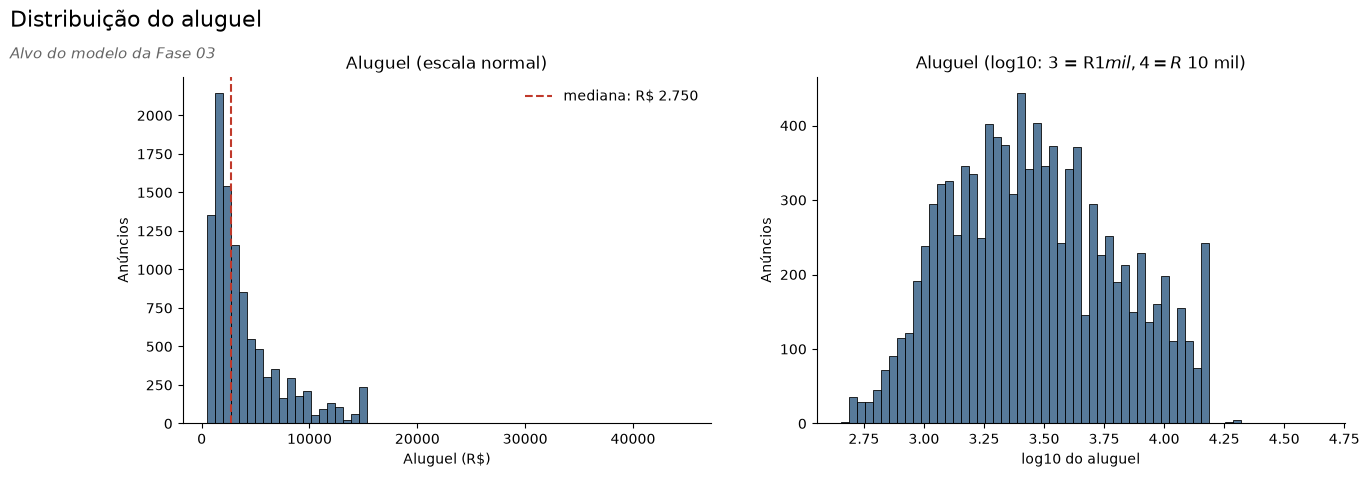

Assimetria: 1.80 | média R$ 3.964 | mediana R$ 2.750


In [16]:
fig, axs = plt.subplots(1, 2, figsize=(15, 4.5))
sns.histplot(df[ALVO], bins=60, color=COR_PRINCIPAL, ax=axs[0])
axs[0].axvline(df[ALVO].median(), color=COR_DESTAQUE, ls='--', label=f'mediana: {reais(df[ALVO].median())}')
axs[0].set(title='Aluguel (escala normal)', xlabel='Aluguel (R$)', ylabel='Anúncios')
axs[0].legend(frameon=False)
sns.histplot(np.log10(df[ALVO]), bins=60, color=COR_PRINCIPAL, ax=axs[1])
axs[1].set(title='Aluguel (log10: 3 = R$ 1 mil, 4 = R$ 10 mil)', xlabel='log10 do aluguel', ylabel='Anúncios')
sns.despine()
titulo('Distribuição do aluguel', 'Alvo do modelo da Fase 03')
salvar('Distribuicao do aluguel')
plt.show()
print(f"Assimetria: {df[ALVO].skew():.2f} | média {reais(df[ALVO].mean())} | mediana {reais(df[ALVO].median())}")

📌 **Nota**
- 🔎 O aluguel tem **cauda longa à direita** (assimetria de **1,80**): média de **R$ 3.964** contra mediana de **R$ 2.750**. Em escala log, a distribuição fica parecida com uma curva normal.
- 🔎 Como é uma **regressão**, não há classes para balancear (item 4.2 da Fase 03).
- ✅ **Decisão:** prever o aluguel **em reais**, como na versão original, que é o número que o negócio usa. Consequência: os aluguéis altos pesam mais no RMSE. Por isso também olhamos o **MAPE** (erro relativo) e o erro **por faixa de área**.

#### Um teto escondido no aluguel?

In [17]:
print('Valores de aluguel mais frequentes:')
display(df[ALVO].value_counts().head(5).to_frame('anúncios'))
faixas_topo = pd.cut(df[ALVO], [10_000, 12_000, 14_000, 14_999, 15_000, 50_000],
                     labels=['10.001 a 12.000', '12.001 a 14.000', '14.001 a 14.999', 'exatamente 15.000', 'acima de 15.000'])
display(faixas_topo.value_counts(sort=False).to_frame('anúncios'))
print(f"Anúncios com aluguel de exatamente R$ 15.000: {(df[ALVO] == 15_000).sum()} ({(df[ALVO] == 15_000).mean():.1%}) | "
      f"acima: {(df[ALVO] > 15_000).sum()}")

Valores de aluguel mais frequentes:


,anúncios
aluguel,
2500,255
2000,240
15000,231
3000,223
3500,215


,anúncios
aluguel,
10.001 a 12.000,283
12.001 a 14.000,184
14.001 a 14.999,13
exatamente 15.000,231
acima de 15.000,12


Anúncios com aluguel de exatamente R$ 15.000: 231 (2.2%) | acima: 12


📌 **Nota: o aluguel parece ter um teto de R$ 15 mil**
- 🔎 **R$ 15.000** é o **3º valor mais comum** da base: **231 anúncios** (**2,2%**), quase tantos quanto R$ 2.500 e R$ 2.000. Entre R$ 14.001 e R$ 14.999 há só **13**, e acima de R$ 15.000, apenas **12**.
- 🔎 Num mercado de verdade, os aluguéis caros vão rareando aos poucos. Uma pilha exatamente em R$ 15.000 indica que a **coleta limitou o preço**: boa parte desses anúncios custa **R$ 15 mil ou mais**.
- ⚠️ A versão original não percebeu o teto.
- ✅ **Decisão:** manter esses anúncios (são imóveis caros de verdade, e removê-los apagaria o alto padrão), mas **avisar** que acima de ~R$ 15 mil o modelo tende a **subestimar** o preço: ele nunca viu o valor real desses imóveis. O app mostra esse aviso quando a sugestão passa de R$ 12 mil.

### 🛡️ Remoção de variáveis com vazamento (*data leakage*)

**Vazamento** acontece quando o modelo recebe uma informação que **contém a resposta** ou que só existe **depois** dela. O modelo parece ótimo no notebook e falha no mundo real, porque essa informação não estará disponível na hora de prever.

Na base, duas colunas são suspeitas: o **seguro-incêndio** e o **total**.

In [18]:
proporcao_seguro = df['seguro_incendio'] / df[ALVO]
print('Seguro-incêndio ÷ aluguel:')
print(proporcao_seguro.describe(percentiles=[0.01, 0.5, 0.99]).round(4).to_string())
print(f"\nCorrelação de Spearman com o aluguel: seguro {teste_spearman(df['seguro_incendio'], df[ALVO])['estatística']:.3f} "
      f"| total {teste_spearman(df['total'], df[ALVO])['estatística']:.3f}")
soma = df[['condominio', ALVO, 'iptu', 'seguro_incendio']].sum(axis=1)
print(f"Total = condomínio + aluguel + IPTU + seguro em {(df['total'] == soma).mean():.1%} das linhas")

Seguro-incêndio ÷ aluguel:
count   10,322.000
mean         0.014
std          0.002
min          0.003
1%           0.007
50%          0.013
99%          0.018
max          0.019

Correlação de Spearman com o aluguel: seguro 0.988 | total 0.969
Total = condomínio + aluguel + IPTU + seguro em 87.1% das linhas


📌 **Nota**
- 🔎 O **seguro-incêndio** é praticamente uma porcentagem fixa do aluguel: mediana de **1,3%**, e 98% dos anúncios ficam entre **0,7%** e **1,8%**. A correlação com o aluguel é de **0,988**.
- 🔎 O **total** é a soma de condomínio + aluguel + IPTU + seguro em **87,1%** das linhas (nas outras há pequenas diferenças da própria base), e tem correlação de **0,969** com o aluguel.
- 🔎 Os dois só existem **depois** que o aluguel é definido: usá-los seria prever o aluguel a partir dele mesmo.
- ✅ **Decisão:** retirar `seguro_incendio` e `total` do modelo, como a versão original já fazia. O item 9 da Fase 03 mostra o tamanho do problema.

## 3 - ANÁLISE EXPLORATÓRIA DOS DADOS (EDA)

### 3.1. Criação das Hipóteses

| # | Hipótese | Pergunta de negócio |
|---|---|---|
| **H1** | O aluguel **varia por cidade**, e São Paulo é a mais cara | 2 e 3 |
| **H2** | Imóveis **maiores** têm aluguel maior | 2 |
| **H3** | Imóveis **mobiliados** têm aluguel maior | 2 |
| **H4** | **Aceitar animal** não muda o aluguel | 2 |
| **H5** | **Casas** têm aluguel maior que apartamentos | 2 |
| **H6** | O **preço por m²** também varia por cidade (não é só o tamanho dos imóveis) | 2 e 3 |
| **H7** | **Casas** são mais baratas que apartamentos **por m²** | 2 |
| **H8** | **Banheiros e vagas** dizem mais sobre o aluguel que o número de **quartos** | 2 |
| **H9** | Apartamentos em **andares mais altos** têm aluguel maior | 2 |
| **H10** | **Condomínio** e **IPTU** acompanham o aluguel | 2 |

Cada hipótese tem um **teste estatístico** e uma medida de **tamanho do efeito**. Com 10 mil anúncios, quase qualquer diferença vira "significativa" (p-valor minúsculo): **o que importa é o tamanho do efeito, não o p**.

### 3.2. Análises individuais

#### H1: O aluguel varia por cidade, e São Paulo é a mais cara

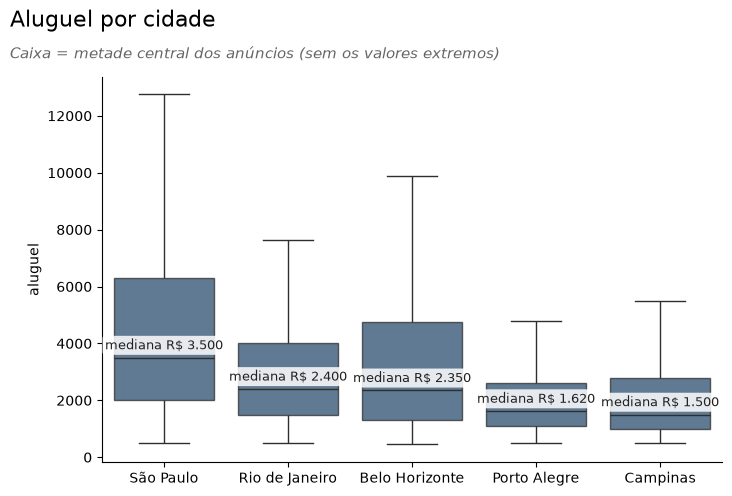

{'teste': 'Kruskal-Wallis',
 'estatística': np.float64(1291.7000664370908),
 'p-valor': np.float64(2.097481026432918e-278),
 'efeito': 'épsilon²',
 'tamanho do efeito': np.float64(0.1251526079291823)}

In [19]:
plot_boxplot_grupos(df, 'cidade', ALVO, 'Aluguel por cidade', 'H1 Aluguel por cidade',
                    subtitulo='Caixa = metade central dos anúncios (sem os valores extremos)')
teste_h1 = teste_kruskal(df[ALVO], df['cidade'])
teste_h1

✅ **Verdadeira.** São Paulo tem o aluguel mediano mais alto (**R$ 3.500**), seguida do Rio de Janeiro (**R$ 2.400**) e de Belo Horizonte (**R$ 2.350**). Porto Alegre (**R$ 1.620**) e Campinas (**R$ 1.500**) custam menos da metade de São Paulo (medianas na tabela da H6).

🧪 **Teste estatístico:** Kruskal-Wallis, H = **1.291,7**, p < 0,001, épsilon² = **0,13** (efeito **médio**; 0,08 = médio, 0,26 = grande). O que importa é o tamanho do efeito, não o p: a cidade explica uma parte relevante das diferenças, mas está longe de explicar tudo.

#### H2: Imóveis maiores têm aluguel maior

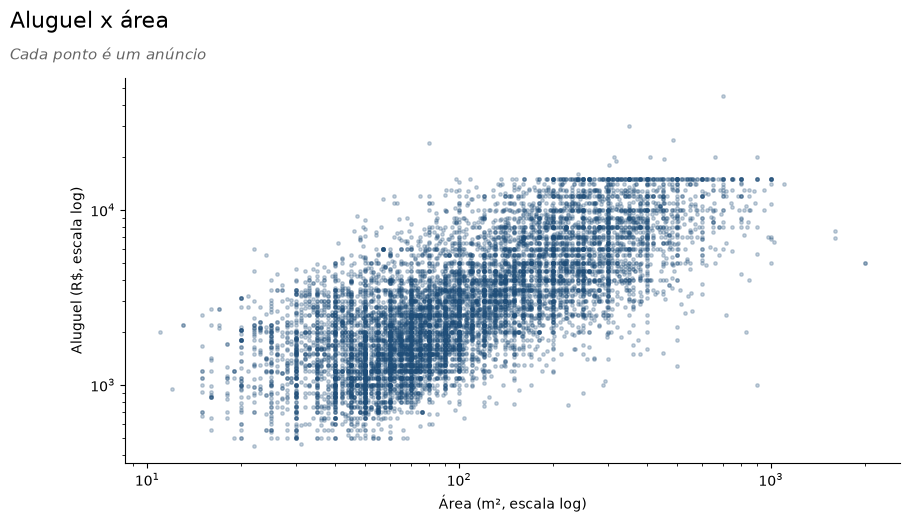

{'teste': 'Spearman',
 'estatística': np.float64(0.7304656419562764),
 'p-valor': np.float64(0.0),
 'efeito': 'rho',
 'tamanho do efeito': np.float64(0.7304656419562764)}

In [20]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(df['area'], df[ALVO], s=6, alpha=0.25, color=COR_PRINCIPAL)
ax.set(xscale='log', yscale='log', xlabel='Área (m², escala log)', ylabel='Aluguel (R$, escala log)')
sns.despine()
titulo('Aluguel x área', 'Cada ponto é um anúncio')
salvar('H2 Aluguel x area')
plt.show()
teste_h2 = teste_spearman(df['area'], df[ALVO])
teste_h2

✅ **Verdadeira.** Quanto maior o imóvel, maior o aluguel, e a relação é **forte**. A nuvem de pontos também mostra que imóveis do mesmo tamanho têm aluguéis muito diferentes: o tamanho sozinho não basta.

🧪 **Teste estatístico:** Spearman, rho = **0,73** (efeito **forte**), p < 0,001. O que importa é o tamanho do efeito, não o p.

#### H3: Imóveis mobiliados têm aluguel maior

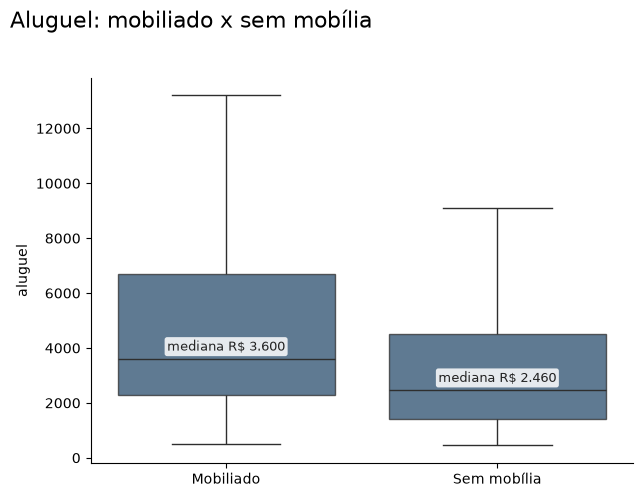

Aluguel mediano: mobiliado R$ 3.600 | sem mobília R$ 2.460
Área mediana: mobiliado 90 m² | sem mobília 95 m²


{'teste': 'Mann-Whitney',
 'estatística': np.float64(12697054.5),
 'p-valor': np.float64(1.0478250388359027e-109),
 'efeito': 'correlação de postos',
 'tamanho do efeito': np.float64(0.29473124550785923)}

In [21]:
rotulo_mobilia = df['mobiliado'].map({1: 'Mobiliado', 0: 'Sem mobília'})
plot_boxplot_grupos(df.assign(mobilia=rotulo_mobilia), 'mobilia', ALVO, 'Aluguel: mobiliado x sem mobília',
                    'H3 Mobiliado')
teste_h3 = teste_mann_whitney(df.loc[df['mobiliado'] == 1, ALVO], df.loc[df['mobiliado'] == 0, ALVO])
print(f"Aluguel mediano: mobiliado {reais(df.loc[df['mobiliado'] == 1, ALVO].median())} | "
      f"sem mobília {reais(df.loc[df['mobiliado'] == 0, ALVO].median())}")
print(f"Área mediana: mobiliado {df.loc[df['mobiliado'] == 1, 'area'].median():.0f} m² | "
      f"sem mobília {df.loc[df['mobiliado'] == 0, 'area'].median():.0f} m²")
teste_h3

✅ **Verdadeira.** O aluguel mediano do imóvel mobiliado é **R$ 3.600**, contra **R$ 2.460** sem mobília (**46%** a mais). A diferença não vem do tamanho: a área mediana é praticamente a mesma (**90 m²** contra **95 m²**).

🧪 **Teste estatístico:** Mann-Whitney, correlação de postos = **0,29** (efeito **moderado**), p < 0,001. O que importa é o tamanho do efeito, não o p.

#### H4: Aceitar animal não muda o aluguel

In [22]:
teste_h4 = teste_mann_whitney(df.loc[df['aceita_animal'] == 1, ALVO], df.loc[df['aceita_animal'] == 0, ALVO])
print(f"Aluguel mediano: aceita {reais(df.loc[df['aceita_animal'] == 1, ALVO].median())} | "
      f"não aceita {reais(df.loc[df['aceita_animal'] == 0, ALVO].median())}")
teste_h4

Aluguel mediano: aceita R$ 2.800 | não aceita R$ 2.500


{'teste': 'Mann-Whitney',
 'estatística': np.float64(10097800.0),
 'p-valor': np.float64(1.370785509180621e-15),
 'efeito': 'correlação de postos',
 'tamanho do efeito': np.float64(0.10983763384700329)}

⚠️ **Quase verdadeira.** Quem aceita animal tem aluguel mediano de **R$ 2.800**, contra **R$ 2.500** de quem não aceita. A diferença existe, mas é **pequena**.

🧪 **Teste estatístico:** Mann-Whitney, correlação de postos = **0,11** (efeito **pequeno**), p < 0,001. O que importa é o tamanho do efeito, não o p: com 10 mil anúncios, até uma diferença pequena dá p minúsculo.

#### H5: Casas têm aluguel maior que apartamentos

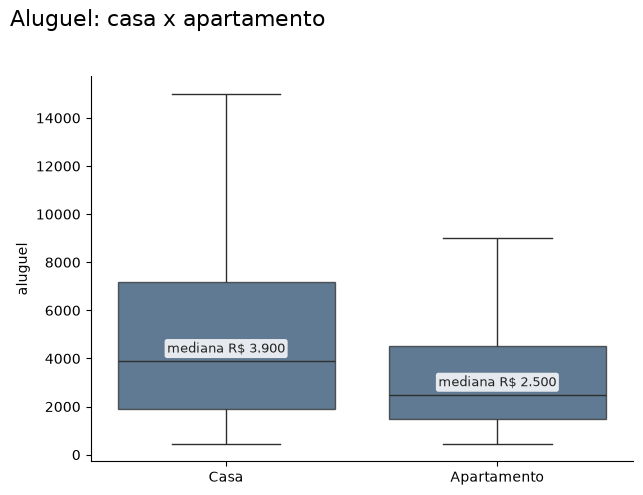

Aluguel mediano: casa R$ 3.900 | apartamento R$ 2.500
Área mediana: casa 200 m² | apartamento 80 m²


{'teste': 'Mann-Whitney',
 'estatística': np.float64(11536787.5),
 'p-valor': np.float64(6.803178546050177e-62),
 'efeito': 'correlação de postos',
 'tamanho do efeito': np.float64(0.22430654602721822)}

In [23]:
rotulo_tipo = df['eh_casa'].map({1: 'Casa', 0: 'Apartamento'})
plot_boxplot_grupos(df.assign(tipo=rotulo_tipo), 'tipo', ALVO, 'Aluguel: casa x apartamento', 'H5 Casa x apartamento')
teste_h5 = teste_mann_whitney(df.loc[df['eh_casa'] == 1, ALVO], df.loc[df['eh_casa'] == 0, ALVO])
print(f"Aluguel mediano: casa {reais(df.loc[df['eh_casa'] == 1, ALVO].median())} | "
      f"apartamento {reais(df.loc[df['eh_casa'] == 0, ALVO].median())}")
print(f"Área mediana: casa {df.loc[df['eh_casa'] == 1, 'area'].median():.0f} m² | "
      f"apartamento {df.loc[df['eh_casa'] == 0, 'area'].median():.0f} m²")
teste_h5

✅ **Verdadeira, mas por causa do tamanho.** O aluguel mediano das casas é **R$ 3.900**, contra **R$ 2.500** dos apartamentos. Só que as casas são bem maiores (área mediana de **200 m²** contra **80 m²**). A H7 compara o preço por m².

🧪 **Teste estatístico:** Mann-Whitney, correlação de postos = **0,22** (efeito **pequeno a moderado**), p < 0,001. O que importa é o tamanho do efeito, não o p.

### 3.3. Análises combinadas

#### H6: O preço por m² também varia por cidade

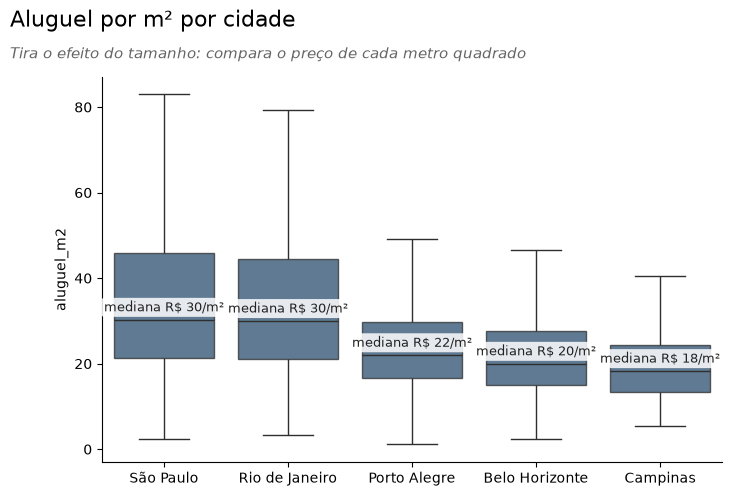

,aluguel_mediano,area_mediana,aluguel_m2_mediano
cidade,,,
São Paulo,"3,500.000",110.000,30.300
Rio de Janeiro,"2,400.000",80.000,30.000
Porto Alegre,"1,620.000",70.000,22.000
Belo Horizonte,"2,350.000",115.000,20.000
Campinas,"1,500.000",75.000,18.300


{'teste': 'Kruskal-Wallis',
 'estatística': np.float64(1231.6801532572567),
 'p-valor': np.float64(2.1588654088499148e-265),
 'efeito': 'épsilon²',
 'tamanho do efeito': np.float64(0.11933728836907827)}

In [24]:
df_m2 = df.assign(aluguel_m2=df[ALVO] / df['area'])
plot_boxplot_grupos(df_m2, 'cidade', 'aluguel_m2', 'Aluguel por m² por cidade', 'H6 Aluguel por m2 por cidade',
                    subtitulo='Tira o efeito do tamanho: compara o preço de cada metro quadrado',
                    formato=lambda v: f'R$ {v:.0f}/m²')
teste_h6 = teste_kruskal(df_m2['aluguel_m2'], df_m2['cidade'])
display(df_m2.groupby('cidade').agg(aluguel_mediano=(ALVO, 'median'), area_mediana=('area', 'median'),
                                    aluguel_m2_mediano=('aluguel_m2', 'median'))
        .sort_values('aluguel_m2_mediano', ascending=False).round(1))
teste_h6

✅ **Verdadeira.** Mesmo comparando o preço de cada metro quadrado, as cidades diferem: **São Paulo (R$ 30,3/m²)** e **Rio de Janeiro (R$ 30,0/m²)** empatam no topo; Porto Alegre (**R$ 22,0**), Belo Horizonte (**R$ 20,0**) e Campinas (**R$ 18,3**) ficam bem abaixo.
- 🔎 Belo Horizonte tem aluguel mediano parecido com o do Rio (R$ 2.350 contra R$ 2.400), mas com imóveis maiores (**115 m²** contra **80 m²**): o metro quadrado em BH custa **um terço menos**.

🧪 **Teste estatístico:** Kruskal-Wallis, H = **1.231,7**, p < 0,001, épsilon² = **0,12** (efeito **médio**). O que importa é o tamanho do efeito, não o p.

#### H7: Casas são mais baratas que apartamentos por m²

In [25]:
teste_h7 = teste_mann_whitney(df_m2.loc[df_m2['eh_casa'] == 1, 'aluguel_m2'], df_m2.loc[df_m2['eh_casa'] == 0, 'aluguel_m2'])
display(df_m2.groupby(rotulo_tipo)['aluguel_m2'].median().round(1).to_frame('aluguel por m² (mediana)'))
teste_h7

,aluguel por m² (mediana)
eh_casa,
Apartamento,28.900
Casa,21.200


{'teste': 'Mann-Whitney',
 'estatística': np.float64(6259974.0),
 'p-valor': np.float64(3.1071687485640416e-136),
 'efeito': 'correlação de postos',
 'tamanho do efeito': np.float64(-0.33567926546621496)}

✅ **Verdadeira.** Por m², a casa é **mais barata**: **R$ 21,2/m²** contra **R$ 28,9/m²** do apartamento. O aluguel total da casa é maior (H5) só porque ela é maior.

🧪 **Teste estatístico:** Mann-Whitney, correlação de postos = **−0,34** (efeito **moderado**, a favor do apartamento), p < 0,001. O que importa é o tamanho do efeito, não o p.

#### H8: Banheiros e vagas dizem mais sobre o aluguel que o número de quartos

,teste,estatística,p-valor
quartos,Spearman,0.599,0.000
banheiros,Spearman,0.716,0.000
vagas,Spearman,0.618,0.000
area,Spearman,0.730,0.000


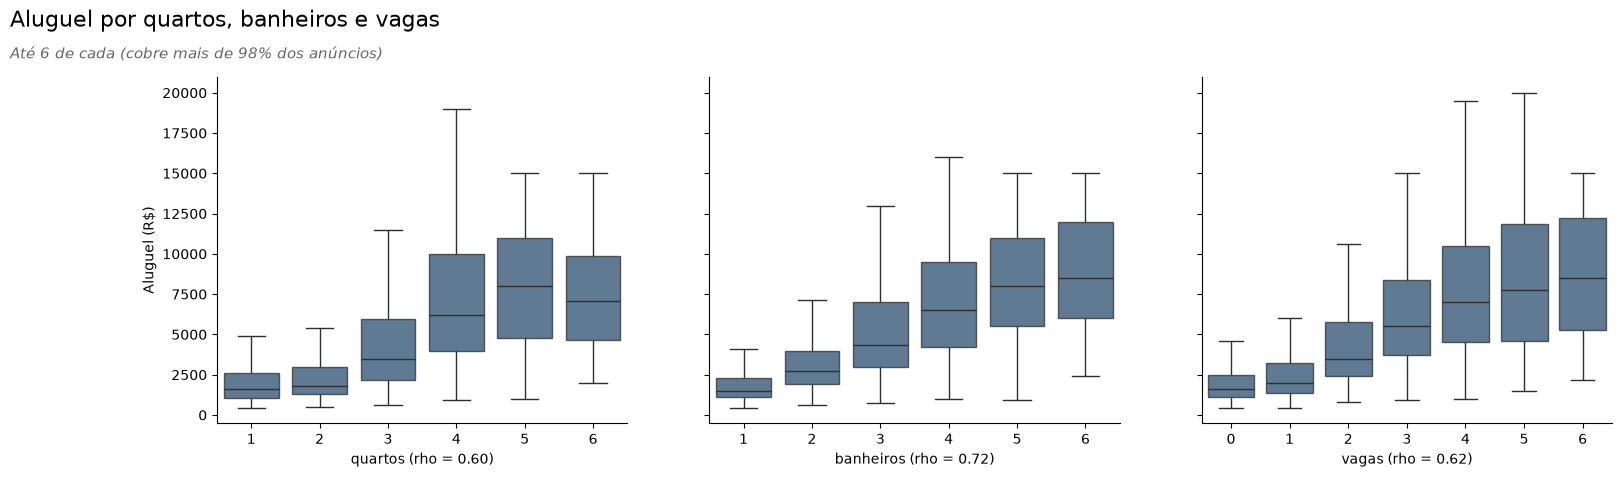

In [26]:
teste_h8 = pd.DataFrame({coluna: teste_spearman(df[coluna], df[ALVO]) for coluna in ['quartos', 'banheiros', 'vagas', 'area']}).T
display(teste_h8[['teste', 'estatística', 'p-valor']])

fig, axs = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
for ax, coluna in zip(axs, ['quartos', 'banheiros', 'vagas']):
    dados = df[df[coluna] <= 6]
    sns.boxplot(data=dados, x=coluna, y=ALVO, color=COR_PRINCIPAL, showfliers=False, ax=ax, boxprops={'alpha': 0.75})
    ax.set(xlabel=f"{coluna} (rho = {teste_h8.loc[coluna, 'estatística']:.2f})", ylabel='Aluguel (R$)')
sns.despine()
titulo('Aluguel por quartos, banheiros e vagas', 'Até 6 de cada (cobre mais de 98% dos anúncios)')
salvar('H8 Quartos banheiros vagas')
plt.show()

✅ **Verdadeira para os banheiros, ⚠️ parcial para as vagas.** O número de **banheiros** acompanha o aluguel quase tanto quanto a própria área (**0,72** contra **0,73**), bem mais que o de **quartos** (**0,60**). As **vagas** ficam no meio (**0,62**), só um pouco acima dos quartos.
- 💡 Banheiros funcionam como um termômetro do **padrão** do imóvel (suítes), não só do tamanho.

🧪 **Teste estatístico:** Spearman, rho = **0,72** (banheiros), **0,62** (vagas) e **0,60** (quartos), todos com p < 0,001. O que importa é o tamanho do efeito, não o p.

#### H9: Apartamentos em andares mais altos têm aluguel maior

In [27]:
apartamentos = df[df['eh_casa'] == 0]
teste_h9 = teste_spearman(apartamentos['andar'], apartamentos[ALVO])
faixas_andar = pd.cut(apartamentos['andar'], [0, 2, 5, 10, 20, 60], labels=['1-2', '3-5', '6-10', '11-20', '21+'],
                      include_lowest=True)
display(apartamentos.groupby(faixas_andar, observed=True).agg(anuncios=(ALVO, 'size'), aluguel_mediano=(ALVO, 'median'),
                                                               area_mediana=('area', 'median')))
teste_h9

,anuncios,aluguel_mediano,area_mediana
andar,,,
1-2,1951,"1,900.000",75.000
3-5,2200,"2,200.000",80.000
6-10,2212,"2,900.000",89.000
11-20,1427,"3,400.000",90.000
21+,162,"4,500.000",99.000


{'teste': 'Spearman',
 'estatística': np.float64(0.28920586672859294),
 'p-valor': np.float64(5.043334140842428e-153),
 'efeito': 'rho',
 'tamanho do efeito': np.float64(0.28920586672859294)}

⚠️ **Parcial.** O aluguel mediano sobe com o andar, de **R$ 1.900** (1º e 2º andares) para **R$ 4.500** (21º andar ou mais). Mas a área também sobe (de **75** para **99 m²**): parte do efeito é tamanho, e prédios altos costumam ser mais novos e ficar em bairros mais caros.

🧪 **Teste estatístico:** Spearman (só apartamentos), rho = **0,29** (efeito **fraco**), p < 0,001. O que importa é o tamanho do efeito, não o p.

#### H10: Condomínio e IPTU acompanham o aluguel

In [28]:
teste_h10 = pd.DataFrame({
    'condomínio (apartamentos)': teste_spearman(apartamentos['condominio'], apartamentos[ALVO]),
    'IPTU (quando informado)': teste_spearman(df.loc[df['iptu'] > 0, 'iptu'], df.loc[df['iptu'] > 0, ALVO]),
}).T
display(teste_h10[['teste', 'estatística', 'p-valor']])
print(f"IPTU zero: {df['iptu_zero'].mean():.1%} dos anúncios | aluguel mediano com IPTU zero "
      f"{reais(df.loc[df['iptu_zero'] == 1, ALVO].median())} x informado {reais(df.loc[df['iptu_zero'] == 0, ALVO].median())}")

,teste,estatística,p-valor
condomínio (apartamentos),Spearman,0.732,0.000
IPTU (quando informado),Spearman,0.747,0.000


IPTU zero: 14.3% dos anúncios | aluguel mediano com IPTU zero R$ 1.800 x informado R$ 3.000


✅ **Verdadeira.** Entre os apartamentos, o **condomínio** acompanha o aluguel com força (**0,73**), e o **IPTU** também, quando informado (**0,75**). Os dois medem o padrão do imóvel e do prédio.
- 🔎 Os **14,3%** de anúncios com IPTU zero têm aluguel mediano bem menor (**R$ 1.800** contra **R$ 3.000**): são imóveis mais simples, isentos de IPTU, ou que não informaram o valor. A variável `iptu_zero` registra essa diferença.

🧪 **Teste estatístico:** Spearman, rho = **0,73** (condomínio) e **0,75** (IPTU), p < 0,001. O que importa é o tamanho do efeito, não o p.

### 3.4. Resumo das Hipóteses

| # | Hipótese | Resultado | Evidência | Tamanho do efeito |
|---|---|---|---|---|
| **H1** | O aluguel varia por cidade, SP é a mais cara | ✅ Verdadeira | Mediana de **R$ 3.500** (SP) a **R$ 1.500** (Campinas) | épsilon² **0,13** (médio) |
| **H2** | Imóveis maiores, aluguel maior | ✅ Verdadeira | Relação forte e crescente | rho **0,73** (forte) |
| **H3** | Mobiliados têm aluguel maior | ✅ Verdadeira | **R$ 3.600** contra **R$ 2.460**, com a mesma área | r **0,29** (moderado) |
| **H4** | Aceitar animal não muda o aluguel | ⚠️ Quase | **R$ 2.800** contra **R$ 2.500** | r **0,11** (pequeno) |
| **H5** | Casas têm aluguel maior | ✅ Verdadeira (pelo tamanho) | **R$ 3.900** contra **R$ 2.500**, mas com mais que o dobro da área | r **0,22** (pequeno a moderado) |
| **H6** | O preço por m² varia por cidade | ✅ Verdadeira | **R$ 30,3/m²** (SP) a **R$ 18,3/m²** (Campinas) | épsilon² **0,12** (médio) |
| **H7** | Casas são mais baratas por m² | ✅ Verdadeira | **R$ 21,2** contra **R$ 28,9/m²** | r **−0,34** (moderado) |
| **H8** | Banheiros e vagas dizem mais que quartos | ✅ Banheiros / ⚠️ vagas | **0,72** e **0,62** contra **0,60** | rho (forte) |
| **H9** | Andares altos, aluguel maior | ⚠️ Parcial | **R$ 1.900** → **R$ 4.500**, mas a área também cresce | rho **0,29** (fraco) |
| **H10** | Condomínio e IPTU acompanham o aluguel | ✅ Verdadeira | **0,73** e **0,75** | rho (forte) |

## 4 - FEATURE ENGINEERING — (engenharia de atributos)

| Variável | Como foi criada | Por quê |
|---|---|---|
| `eh_casa` | 1 quando o andar é "-" | Casa e apartamento térreo não são a mesma coisa (item 2.5.2 e H7) |
| `andar` | "-" vira 0 (só faz sentido junto com `eh_casa`) | O modelo precisa de um número |
| `iptu_zero` | 1 quando o IPTU é zero | Separa "IPTU baixo" de "IPTU não informado ou isento" (H10) |
| `aceita_animal`, `mobiliado` | texto → 1/0 | Modelos só trabalham com números |
| `cidade` | one-hot dentro do `Pipeline` (Fase 03, item 3) | Cada cidade vira uma coluna 0/1 |

> ⚠️ **Não criamos** variáveis a partir do aluguel (ex.: preço por m² médio da cidade calculado na base toda). Isso levaria informação do teste para o treino. O preço por m² aparece só na EDA.

In [29]:
df[FEATURES + [ALVO]].head()

,cidade,area,quartos,banheiros,vagas,andar,aceita_animal,mobiliado,condominio,iptu,eh_casa,iptu_zero,aluguel
0,São Paulo,70,2,1,1,7,1,1,2065,211,0,0,3300
1,São Paulo,320,4,4,0,20,1,0,1200,1750,0,0,4960
2,Porto Alegre,80,1,1,1,6,1,0,1000,0,0,1,2800
3,Porto Alegre,51,2,1,0,2,1,0,270,22,0,0,1112
4,São Paulo,25,1,1,0,1,0,0,0,25,0,0,800


## 5 - EXPLORANDO AS CORRELAÇÕES

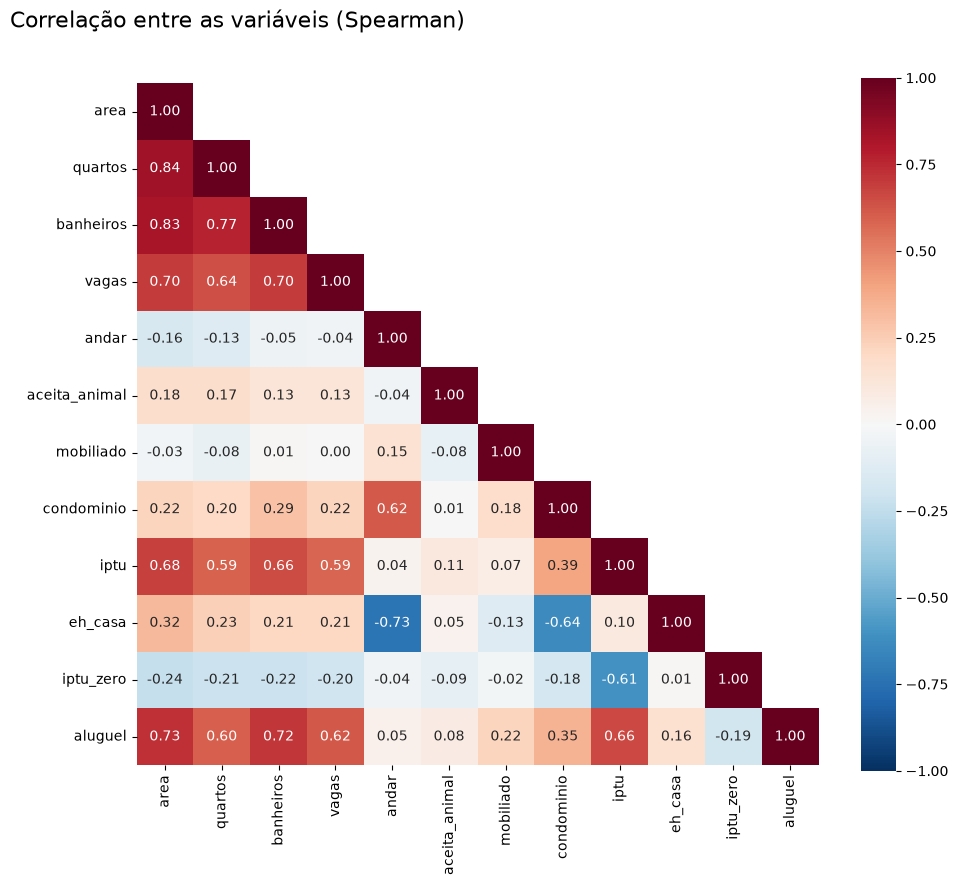

,area,banheiros,iptu,vagas,quartos,condominio,mobiliado,eh_casa,aceita_animal,andar,iptu_zero
correlação com o aluguel,0.730,0.720,0.660,0.620,0.600,0.350,0.220,0.160,0.080,0.050,-0.190


In [30]:
colunas_corr = [coluna for coluna in FEATURES if coluna != 'cidade'] + [ALVO]
correlacao = df[colunas_corr].corr(method='spearman')
plt.figure(figsize=(11, 9))
sns.heatmap(correlacao, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, square=True,
            mask=np.triu(np.ones_like(correlacao, dtype=bool), k=1))
titulo('Correlação entre as variáveis (Spearman)')
salvar('Correlacao entre variaveis')
plt.show()
correlacao[ALVO].drop(ALVO).sort_values(ascending=False).round(2).to_frame('correlação com o aluguel').T

📌 **Nota**
- 🔎 As variáveis mais ligadas ao aluguel são a **área** (**0,73**), os **banheiros** (**0,72**), o **IPTU** (**0,66**), as **vagas** (**0,62**) e os **quartos** (**0,60**).
- 🔎 O **condomínio** aparece com só **0,35** porque inclui as casas, que quase nunca pagam condomínio. Entre os apartamentos, a correlação é de **0,73** (H10).
- 🔎 **Andar** (**0,05**) e **aceitar animal** (**0,08**) quase não se relacionam com o aluguel sozinhos; `iptu_zero` tem correlação negativa (**−0,19**), como visto na H10.
- ⚠️ Área, quartos, banheiros e vagas são muito correlacionados entre si (todos medem tamanho). O modelo da Fase 03 separa o efeito de cada um.

# FASE 03: MODELAGEM DOS DADOS

**Pergunta 1:** *quanto cobrar de aluguel por um imóvel, dadas as suas características?*

O modelo recebe só o que se sabe do imóvel **antes** de definir o preço: cidade, área, quartos, banheiros, vagas, andar, se é casa, mobília, se aceita animal, condomínio e IPTU.

## 1 - Leitura dos dados

In [31]:
X = df[FEATURES]
y = df[ALVO]
print(f'Imóveis: {len(X):,} | Variáveis: {len(FEATURES)}'.replace(',', '.'))
print(FEATURES)

Imóveis: 10.322 | Variáveis: 12
['cidade', 'area', 'quartos', 'banheiros', 'vagas', 'andar', 'aceita_animal', 'mobiliado', 'condominio', 'iptu', 'eh_casa', 'iptu_zero']


## 2 - Valores nulos

In [32]:
X.isna().sum().to_frame('nulos').T

,cidade,area,quartos,banheiros,vagas,andar,aceita_animal,mobiliado,condominio,iptu,eh_casa,iptu_zero
nulos,0,0,0,0,0,0,0,0,0,0,0,0


📌 **Nota**
- 🔎 Nenhuma variável tem valor vazio: não é preciso preencher nada.

## 3 - Transformação

| Variável | Transformação | Motivo |
|---|---|---|
| `cidade` | **One-hot** (uma coluna 0/1 por cidade) | Modelos só trabalham com números |
| Numéricas | **Padronização** (média 0, desvio 1), só nos modelos lineares | A Regressão Linear e o Lasso comparam pesos entre variáveis de escalas diferentes (m², R$, quantidade). As árvores não precisam |

As transformações ficam **dentro de um `Pipeline`**, para que sejam aprendidas só com os dados de treino, inclusive em cada parte da validação cruzada.

In [33]:
NUMERICAS = [coluna for coluna in FEATURES if coluna != 'cidade']

transformacao_linear = ColumnTransformer([
    ('cidade', OneHotEncoder(handle_unknown='ignore'), ['cidade']),
    ('numericas', StandardScaler(), NUMERICAS),
])
transformacao_arvore = ColumnTransformer([
    ('cidade', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['cidade']),
], remainder='passthrough', verbose_feature_names_out=False)

## 4 - Pré-Processamento

### 4.1. Separação do conjunto de dados

Antes de treinar, os dados são divididos em **três partes**, como numa preparação para uma prova:

| Conjunto | Tamanho | Para que serve | Comparação |
|---|---|---|---|
| **Treino** | 60% | o modelo **aprende** os padrões | estudar a matéria |
| **Validação** | 20% | **comparar** algoritmos e ajustar configurações | fazer simulados |
| **Teste** | 20% | **avaliação final**, usada uma única vez no fim | a prova de verdade |

A divisão é **estratificada por cidade**: cada parte tem a mesma proporção de anúncios de cada cidade.

In [34]:
# Primeira divisão: separar o teste (20%); segunda: do restante, treino (75%) e validação (25%) -> 60/20/20
X_treino_val, X_teste, y_treino_val, y_teste = train_test_split(X, y, test_size=0.2, random_state=SEMENTE,
                                                                stratify=X['cidade'])
X_treino, X_validacao, y_treino, y_validacao = train_test_split(X_treino_val, y_treino_val, test_size=0.25,
                                                                random_state=SEMENTE, stratify=X_treino_val['cidade'])
partes = {'Dados originais': (X, y), 'Treino': (X_treino, y_treino), 'Validação': (X_validacao, y_validacao),
          'Teste': (X_teste, y_teste)}
pd.DataFrame({'Imóveis': {nome: len(a) for nome, (a, b) in partes.items()},
              'Shape de X': {nome: a.shape for nome, (a, b) in partes.items()},
              '% da base': {nome: len(a) / len(X) for nome, (a, b) in partes.items()},
              'Aluguel médio': {nome: b.mean() for nome, (a, b) in partes.items()},
              '% São Paulo': {nome: (a['cidade'] == 'São Paulo').mean() for nome, (a, b) in partes.items()}}
             ).style.format({'% da base': '{:.0%}', 'Aluguel médio': reais, '% São Paulo': '{:.1%}'})

,Imóveis,Shape de X,% da base,Aluguel médio,% São Paulo
Dados originais,10322,"(10322, 12)",100%,R$ 3.964,55.3%
Treino,6192,"(6192, 12)",60%,R$ 3.969,55.3%
Validação,2065,"(2065, 12)",20%,R$ 3.977,55.4%
Teste,2065,"(2065, 12)",20%,R$ 3.936,55.4%


📌 **Nota**
- 🔎 **Treino: 6.192 imóveis (60%)**, com os quais os algoritmos aprendem; **validação: 2.065 (20%)**, para compará-los; **teste: 2.065 (20%)**, guardados até o fim.
- 🔎 O aluguel médio é praticamente o mesmo nas três partes (de **R$ 3.936** a **R$ 3.977**), e São Paulo tem **55%** de cada uma, graças à estratificação.

### 4.2. Balancear

🚫 **Não se aplica.** O alvo é um **valor contínuo** (regressão), não uma classe: não há uma classe rara para reforçar com SMOTE ou pesos. A cauda longa dos aluguéis altos (item 2.7) é tratada na avaliação: além do MAE em reais, olhamos o **MAPE** (erro relativo) e o erro **por faixa de área**, para não deixar os imóveis caros dominarem a leitura.

### 4.3. Seleção de Variáveis

Nem toda variável ajuda o modelo da mesma forma. Esta etapa mede a relevância de cada uma usando dois métodos diferentes, que olham o problema por ângulos distintos:

| Método | Como funciona | Em palavras simples |
|---|---|---|
| **Random Forest** | treina várias árvores de decisão e mede o quanto cada variável ajuda a reduzir o erro da previsão | "quais perguntas o modelo mais usou para decidir" |
| **Informação Mútua** | mede o quanto conhecer a variável reduz a incerteza sobre o alvo | "quanto essa variável, sozinha, conta sobre o aluguel" |

Como o alvo é um **valor contínuo**, usamos as versões de **regressão**: `RandomForestRegressor` e `mutual_info_regression`.

> ⚠️ A versão original usava um `RandomForestClassifier`, que trata **cada valor de aluguel como uma classe diferente** (mais de mil "classes"). As importâncias dela não mediam a relação com o preço.

> Um cuidado técnico: os dois métodos só aceitam números. Por isso usamos a **matriz transformada** (a cidade vira colunas 0/1, item 3). O pré-processador é ajustado **só no treino**, para que nenhuma informação do teste entre na seleção. Não há balanceamento a reaplicar (item 4.2).

treino transformado .... (6192, 16)


area                    0.507
iptu                    0.186
condominio              0.104
andar                   0.047
banheiros               0.038
vagas                   0.032
quartos                 0.025
mobiliado               0.022
cidade_São Paulo        0.011
aceita_animal           0.010
cidade_Belo Horizonte   0.005
cidade_Rio de Janeiro   0.004
eh_casa                 0.003
cidade_Porto Alegre     0.003
cidade_Campinas         0.003
iptu_zero               0.002


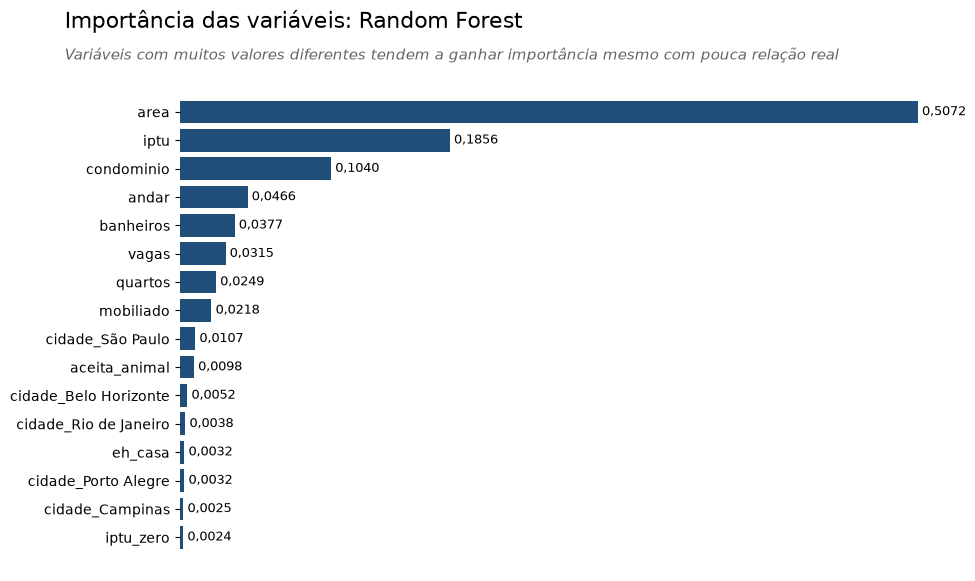

In [35]:
# Transformando o treino em números (ajuste só no treino)
prep_sel = clone(transformacao_arvore)
X_treino_t = pd.DataFrame(prep_sel.fit_transform(X_treino), index=X_treino.index,
                          columns=prep_sel.get_feature_names_out())
print(f'treino transformado .... {X_treino_t.shape}')

# Random Forest - classificação das melhores variáveis
importances = importancia_random_forest(X_treino_t, y_treino, tipo='regressao', semente=SEMENTE)
print(importances.head(20).round(4).to_string())

plot_barras_h(importances.head(20), 'Importância das variáveis: Random Forest', 'Importancia RF (selecao)',
              subtitulo='Variáveis com muitos valores diferentes tendem a ganhar importância mesmo com pouca relação real',
              formato=lambda v: f'{v:.4f}'.replace('.', ','))

🎯 RANKING DE FEATURES POR MUTUAL INFORMATION (16 colunas):
                  feature  score
0                    area  0.412
1                    iptu  0.378
2               banheiros  0.363
3              condominio  0.345
4                 quartos  0.252
5                   vagas  0.250
6                   andar  0.080
7        cidade_São Paulo  0.059
8               mobiliado  0.048
9               iptu_zero  0.030
10    cidade_Porto Alegre  0.029
11        cidade_Campinas  0.025
12                eh_casa  0.018
13  cidade_Belo Horizonte  0.017
14  cidade_Rio de Janeiro  0.010
15          aceita_animal  0.000

colunas com informação mútua igual a zero: 1 de 16

🏆 TOP 5 FEATURES SELECIONADAS:
1. area: 0.411695
2. iptu: 0.378290
3. banheiros: 0.363022
4. condominio: 0.345459
5. quartos: 0.251671

📊 Shape original: (6192, 16)
📊 Shape após seleção: (6192, 5)
📊 Features selecionadas: ['area', 'iptu', 'banheiros', 'condominio', 'quartos']


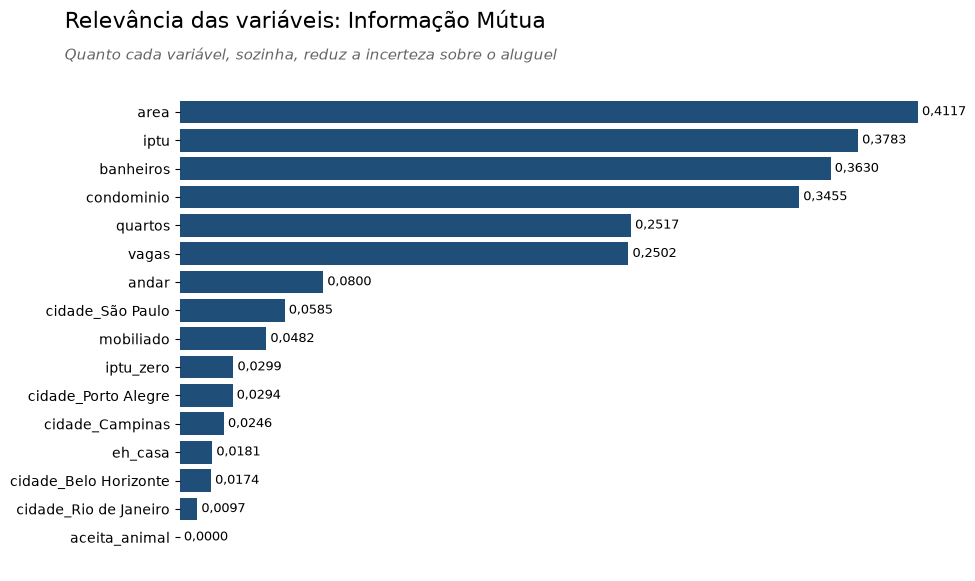

In [36]:
# Informação Mútua - ranking de todas as colunas e seleção das 5 melhores
df_scores, selector = selecao_features(X_treino_t, y_treino, k=5, tipo='regressao', semente=SEMENTE)

print(f'🎯 RANKING DE FEATURES POR MUTUAL INFORMATION ({X_treino_t.shape[1]} colunas):')
print('=' * 50)
print(df_scores.round(4).to_string())
print(f"\ncolunas com informação mútua igual a zero: {(df_scores['score'] == 0).sum()} de {len(df_scores)}")

print('\n🏆 TOP 5 FEATURES SELECIONADAS:')
print('=' * 50)
top_5_features = df_scores.head(5)['feature'].tolist()
for i, (feature, score) in enumerate(df_scores.head(5).itertuples(index=False), 1):
    print(f'{i}. {feature}: {score:.6f}')

X_treino_selecionado = selector.transform(X_treino_t)
print(f'\n📊 Shape original: {X_treino_t.shape}')
print(f'📊 Shape após seleção: {X_treino_selecionado.shape}')
print(f'📊 Features selecionadas: {top_5_features}')

plot_barras_h(df_scores.set_index('feature')['score'], 'Relevância das variáveis: Informação Mútua',
              'Informacao mutua (selecao)', subtitulo='Quanto cada variável, sozinha, reduz a incerteza sobre o aluguel',
              formato=lambda v: f'{v:.4f}'.replace('.', ','))

In [37]:
# Comparação dos dois rankings
comparacao_selecao = pd.DataFrame({
    'posição RF': importances.rank(ascending=False).astype(int),
    'posição Informação Mútua': df_scores.set_index('feature')['score'].rank(ascending=False, method='first').astype(int),
}).sort_values('posição RF')
comparacao_selecao

,posição RF,posição Informação Mútua
area,1,1
iptu,2,2
condominio,3,4
andar,4,7
banheiros,5,3
vagas,6,6
quartos,7,5
mobiliado,8,9
cidade_São Paulo,9,8
aceita_animal,10,16


📌 **Nota**
- 🔎 Os dois métodos concordam no principal: **área** (1º lugar nos dois) e **IPTU** (2º nos dois) são as variáveis mais relevantes. Em seguida vêm o **condomínio**, os **banheiros**, as **vagas** e os **quartos**.
- 🔎 O Random Forest dá à área **0,51** de importância, metade de tudo, e põe o **andar** em 4º lugar. A Informação Mútua põe o andar só em 7º: variáveis com muitos valores diferentes tendem a ganhar importância no Random Forest, o mesmo alerta do gráfico.
- 🔎 Cada **cidade** vira uma coluna 0/1 e parece fraca **sozinha**. A importância por permutação da Fase 04 mede `cidade` como um bloco.
- 🔎 Só **`aceita_animal`** tem informação mútua **zero**, o que confirma a H4 (efeito pequeno).
- ✅ **Decisão:** a confirmação abaixo mostra se vale ficar só com as 5 melhores ou manter todas.

#### Confirmação: o modelo melhora com as variáveis criadas e com as mais fracas?

Os dois métodos acima olham cada coluna isoladamente. Como confirmação, comparamos o mesmo modelo (HistGradientBoosting) com **3 conjuntos de variáveis**, na validação cruzada do treino.

In [38]:
validacao = KFold(n_splits=5, shuffle=True, random_state=SEMENTE)
conjuntos = {
    'Top 5 da Informação Mútua': None,
    'Originais (10)': FEATURES_ORIGINAIS,
    'Originais + criadas (12)': FEATURES,
}
confirmacao = {}
for nome, colunas in conjuntos.items():
    if colunas is None:  # o top 5 já está na matriz transformada (colunas 0/1 de cidade incluídas)
        dados_treino = X_treino_t[top_5_features]
        modelo = HistGradientBoostingRegressor(random_state=SEMENTE)
    else:
        dados_treino = X_treino[colunas]
        transformacao = ColumnTransformer([('cidade', OneHotEncoder(handle_unknown='ignore', sparse_output=False),
                                            ['cidade'])], remainder='passthrough')
        modelo = Pipeline([('transformacao', transformacao), ('modelo', HistGradientBoostingRegressor(random_state=SEMENTE))])
    cv = cross_validate(modelo, dados_treino, y_treino, cv=validacao, scoring=['neg_mean_absolute_error', 'r2'])
    confirmacao[nome] = {'MAE (R$)': -cv['test_neg_mean_absolute_error'].mean(),
                         'desvio MAE (R$)': cv['test_neg_mean_absolute_error'].std(), 'R²': cv['test_r2'].mean()}
pd.DataFrame(confirmacao).T.round(3)

,MAE (R$),desvio MAE (R$),R²
Top 5 da Informação Mútua,"1,436.371",46.887,0.568
Originais (10),"1,337.487",33.626,0.604
Originais + criadas (12),"1,337.487",33.626,0.604


📌 **Nota**
- 🔎 Ficar só com as **5 melhores** da Informação Mútua **piora** o erro: de **R$ 1.337** para **R$ 1.436** (R² de 0,60 para **0,57**). As variáveis "fracas" (cidade, mobília, andar) acrescentam informação que as 5 maiores não têm.
- 🔎 As variáveis criadas (`eh_casa` e `iptu_zero`) dão **exatamente o mesmo resultado** que as originais. Faz sentido: andar 0 só aparece nas casas, e IPTU 0 já está na coluna `iptu`. As árvores fazem essas divisões sozinhas.
- ✅ **Decisão:** manter as **12 variáveis**. As duas criadas não mudam o erro das árvores, mas deixam o modelo **mais fácil de explicar** (casa x apartamento) e ajudam os modelos lineares, que não fazem essas divisões.

## 5 - Treinamento dos Algoritmos de Machine Learning

**Treinar** um algoritmo é mostrar a ele exemplos (os imóveis do treino, com o aluguel real) para que ele aprenda os padrões. Depois, pedimos que ele **preveja** imóveis que nunca viu (a **validação**) e comparamos as previsões com a resposta verdadeira (o **gabarito**).

**Como vamos medir o desempenho** (função `ml_error`, `src/avaliacao.py`):

| Métrica | Pergunta que ela responde |
|---|---|
| **MAE** | Em média, quantos **reais** a previsão erra? |
| **MAPE** | Em média, quanto o erro representa **em relação ao aluguel real**? (R$ 300 de erro num aluguel de R$ 1.500 = 20%) |
| **RMSE** | Como o MAE, mas **pune mais os erros grandes** |
| **R²** | Quanto das diferenças de aluguel entre os imóveis o modelo **explica** (0 = nada, 1 = tudo) |
| **MPE** | O modelo tende a **superestimar** (positivo) ou **subestimar** (negativo)? |

**Régua de comparação:** o modelo **Média** prevê sempre o aluguel médio do treino. Todo algoritmo útil precisa superá-lo.

Cada algoritmo é avaliado pela função `relatorio_validacao`, que mostra sempre as mesmas peças: amostra gabarito × previsão, métricas, **MAE no treino × validação** (para detectar **sobreajuste**, quando o modelo "decora" o treino) e os gráficos de previsto × real e de distribuição do erro.

### Média (referência)

O modelo de **referência** prevê sempre o **aluguel médio** do treino, para qualquer imóvel. Ele não aprende nada: serve de piso de comparação.

Média (referência) treinado em 0.0s

AMOSTRA: GABARITO x PREVISÃO DA MÁQUINA (aluguel em R$)


,Gabarito,Previsão da máquina,Erro (R$)
0,915.000,"3,969.000","3,054.000"
1,"1,490.000","3,969.000","2,479.000"
2,"4,600.000","3,969.000",-631.000
3,"15,000.000","3,969.000","-11,031.000"
4,"7,600.000","3,969.000","-3,631.000"
5,"6,500.000","3,969.000","-2,531.000"


MÉTRICAS DE VALIDAÇÃO: Média (referência)
MAE (R$)  2,566.269
MAPE          1.090
RMSE (R$) 3,408.461
R²           -0.000
MPE           0.819

MAE no treino: R$ 2.576 | na validação: R$ 2.566 | diferença: -10 R$


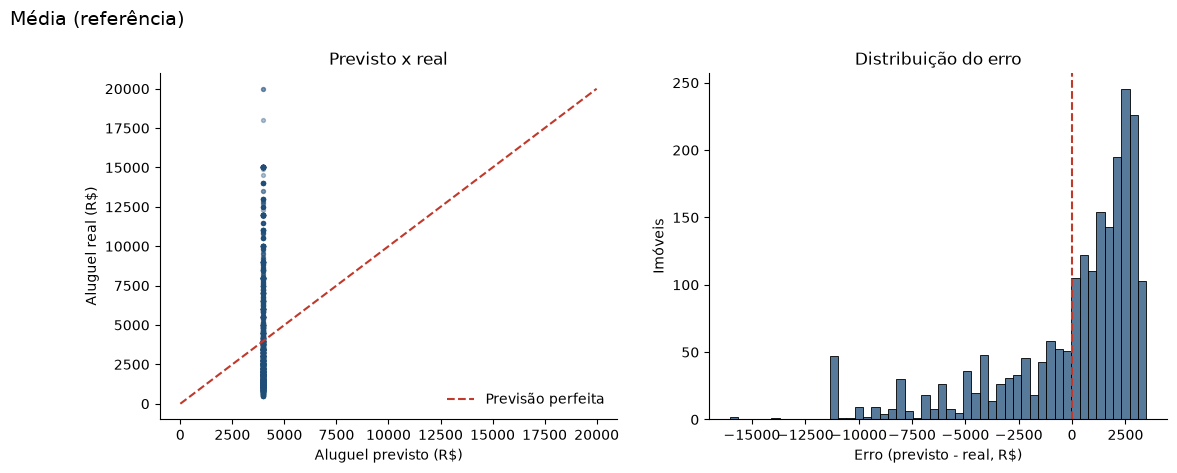

In [39]:
model_media = DummyRegressor()

t0 = time.time()
model_media.fit(X_treino, y_treino)
print(f'Média (referência) treinado em {time.time() - t0:.1f}s' + chr(10))

# Avaliação na VALIDAÇÃO (imóveis que o modelo não viu)
metricas_media, previsto_media = relatorio_validacao('Média (referência)', model_media, X_treino, y_treino, X_validacao, y_validacao)

In [40]:
# Como a versão original calculava o "modelo da média": média do aluguel por área calculada NA PRÓPRIA VALIDAÇÃO
media_por_area_v1 = y_validacao.groupby(X_validacao['area']).transform('mean')
ml_error('Média por área da v1 (usa o gabarito)', y_validacao, media_por_area_v1).round(3)

,MAE (R$),MAPE,RMSE (R$),R²,MPE
Média por área da v1 (usa o gabarito),"1,410.383",0.493,"2,088.620",0.625,0.280


📌 **Nota**
- 🔎 Prevendo sempre a média do treino (**R$ 3.969**), o erro é de **R$ 2.566** (MAE) e o **R² é zero**: o modelo não explica nada. O **MAPE de 109%** mostra que, para os aluguéis baratos, chutar a média erra mais que o próprio aluguel.
- ⚠️ **A versão original** calculava o "modelo da média" com a **média do aluguel por área nos próprios imóveis da validação**. Ou seja, usava o **gabarito** para prever. Reproduzindo a conta, o R² sobe para **0,625** e o MAE cai para **R$ 1.410**, melhor que a Regressão Linear abaixo. Por isso, na v1, o "modelo da média" parecia o melhor de todos.
- ✅ **Na v2**, a referência é a média do **treino** (`DummyRegressor`), que não conhece as respostas.

### Regressão Linear

A **Regressão Linear** soma o efeito de cada variável com um **peso** (uma reta em várias dimensões). É o modelo mais simples e **fácil de explicar**.

Regressão Linear treinado em 0.0s

AMOSTRA: GABARITO x PREVISÃO DA MÁQUINA (aluguel em R$)


,Gabarito,Previsão da máquina,Erro (R$)
0,915.000,949.000,34.000
1,"1,490.000","1,565.000",75.000
2,"4,600.000","4,634.000",34.000
3,"15,000.000","13,022.000","-1,978.000"
4,"7,600.000","3,213.000","-4,387.000"
5,"6,500.000","3,705.000","-2,795.000"


MÉTRICAS DE VALIDAÇÃO: Regressão Linear
MAE (R$)  1,431.735
MAPE          0.431
RMSE (R$) 2,200.524
R²            0.583
MPE           0.201

MAE no treino: R$ 1.431 | na validação: R$ 1.432 | diferença: +1 R$


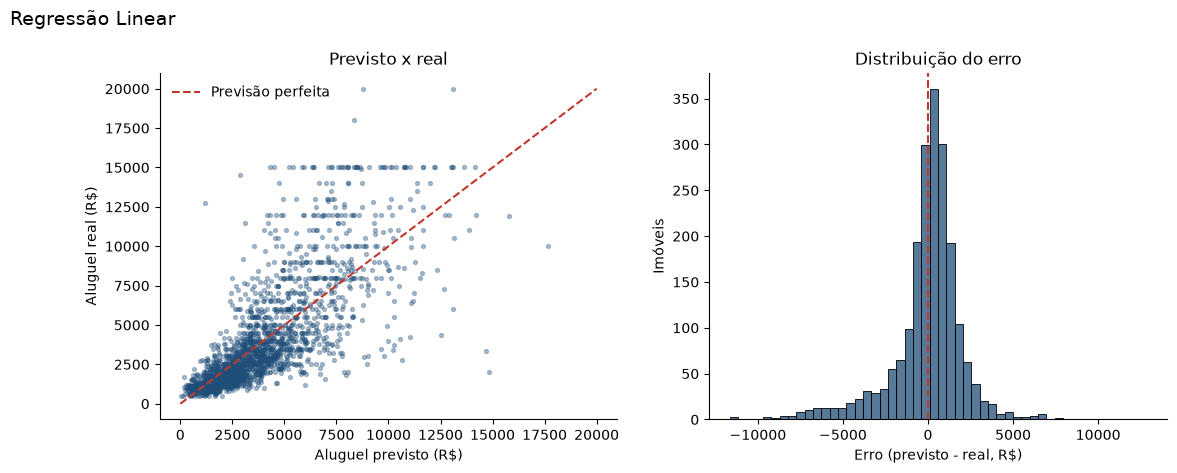

In [41]:
model_lr = Pipeline([('transformacao', transformacao_linear), ('modelo', LinearRegression())])

t0 = time.time()
model_lr.fit(X_treino, y_treino)
print(f'Regressão Linear treinado em {time.time() - t0:.1f}s' + chr(10))

# Avaliação na VALIDAÇÃO (imóveis que o modelo não viu)
metricas_lr, previsto_lr = relatorio_validacao('Regressão Linear', model_lr, X_treino, y_treino, X_validacao, y_validacao)

📌 **Nota**
- 🔎 A Regressão Linear **reduz o erro quase à metade**: MAE de **R$ 1.432** e R² de **0,58**.
- 🔎 O **MPE de +20%** mostra que ela **superestima** os aluguéis baratos: uma reta não acompanha bem a cauda longa dos preços.
- ✅ **Sem sobreajuste:** o erro no treino (**R$ 1.431**) é igual ao da validação.

### Lasso

O **Lasso** é uma regressão linear **regularizada**: ele "encolhe" os pesos e pode zerar os de variáveis pouco úteis, o que evita exagerar padrões do treino.

Lasso treinado em 0.1s

AMOSTRA: GABARITO x PREVISÃO DA MÁQUINA (aluguel em R$)


,Gabarito,Previsão da máquina,Erro (R$)
0,915.000,952.000,37.000
1,"1,490.000","1,566.000",76.000
2,"4,600.000","4,635.000",35.000
3,"15,000.000","13,017.000","-1,983.000"
4,"7,600.000","3,210.000","-4,390.000"
5,"6,500.000","3,704.000","-2,796.000"


MÉTRICAS DE VALIDAÇÃO: Lasso
MAE (R$)  1,431.239
MAPE          0.430
RMSE (R$) 2,200.436
R²            0.583
MPE           0.202

MAE no treino: R$ 1.430 | na validação: R$ 1.431 | diferença: +1 R$


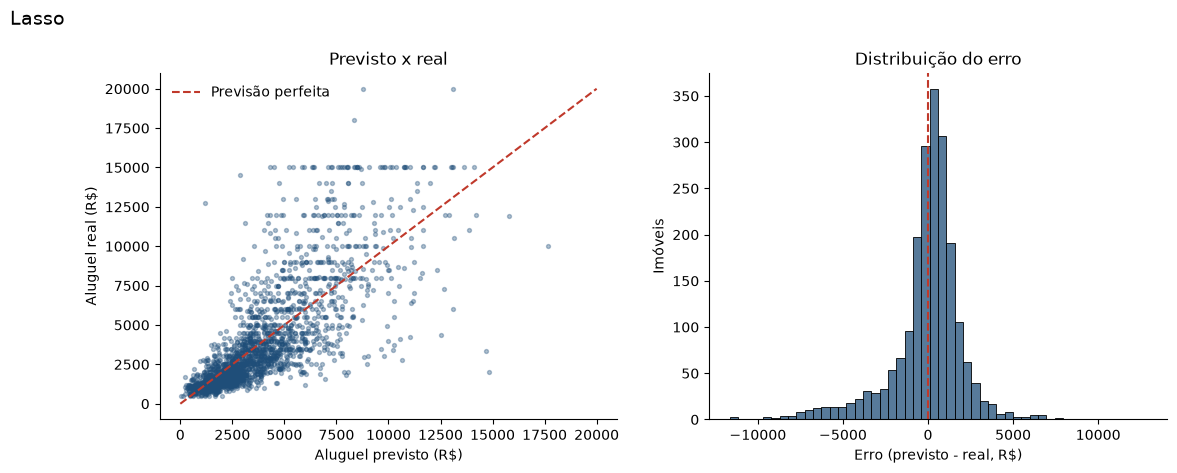

In [42]:
model_lasso = Pipeline([('transformacao', transformacao_linear), ('modelo', Lasso(alpha=1.0, random_state=SEMENTE))])

t0 = time.time()
model_lasso.fit(X_treino, y_treino)
print(f'Lasso treinado em {time.time() - t0:.1f}s' + chr(10))

# Avaliação na VALIDAÇÃO (imóveis que o modelo não viu)
metricas_lasso, previsto_lasso = relatorio_validacao('Lasso', model_lasso, X_treino, y_treino, X_validacao, y_validacao)

📌 **Nota**
- 🔎 O Lasso ficou **igual** à Regressão Linear (MAE de **R$ 1.431**, R² de **0,58**). Com 16 colunas e 6 mil imóveis, não há excesso de variáveis para a regularização cortar.

### Random Forest

O **Random Forest** treina **centenas de árvores de decisão independentes**, cada uma com uma parte dos dados, e tira a **média** das previsões, como pedir a opinião de vários especialistas.

Random Forest treinado em 3.4s

AMOSTRA: GABARITO x PREVISÃO DA MÁQUINA (aluguel em R$)


,Gabarito,Previsão da máquina,Erro (R$)
0,915.000,798.000,-117.000
1,"1,490.000","1,931.000",441.000
2,"4,600.000","7,718.000","3,118.000"
3,"15,000.000","9,148.000","-5,852.000"
4,"7,600.000","3,797.000","-3,803.000"
5,"6,500.000","4,083.000","-2,417.000"


MÉTRICAS DE VALIDAÇÃO: Random Forest
MAE (R$)  1,343.154
MAPE          0.379
RMSE (R$) 2,119.293
R²            0.613
MPE           0.180

MAE no treino: R$ 490 | na validação: R$ 1.343 | diferença: +853 R$


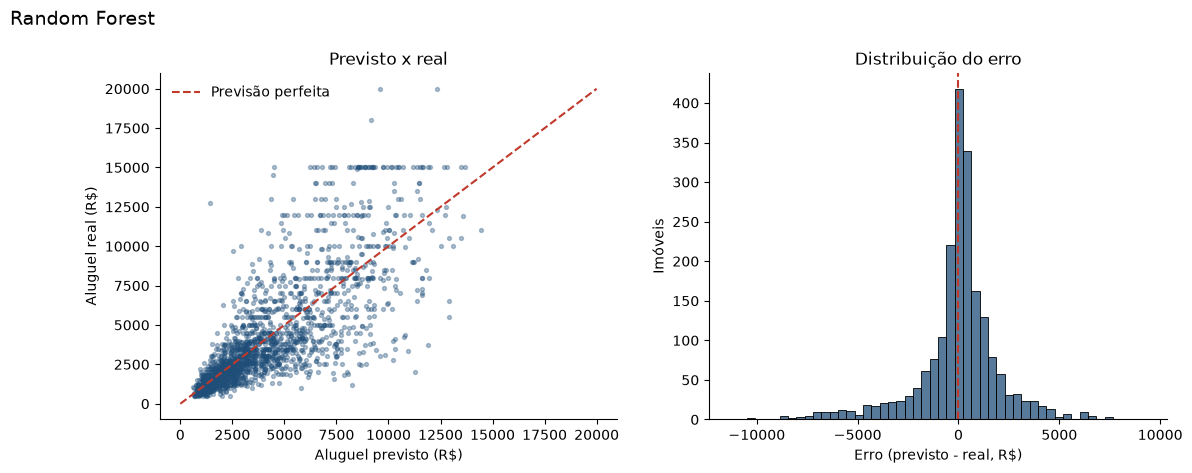

In [43]:
model_rf = Pipeline([('transformacao', transformacao_arvore), ('modelo', RandomForestRegressor(random_state=SEMENTE, n_jobs=N_JOBS))])

t0 = time.time()
model_rf.fit(X_treino, y_treino)
print(f'Random Forest treinado em {time.time() - t0:.1f}s' + chr(10))

# Avaliação na VALIDAÇÃO (imóveis que o modelo não viu)
metricas_rf, previsto_rf = relatorio_validacao('Random Forest', model_rf, X_treino, y_treino, X_validacao, y_validacao)

📌 **Nota**
- 🔎 O Random Forest melhora em relação aos lineares: MAE de **R$ 1.343**, R² de **0,61** e MAPE de **37,9%**.
- ⚠️ **Sobreajuste forte:** o erro no treino é de só **R$ 490**, contra **R$ 1.343** na validação. As árvores "decoram" os imóveis do treino.

### XGBoost

O **XGBoost** constrói **árvores em sequência**: cada nova árvore olha para os erros das anteriores e tenta corrigi-los.

XGBoost treinado em 1.0s

AMOSTRA: GABARITO x PREVISÃO DA MÁQUINA (aluguel em R$)


,Gabarito,Previsão da máquina,Erro (R$)
0,915.000,949.000,34.000
1,"1,490.000","1,995.000",505.000
2,"4,600.000","8,621.000","4,021.000"
3,"15,000.000","11,098.000","-3,902.000"
4,"7,600.000","3,451.000","-4,149.000"
5,"6,500.000","4,147.000","-2,353.000"


MÉTRICAS DE VALIDAÇÃO: XGBoost
MAE (R$)  1,361.983
MAPE          0.374
RMSE (R$) 2,156.708
R²            0.600
MPE           0.157

MAE no treino: R$ 601 | na validação: R$ 1.362 | diferença: +761 R$


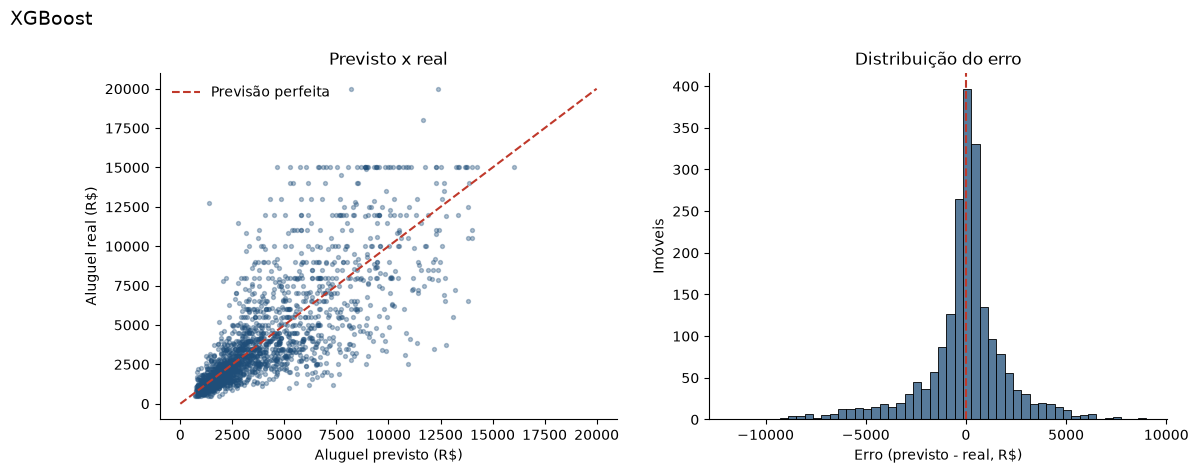

In [44]:
model_xgb = Pipeline([('transformacao', transformacao_arvore), ('modelo', xgb.XGBRegressor(random_state=SEMENTE, n_jobs=N_JOBS))])

t0 = time.time()
model_xgb.fit(X_treino, y_treino)
print(f'XGBoost treinado em {time.time() - t0:.1f}s' + chr(10))

# Avaliação na VALIDAÇÃO (imóveis que o modelo não viu)
metricas_xgb, previsto_xgb = relatorio_validacao('XGBoost', model_xgb, X_treino, y_treino, X_validacao, y_validacao)

📌 **Nota**
- 🔎 O XGBoost fica um pouco atrás do Random Forest: MAE de **R$ 1.362** e R² de **0,60**.
- ⚠️ **Sobreajuste também forte:** **R$ 601** no treino contra **R$ 1.362** na validação.

### LightGBM

O **LightGBM** segue a mesma ideia do XGBoost, mas cresce cada árvore pelo galho mais promissor, o que o deixa **mais rápido**.

LightGBM treinado em 0.3s

AMOSTRA: GABARITO x PREVISÃO DA MÁQUINA (aluguel em R$)


,Gabarito,Previsão da máquina,Erro (R$)
0,915.000,"1,001.000",86.000
1,"1,490.000","1,943.000",453.000
2,"4,600.000","7,910.000","3,310.000"
3,"15,000.000","10,478.000","-4,522.000"
4,"7,600.000","3,393.000","-4,207.000"
5,"6,500.000","3,333.000","-3,167.000"


MÉTRICAS DE VALIDAÇÃO: LightGBM
MAE (R$)  1,316.779
MAPE          0.373
RMSE (R$) 2,075.747
R²            0.629
MPE           0.169

MAE no treino: R$ 1.015 | na validação: R$ 1.317 | diferença: +302 R$


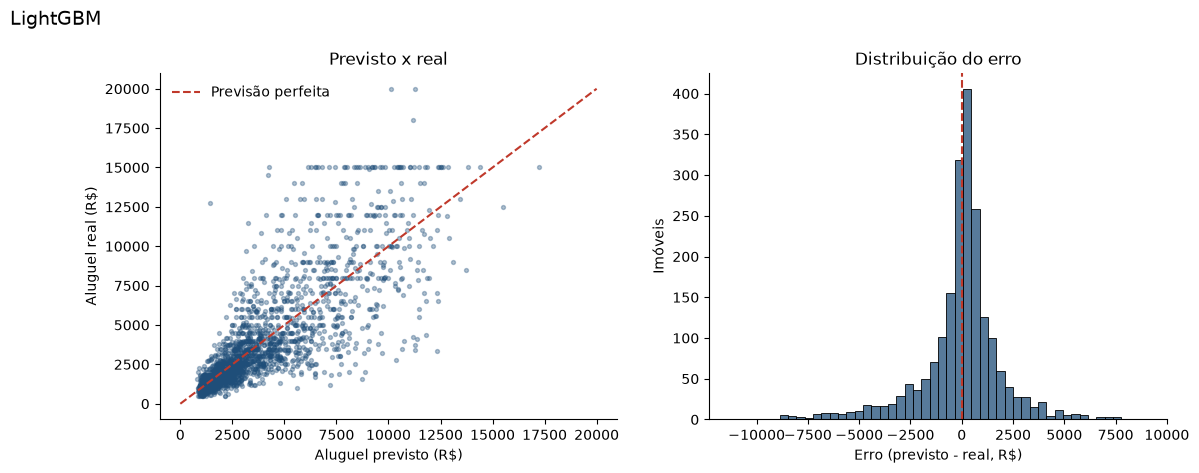

In [45]:
model_lgbm = Pipeline([('transformacao', transformacao_arvore), ('modelo', lgb.LGBMRegressor(random_state=SEMENTE, n_jobs=N_JOBS, verbose=-1))])

t0 = time.time()
model_lgbm.fit(X_treino, y_treino)
print(f'LightGBM treinado em {time.time() - t0:.1f}s' + chr(10))

# Avaliação na VALIDAÇÃO (imóveis que o modelo não viu)
metricas_lgbm, previsto_lgbm = relatorio_validacao('LightGBM', model_lgbm, X_treino, y_treino, X_validacao, y_validacao)

📌 **Nota**
- 🔎 O LightGBM chega a um MAE de **R$ 1.317** e R² de **0,63**, o 2º melhor.
- ✅ **Sobreajuste moderado:** **R$ 1.015** no treino contra **R$ 1.317** na validação, bem menor que o do Random Forest e o do XGBoost.

### HistGradientBoosting

O **HistGradientBoosting** (do scikit-learn) também constrói árvores em sequência, agrupando os valores em faixas para ganhar velocidade.

HistGradientBoosting treinado em 1.0s

AMOSTRA: GABARITO x PREVISÃO DA MÁQUINA (aluguel em R$)


,Gabarito,Previsão da máquina,Erro (R$)
0,915.000,"1,004.000",89.000
1,"1,490.000","1,835.000",345.000
2,"4,600.000","8,285.000","3,685.000"
3,"15,000.000","9,034.000","-5,966.000"
4,"7,600.000","3,513.000","-4,087.000"
5,"6,500.000","3,395.000","-3,105.000"


MÉTRICAS DE VALIDAÇÃO: HistGradientBoosting
MAE (R$)  1,308.737
MAPE          0.370
RMSE (R$) 2,065.901
R²            0.633
MPE           0.169

MAE no treino: R$ 1.016 | na validação: R$ 1.309 | diferença: +293 R$


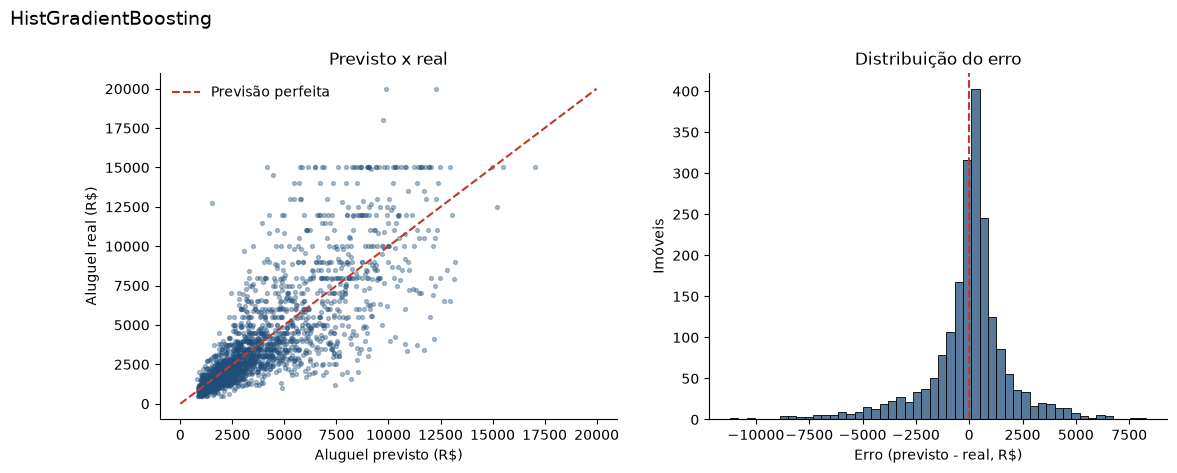

In [46]:
model_hgb = Pipeline([('transformacao', transformacao_arvore), ('modelo', HistGradientBoostingRegressor(random_state=SEMENTE))])

t0 = time.time()
model_hgb.fit(X_treino, y_treino)
print(f'HistGradientBoosting treinado em {time.time() - t0:.1f}s' + chr(10))

# Avaliação na VALIDAÇÃO (imóveis que o modelo não viu)
metricas_hgb, previsto_hgb = relatorio_validacao('HistGradientBoosting', model_hgb, X_treino, y_treino, X_validacao, y_validacao)

📌 **Nota**
- 🔎 O HistGradientBoosting tem o **menor erro** da validação: MAE de **R$ 1.309**, R² de **0,63** e MAPE de **37,0%** (em média, o erro é 37% do aluguel real).
- ✅ Sobreajuste moderado (**R$ 1.016** no treino), igual ao do LightGBM.

### Validação cruzada

A validação é **uma** divisão dos dados. Para saber se as diferenças entre os algoritmos são **reais** e não sorte da divisão, repetimos a comparação com **validação cruzada de 5 partes** em treino + validação: cada parte faz o papel de validação uma vez. O resultado é a **média ± desvio** do erro. É ela que decide o algoritmo do ajuste fino.

In [47]:
modelos = {'Média (referência)': model_media, 'Regressão Linear': model_lr, 'Lasso': model_lasso, 'Random Forest': model_rf,
           'XGBoost': model_xgb, 'LightGBM': model_lgbm, 'HistGradientBoosting': model_hgb}

resultados_cv, mae_cv = {}, {}
for nome, modelo in modelos.items():
    cv = cross_validate(clone(modelo), X_treino_val, y_treino_val, cv=validacao,
                        scoring=['neg_mean_absolute_error', 'neg_mean_absolute_percentage_error', 'r2'], n_jobs=N_JOBS)
    mae_cv[nome] = -cv['test_neg_mean_absolute_error'].mean()
    resultados_cv[nome] = {'MAE CV (R$)': f"{mae_cv[nome]:,.0f} ± {cv['test_neg_mean_absolute_error'].std():,.0f}".replace(',', '.'),
                           'MAPE CV': f"{-cv['test_neg_mean_absolute_percentage_error'].mean():.1%} ± {cv['test_neg_mean_absolute_percentage_error'].std():.1%}",
                           'R² CV': f"{cv['test_r2'].mean():.3f} ± {cv['test_r2'].std():.3f}"}
tabela_cv = pd.DataFrame(resultados_cv).T
tabela_cv

,MAE CV (R$),MAPE CV,R² CV
Média (referência),2.575 ± 62,109.4% ± 1.7%,-0.001 ± 0.001
Regressão Linear,1.431 ± 22,43.0% ± 0.8%,0.577 ± 0.016
Lasso,1.430 ± 22,42.9% ± 0.8%,0.577 ± 0.016
Random Forest,1.330 ± 42,37.3% ± 0.5%,0.611 ± 0.012
XGBoost,1.346 ± 33,37.1% ± 0.8%,0.596 ± 0.011
LightGBM,1.317 ± 35,37.1% ± 0.6%,0.622 ± 0.012
HistGradientBoosting,1.308 ± 34,36.8% ± 0.6%,0.626 ± 0.012


📌 **Nota**
- 🔎 A validação cruzada confirma a ordem da validação: **HistGradientBoosting (R$ 1.308 ± 34)** e **LightGBM (R$ 1.317 ± 35)** praticamente empatados na frente, seguidos do Random Forest (**R$ 1.330 ± 42**), do XGBoost (**R$ 1.346**) e dos lineares (**R$ 1.430**).
- 🔎 A diferença entre os 4 modelos de árvore (de R$ 1.308 a R$ 1.346) é do tamanho do desvio entre as partes (~R$ 35): eles são **equivalentes**. A vantagem clara é das árvores sobre os lineares (~**R$ 120** a menos por imóvel).

## 6 - Comparação do desempenho dos modelos

Agora os algoritmos são colocados lado a lado, com as mesmas métricas, na mesma **validação**, junto com a média ± desvio da validação cruzada.

,MAE (R$),MAPE,RMSE (R$),R²,MPE,MAE treino (R$),MAE CV (R$),MAPE CV,R² CV
HistGradientBoosting,R$ 1.309,37.0%,R$ 2.066,0.633,+16.9%,R$ 1.016,1.308 ± 34,36.8% ± 0.6%,0.626 ± 0.012
LightGBM,R$ 1.317,37.3%,R$ 2.076,0.629,+16.9%,R$ 1.015,1.317 ± 35,37.1% ± 0.6%,0.622 ± 0.012
Random Forest,R$ 1.343,37.9%,R$ 2.119,0.613,+18.0%,R$ 490,1.330 ± 42,37.3% ± 0.5%,0.611 ± 0.012
XGBoost,R$ 1.362,37.4%,R$ 2.157,0.600,+15.7%,R$ 601,1.346 ± 33,37.1% ± 0.8%,0.596 ± 0.011
Lasso,R$ 1.431,43.0%,R$ 2.200,0.583,+20.2%,R$ 1.430,1.430 ± 22,42.9% ± 0.8%,0.577 ± 0.016
Regressão Linear,R$ 1.432,43.1%,R$ 2.201,0.583,+20.1%,R$ 1.431,1.431 ± 22,43.0% ± 0.8%,0.577 ± 0.016
Média (referência),R$ 2.566,109.0%,R$ 3.408,-0.000,+81.9%,R$ 2.576,2.575 ± 62,109.4% ± 1.7%,-0.001 ± 0.001


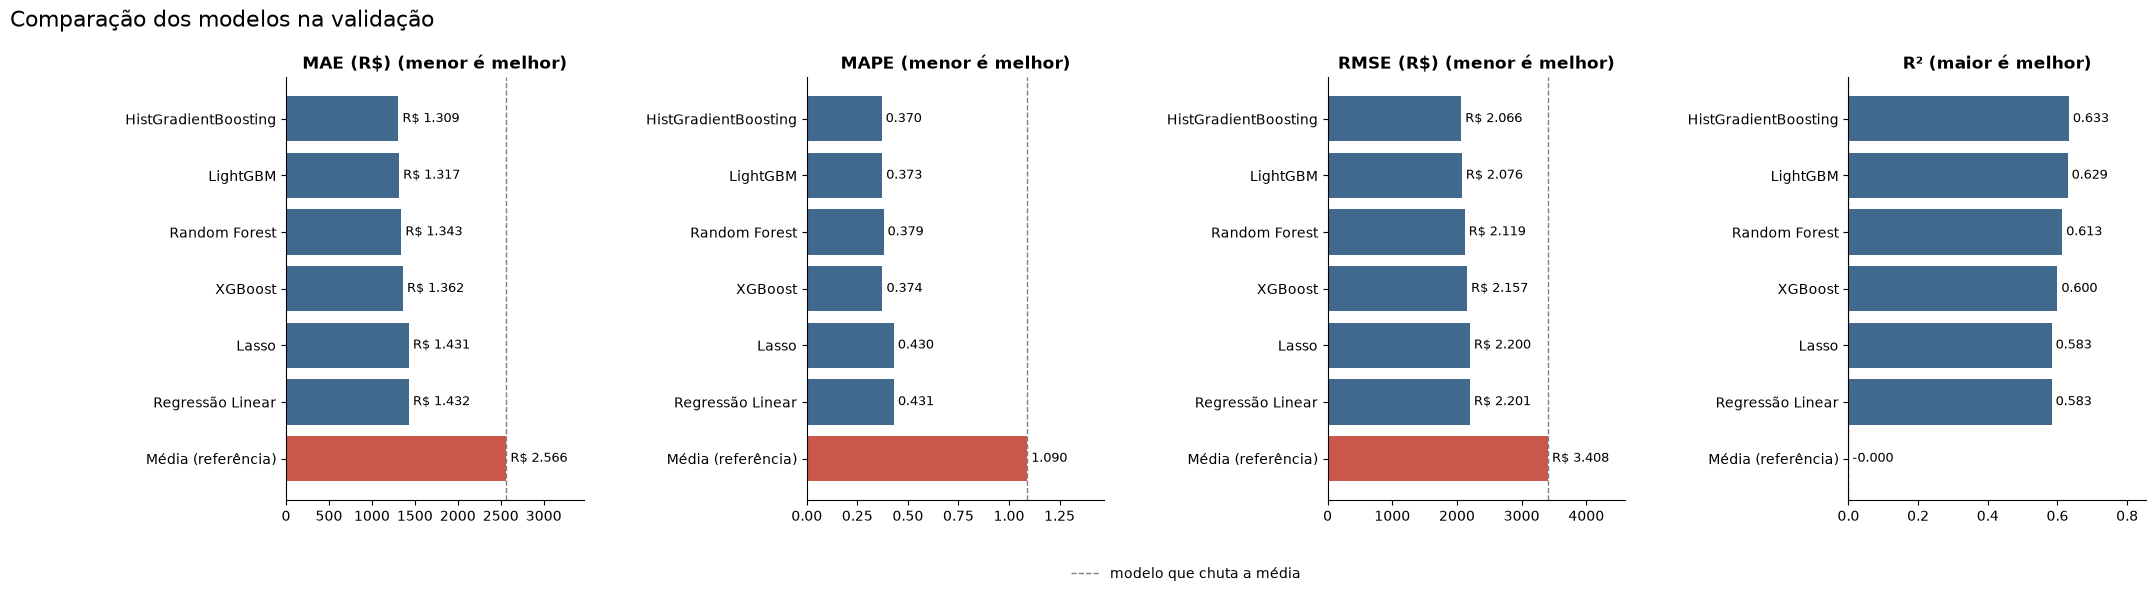

💾 Resultados salvos em: reports/comparacao_modelos.csv
Melhor na validação cruzada (decide o ajuste fino): HistGradientBoosting


,MAE,MAPE,RMSE,R²,MAE CV,score geral (posição média)
HistGradientBoosting,1.000,1.000,1.000,1.000,1.000,1.000
LightGBM,2.000,2.000,2.000,2.000,2.000,2.000
Random Forest,3.000,4.000,3.000,3.000,3.000,3.200
XGBoost,4.000,3.000,4.000,4.000,4.000,3.800
Lasso,5.000,5.000,5.000,5.000,5.000,5.000
Regressão Linear,6.000,6.000,6.000,6.000,6.000,6.000
Média (referência),7.000,7.000,7.000,7.000,7.000,7.000


In [48]:
comparacao = pd.concat([metricas_media, metricas_lr, metricas_lasso, metricas_rf, metricas_xgb, metricas_lgbm, metricas_hgb])
comparacao = comparacao.join(tabela_cv).sort_values('MAE (R$)')
comparacao.to_csv('../reports/comparacao_modelos.csv')

display(comparacao.style.format({'MAE (R$)': reais, 'MAPE': '{:.1%}', 'RMSE (R$)': reais, 'R²': '{:.3f}',
                                 'MPE': '{:+.1%}', 'MAE treino (R$)': reais})
        .highlight_min(subset=['MAE (R$)', 'MAPE', 'RMSE (R$)'], color='#C8E6C9')
        .highlight_max(subset=['R²'], color='#C8E6C9'))

plot_comparacao_modelos(comparacao, 'Comparacao dos modelos')
print('💾 Resultados salvos em: reports/comparacao_modelos.csv')

# Score geral: posição média nas 4 métricas da validação + MAE da validação cruzada (1 = melhor)
ranking = pd.DataFrame({'MAE': comparacao['MAE (R$)'].rank(), 'MAPE': comparacao['MAPE'].rank(),
                        'RMSE': comparacao['RMSE (R$)'].rank(), 'R²': comparacao['R²'].rank(ascending=False),
                        'MAE CV': pd.Series(mae_cv).rank()})
ranking['score geral (posição média)'] = ranking.mean(axis=1)
melhor_modelo = pd.Series(mae_cv).drop('Média (referência)').idxmin()
print(f'Melhor na validação cruzada (decide o ajuste fino): {melhor_modelo}')
ranking.sort_values('score geral (posição média)')

📌 **Nota**
- 🔎 **Como ler o painel:** cada gráfico é uma métrica, com uma barra por modelo. A **linha tracejada** é o modelo que chuta a média: todos os algoritmos ficam muito à frente dele.
- 🔎 O **HistGradientBoosting** fica em 1º lugar nas 4 métricas da validação e na validação cruzada (score geral **1,0**); o **LightGBM** fica em 2º em todas.
- 🔎 Mesmo o melhor modelo erra, em média, **37%** do aluguel. As características da base não dizem o **bairro**, o **estado de conservação** nem o **acabamento**, que pesam muito no preço.
- ✅ **Decisão:** seguir com o **HistGradientBoosting** para o ajuste fino: menor erro na validação e na validação cruzada, e sobreajuste moderado.

## 7 - AJUSTE FINO DE HIPERPARÂMETROS

**Parâmetros x hiperparâmetros.** Os **parâmetros** são o que o modelo aprende sozinho com os dados (as divisões e os valores de cada árvore). Os **hiperparâmetros** são as configurações que **nós** escolhemos antes do treino e que controlam **como** ele aprende: a taxa de aprendizado, o número de árvores, o tamanho de cada árvore, a regularização. É como assar um bolo: os ingredientes são os dados, as reações no forno são os parâmetros e a **temperatura e o tempo** são os hiperparâmetros. Temperatura errada, bolo cru ou queimado.

Comparamos os **três métodos** de busca mais usados, todos com as **mesmas 5 partes da validação cruzada do treino** e a mesma métrica (MAE):

| Critério | Grid Search | Random Search | Bayesiana (Optuna) |
|---|---|---|---|
| **Estratégia** | testa **todas** as combinações de uma grade | **sorteia** N combinações | usa os resultados anteriores para escolher a **próxima** |
| **Custo** | ❌ explode com o número de hiperparâmetros | ✅ controlado (N fixo) | ✅ controlado (N fixo) |
| **Valores contínuos** | ❌ só os pontos da grade | ✅ sim | ✅ sim |
| **Aprende com o histórico** | ❌ não | ❌ não | ✅ sim |
| **Exploração + explotação** | não | só exploração | ✅ as duas |
| **Escalabilidade** | ruim | boa | excelente |
| **Melhor uso** | espaço pequeno (2-3 hiperparâmetros) | exploração inicial | desempenho máximo, modelos caros |

*Exploração* = testar regiões ainda desconhecidas; *explotação* = refinar perto das melhores combinações já encontradas.

> 🛡️ **O teste fica trancado.** Se escolhêssemos os hiperparâmetros pelo resultado no teste, estaríamos ajustando o modelo **àqueles** imóveis (sobreajuste de hiperparâmetros) e o número final ficaria otimista. Por isso a escolha usa só a **validação cruzada do treino**; o teste é aberto uma única vez, no item 7.6.

> 🔁 **Qual validação cruzada?** Usamos o **K-Fold** (5 partes embaralhadas), o padrão para dados sem ordem no tempo. O *Stratified K-Fold* serve para classificação com classes desbalanceadas e o *TimeSeriesSplit* para séries temporais; os anúncios são um retrato de um único momento, sem data.

### 7.1. Grid Search

O Grid Search testa **todas** as combinações de uma grade. Para o custo caber no tempo disponível, a grade tem os **3 hiperparâmetros** que mais mudam o HistGradientBoosting, com 3 valores cada; o número de árvores fica fixo em 400.

Grade: 27 combinações x 5 partes = 135 modelos treinados


Grid Search concluído em 492s | melhor MAE (validação cruzada): R$ 1.322
Melhores hiperparâmetros: {'l2_regularization': 10, 'learning_rate': 0.02, 'max_leaf_nodes': 15}


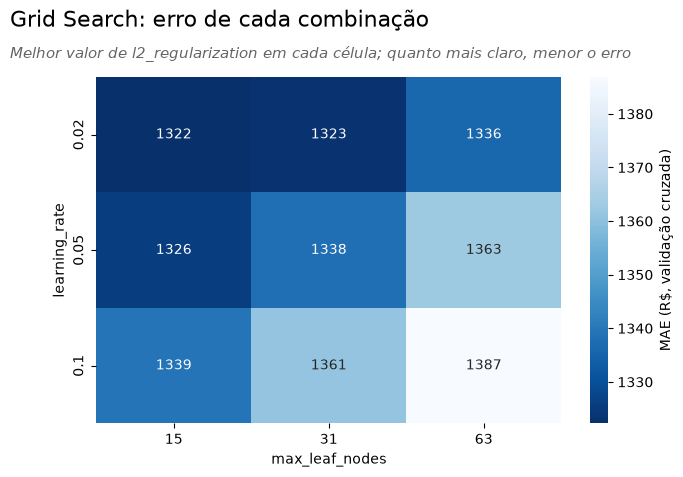

In [49]:
grades = {
    'Random Forest': {'modelo__n_estimators': [200, 400, 600], 'modelo__max_depth': [None, 10, 20], 'modelo__min_samples_leaf': [1, 4, 8]},
    'XGBoost': {'modelo__learning_rate': [0.02, 0.05, 0.1], 'modelo__max_depth': [4, 6, 8], 'modelo__min_child_weight': [1, 5, 10]},
    'LightGBM': {'modelo__learning_rate': [0.02, 0.05, 0.1], 'modelo__num_leaves': [15, 31, 63], 'modelo__min_child_samples': [10, 20, 40]},
    'HistGradientBoosting': {'modelo__learning_rate': [0.02, 0.05, 0.1], 'modelo__max_leaf_nodes': [15, 31, 63],
                             'modelo__l2_regularization': [0, 1, 10]},
}
fixos = {'XGBoost': {'modelo__n_estimators': 400}, 'LightGBM': {'modelo__n_estimators': 400}, 'HistGradientBoosting': {'modelo__max_iter': 400}}
grade = grades[melhor_modelo]
n_combinacoes = int(np.prod([len(valores) for valores in grade.values()]))
print(f'Grade: {n_combinacoes} combinações x {validacao.get_n_splits()} partes = {n_combinacoes * validacao.get_n_splits()} modelos treinados')

grid = GridSearchCV(clone(modelos[melhor_modelo]).set_params(**fixos.get(melhor_modelo, {})), grade, cv=validacao,
                    scoring='neg_mean_absolute_error', n_jobs=N_JOBS, return_train_score=True)
t0 = time.time()
grid.fit(X_treino, y_treino)
tempo_grid = time.time() - t0
print(f'Grid Search concluído em {tempo_grid:.0f}s | melhor MAE (validação cruzada): {reais(-grid.best_score_)}')
print('Melhores hiperparâmetros:', {k.replace('modelo__', ''): v for k, v in grid.best_params_.items()})

# Mapa de calor: MAE dos 2 primeiros hiperparâmetros, com o melhor valor do 3º em cada célula
resultados_grid = pd.DataFrame(grid.cv_results_)
hp_linha, hp_coluna = list(grade)[:2]
mapa = -resultados_grid.pivot_table(index=f'param_{hp_linha}', columns=f'param_{hp_coluna}', values='mean_test_score', aggfunc='max')
fig, ax = plt.subplots(figsize=(7.5, 4.5))
sns.heatmap(mapa, annot=True, fmt='.0f', cmap='Blues_r', cbar_kws={'label': 'MAE (R$, validação cruzada)'}, ax=ax)
ax.set(ylabel=hp_linha.replace('modelo__', ''), xlabel=hp_coluna.replace('modelo__', ''))
titulo('Grid Search: erro de cada combinação', f"Melhor valor de {list(grade)[2].replace('modelo__', '')} em cada célula; quanto mais claro, menor o erro")
salvar('Grid search')
plt.show()

📌 **Nota**
- 🔎 A grade tem **27 combinações x 5 partes = 135 modelos**, treinados em **492 s** (~8 min). A melhor combinação é **taxa de aprendizado 0,02, árvores de 15 folhas e l2 = 10**, com MAE de **R$ 1.322** na validação cruzada.
- 🔎 O mapa de calor mostra um padrão claro: o erro **cresce** com a taxa de aprendizado e com o tamanho das árvores, de **R$ 1.322** (0,02 e 15 folhas) a **R$ 1.387** (0,1 e 63 folhas). Nesta base, com muito ruído (falta o bairro), um modelo que aprende **devagar** e com **árvores pequenas** generaliza melhor.
- ⚠️ **A explosão do Grid:** só 3 hiperparâmetros com 3 valores já custam 135 modelos. Com os 5 hiperparâmetros da busca aleatória, a grade completa teria **432 combinações = 2.160 modelos (~131 min)**, a conta do item 7.4. Por isso o número de árvores (400) e o mínimo de imóveis por folha (20, o padrão) ficaram fixos.

### 7.2. Random Search

O Random Search **sorteia** 30 combinações entre os 5 hiperparâmetros (em vez de testar todas). Testamos 30 combinações de hiperparâmetros do algoritmo com **menor MAE na validação cruzada** (item 5), com **validação cruzada de 5 partes no treino**, escolhendo a de **menor MAE**. O pré-processamento fica dentro do `Pipeline` e é reajustado em cada parte.

busca concluída em 435s
Melhores hiperparâmetros: {'min_samples_leaf': 40, 'max_leaf_nodes': 15, 'max_iter': 400, 'learning_rate': 0.02, 'l2_regularization': 10}


,rank_test_score,MAE (R$),desvio (R$),min_samples_leaf,max_leaf_nodes,max_iter,learning_rate,l2_regularization
25,1,"1,318.100",39.400,40,15,400,0.020,10.000
13,2,"1,322.200",41.900,20,15,400,0.020,10.000
3,3,"1,327.400",42.600,10,31,200,0.050,0.000
21,4,"1,327.500",48.000,10,15,400,0.020,1.000
18,5,"1,328.400",48.200,10,15,400,0.020,0.000


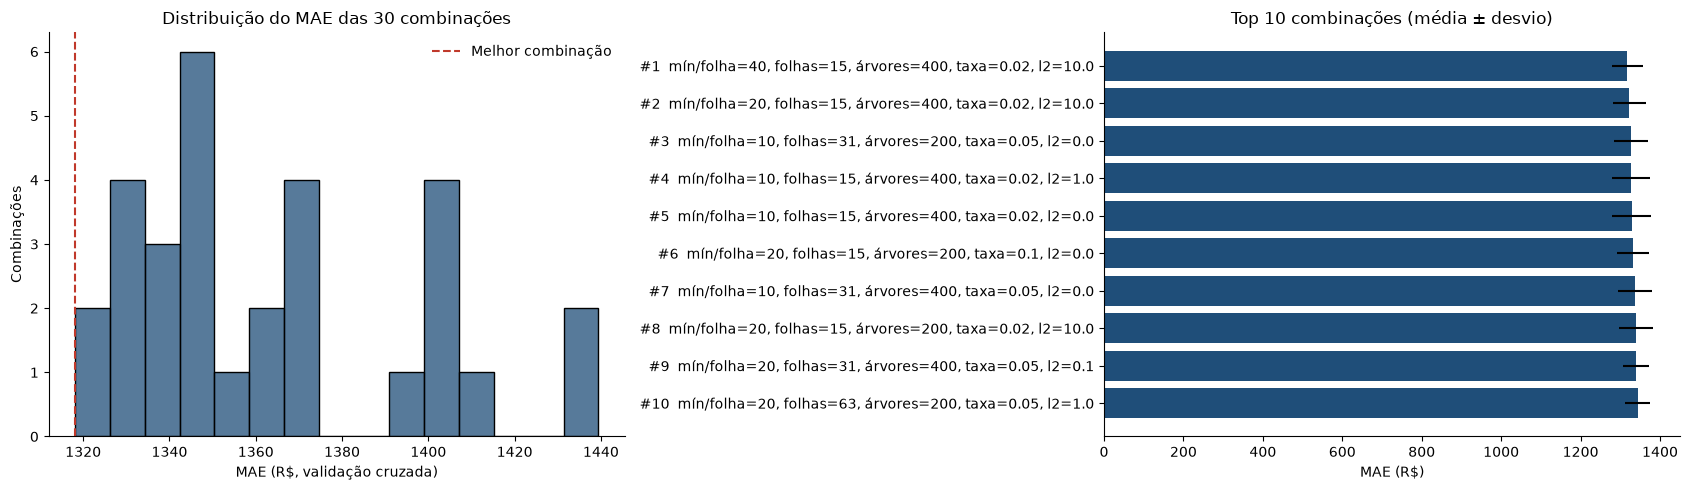

In [50]:
espacos_busca = {
    'Random Forest': {'modelo__n_estimators': [200, 400, 600], 'modelo__max_depth': [None, 10, 20, 30],
                      'modelo__min_samples_leaf': [1, 2, 4, 8], 'modelo__max_features': [1.0, 0.7, 0.5, 'sqrt']},
    'XGBoost': {'modelo__n_estimators': [200, 400, 800], 'modelo__learning_rate': [0.02, 0.05, 0.1],
                'modelo__max_depth': [3, 4, 6, 8], 'modelo__subsample': [0.7, 0.85, 1.0],
                'modelo__colsample_bytree': [0.7, 0.85, 1.0], 'modelo__min_child_weight': [1, 5, 10]},
    'LightGBM': {'modelo__n_estimators': [200, 400, 800], 'modelo__learning_rate': [0.02, 0.05, 0.1],
                 'modelo__num_leaves': [15, 31, 63], 'modelo__min_child_samples': [10, 20, 40],
                 'modelo__subsample': [0.7, 0.85, 1.0], 'modelo__subsample_freq': [1],
                 'modelo__colsample_bytree': [0.7, 0.85, 1.0]},
    'HistGradientBoosting': {'modelo__learning_rate': [0.02, 0.05, 0.1, 0.2], 'modelo__max_iter': [200, 400, 800],
                             'modelo__max_leaf_nodes': [15, 31, 63], 'modelo__min_samples_leaf': [10, 20, 40],
                             'modelo__l2_regularization': [0, 0.1, 1, 10]},
}
busca = RandomizedSearchCV(clone(modelos[melhor_modelo]), espacos_busca[melhor_modelo], n_iter=30, cv=validacao,
                           scoring='neg_mean_absolute_error', random_state=SEMENTE, n_jobs=N_JOBS,
                           return_train_score=True)
t0 = time.time()
busca.fit(X_treino, y_treino)
tempo_random = time.time() - t0
print(f'busca concluída em {tempo_random:.0f}s')

resultados_busca = pd.DataFrame(busca.cv_results_)
resultados_busca['MAE (R$)'] = -resultados_busca['mean_test_score']
resultados_busca['desvio (R$)'] = resultados_busca['std_test_score']
parametros = [coluna for coluna in resultados_busca.columns if coluna.startswith('param_')]
top5 = resultados_busca.sort_values('rank_test_score')[['rank_test_score', 'MAE (R$)', 'desvio (R$)'] + parametros].head(5)
top5.columns = [coluna.replace('param_modelo__', '') for coluna in top5.columns]
print('Melhores hiperparâmetros:', {k.replace('modelo__', ''): v for k, v in busca.best_params_.items()})
display(top5.round({'MAE (R$)': 1, 'desvio (R$)': 1}))

fig, axs = plt.subplots(1, 2, figsize=(17, 5))
sns.histplot(resultados_busca['MAE (R$)'], bins=15, color=COR_PRINCIPAL, ax=axs[0])
axs[0].axvline(resultados_busca['MAE (R$)'].min(), color=COR_DESTAQUE, ls='--', label='Melhor combinação')
axs[0].set(title='Distribuição do MAE das 30 combinações', xlabel='MAE (R$, validação cruzada)', ylabel='Combinações')
axs[0].legend(frameon=False)
top10 = resultados_busca.sort_values('rank_test_score').head(10)
abreviacoes = {'learning_rate': 'taxa', 'max_iter': 'árvores', 'max_leaf_nodes': 'folhas', 'min_samples_leaf': 'mín/folha',
               'l2_regularization': 'l2', 'n_estimators': 'árvores', 'max_depth': 'prof.', 'num_leaves': 'folhas'}
rotulos = [f"#{r['rank_test_score']}  " + ', '.join(f"{abreviacoes.get(p.replace('param_modelo__', ''), p.replace('param_modelo__', ''))}={r[p]}"
                                               for p in parametros) for _, r in top10.iterrows()]
axs[1].barh(rotulos[::-1], top10['MAE (R$)'][::-1], xerr=top10['desvio (R$)'][::-1], color=COR_PRINCIPAL)
axs[1].set(title='Top 10 combinações (média ± desvio)', xlabel='MAE (R$)')
sns.despine()
plt.tight_layout()
salvar('Random Search')
plt.show()

📌 **Nota**
- 🔎 A melhor combinação usa **taxa de aprendizado baixa** (0,02) com **400 árvores**, árvores pequenas (**15 folhas**), pelo menos **40 imóveis por folha** e regularização forte (**l2 = 10**): um modelo que aprende devagar e evita detalhes de poucos imóveis.
- 🔎 As 5 melhores combinações ficam entre **R$ 1.318 e R$ 1.328** na validação cruzada do treino, diferença menor que o desvio entre as partes (~R$ 40): várias configurações funcionam quase igual.

### 7.3. Otimização Bayesiana (Optuna)

O Grid e o Random Search **não aprendem** com o que já testaram: a 30ª combinação é escolhida sem olhar as 29 anteriores. A otimização **Bayesiana** faz o contrário: depois de cada tentativa (*trial*), um modelo probabilístico (o **TPE** do Optuna) estima onde estão as combinações promissoras e escolhe a próxima, equilibrando:

- **exploração:** testar regiões ainda desconhecidas, onde a incerteza é alta (as 10 primeiras tentativas são sorteadas);
- **explotação:** refinar em volta das melhores combinações já encontradas.

Usamos o **mesmo orçamento** do Random Search (**30 tentativas**), as mesmas 5 partes e valores **contínuos** (a taxa de aprendizado e a regularização em escala logarítmica, porque variam em ordens de grandeza).

Optuna concluído em 336s | melhor MAE (validação cruzada): R$ 1.316 (tentativa nº 28)
Melhores hiperparâmetros: {'learning_rate': 0.033, 'max_iter': 250, 'max_leaf_nodes': 25, 'min_samples_leaf': 58, 'l2_regularization': 3.4807}


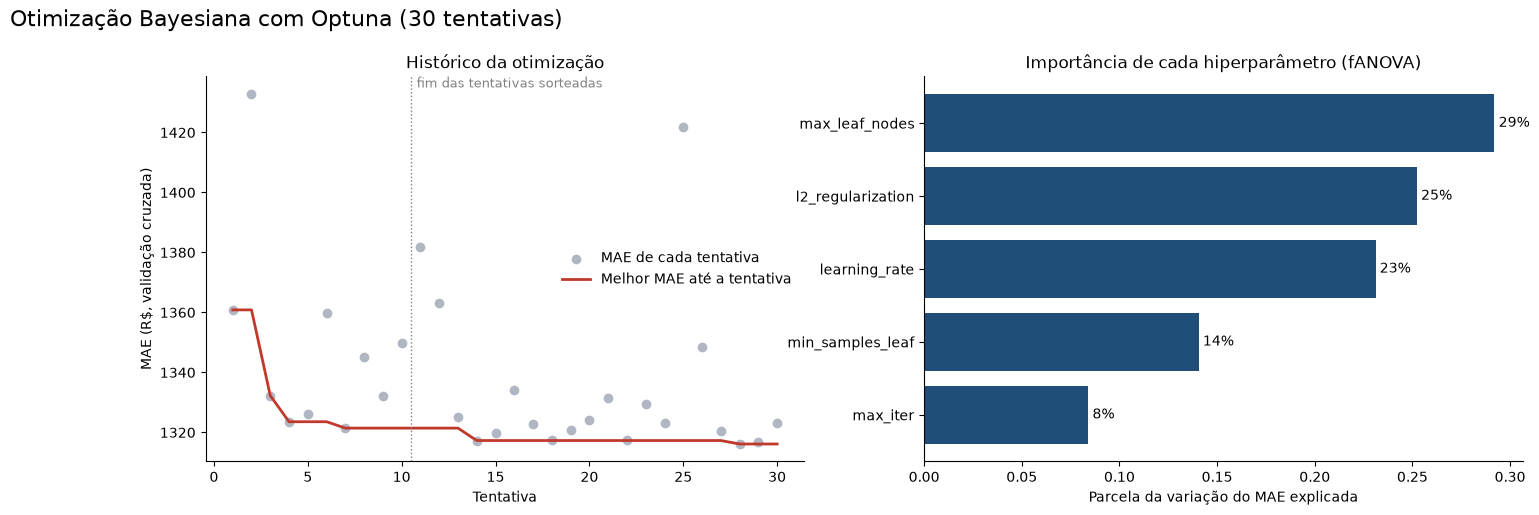

In [51]:
espacos_optuna = {
    'Random Forest': lambda t: {'modelo__n_estimators': t.suggest_int('n_estimators', 200, 600, step=50),
                                'modelo__max_depth': t.suggest_int('max_depth', 5, 40),
                                'modelo__min_samples_leaf': t.suggest_int('min_samples_leaf', 1, 10),
                                'modelo__max_features': t.suggest_float('max_features', 0.3, 1.0)},
    'XGBoost': lambda t: {'modelo__n_estimators': t.suggest_int('n_estimators', 200, 800, step=50),
                          'modelo__learning_rate': t.suggest_float('learning_rate', 0.01, 0.3, log=True),
                          'modelo__max_depth': t.suggest_int('max_depth', 3, 8),
                          'modelo__subsample': t.suggest_float('subsample', 0.6, 1.0),
                          'modelo__colsample_bytree': t.suggest_float('colsample_bytree', 0.6, 1.0),
                          'modelo__min_child_weight': t.suggest_int('min_child_weight', 1, 10)},
    'LightGBM': lambda t: {'modelo__n_estimators': t.suggest_int('n_estimators', 200, 800, step=50),
                           'modelo__learning_rate': t.suggest_float('learning_rate', 0.01, 0.3, log=True),
                           'modelo__num_leaves': t.suggest_int('num_leaves', 8, 64, log=True),
                           'modelo__min_child_samples': t.suggest_int('min_child_samples', 5, 60)},
    'HistGradientBoosting': lambda t: {'modelo__learning_rate': t.suggest_float('learning_rate', 0.01, 0.3, log=True),
                                       'modelo__max_iter': t.suggest_int('max_iter', 100, 800, step=50),
                                       'modelo__max_leaf_nodes': t.suggest_int('max_leaf_nodes', 8, 64, log=True),
                                       'modelo__min_samples_leaf': t.suggest_int('min_samples_leaf', 5, 60),
                                       'modelo__l2_regularization': t.suggest_float('l2_regularization', 1e-3, 10, log=True)},
}
estudo = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEMENTE))
objetivo = objetivo_cv(clone(modelos[melhor_modelo]), espacos_optuna[melhor_modelo], X_treino, y_treino, validacao,
                       'neg_mean_absolute_error', N_JOBS)
t0 = time.time()
estudo.optimize(objetivo, n_trials=30)
tempo_optuna = time.time() - t0
print(f'Optuna concluído em {tempo_optuna:.0f}s | melhor MAE (validação cruzada): {reais(-estudo.best_value)} '
      f'(tentativa nº {estudo.best_trial.number + 1})')
print('Melhores hiperparâmetros:', {k: round(v, 4) if isinstance(v, float) else v for k, v in estudo.best_params.items()})

fig, axs = plt.subplots(1, 2, figsize=(17, 5))
valores, melhor_ate_aqui = historico_optuna(estudo)
axs[0].scatter(range(1, len(valores) + 1), -valores, color=COR_NEUTRA, label='MAE de cada tentativa')
axs[0].plot(range(1, len(valores) + 1), -melhor_ate_aqui, color=COR_DESTAQUE, lw=2, label='Melhor MAE até a tentativa')
axs[0].axvline(10.5, color='grey', ls=':', lw=1)
axs[0].text(10.8, axs[0].get_ylim()[1], 'fim das tentativas sorteadas', va='top', fontsize=9, color='grey')
axs[0].set(title='Histórico da otimização', xlabel='Tentativa', ylabel='MAE (R$, validação cruzada)')
axs[0].legend(frameon=False)
importancia_hps = pd.Series(optuna.importance.get_param_importances(estudo)).sort_values()
axs[1].barh(importancia_hps.index, importancia_hps.values, color=COR_PRINCIPAL)
axs[1].bar_label(axs[1].containers[0], labels=[pct(v) for v in importancia_hps.values], padding=3)
axs[1].set(title='Importância de cada hiperparâmetro (fANOVA)', xlabel='Parcela da variação do MAE explicada')
sns.despine()
titulo('Otimização Bayesiana com Optuna (30 tentativas)')
salvar('Otimizacao bayesiana')
plt.show()

📌 **Nota**
- 🔎 O Optuna encontrou o **menor MAE dos três métodos: R$ 1.316**, na tentativa nº 28, com **taxa de aprendizado 0,033, 250 árvores, 25 folhas, 58 imóveis por folha e l2 = 3,48**: valores **entre** os pontos da grade, que o Grid nunca testaria.
- 🔎 **Histórico:** nas 10 tentativas sorteadas, o erro varia muito (de R$ 1.321 a R$ 1.432). Depois, o TPE concentra quase todas as tentativas entre **R$ 1.316 e R$ 1.335** (explotação), com saltos ocasionais para regiões ainda não testadas (a tentativa 25, com R$ 1.422, é exploração).
- 🔎 **Importância dos hiperparâmetros:** o tamanho da árvore (**29%**), a regularização (**25%**) e a taxa de aprendizado (**23%**) explicam três quartos da variação do erro; o número de árvores, só **8%**. Isso confirma a escolha da grade do item 7.1 (esses 3, com o número de árvores fixo).
- 🔎 Com o mesmo número de modelos (150), a busca levou **336 s**, contra **435 s** do Random Search: o Optuna preferiu combinações com menos árvores, que treinam mais rápido.

### 7.4. Comparação dos 3 métodos

Colocamos os métodos lado a lado, junto com o modelo **sem ajuste** (hiperparâmetros padrão), porque o ganho do ajuste só existe se for medido contra essa referência. Para cada método: o melhor MAE da validação cruzada (± desvio entre as partes), o MAE no próprio treino (a diferença indica **sobreajuste**), o custo (modelos treinados e tempo) e o MAE na **validação** (dados fora da busca).

**Regra de escolha:** o menor MAE da validação cruzada. Se um método novo ganhar do Random Search (usado até a versão anterior) por **menos que o desvio entre as partes**, a diferença é ruído e o Random Search continua, para não trocar o modelo do app sem ganho real.

,MAE CV (R$),desvio (R$),MAE treino (R$),sobreajuste (R$),MAE validação (R$),Combinações testadas,Modelos treinados,Tempo (s)
Método,,,,,,,,
Padrão (sem ajuste),R$ 1.337,R$ 34,R$ 982,R$ 355,R$ 1.309,1,5,–
Grid Search,R$ 1.322,R$ 42,R$ 1.170,R$ 153,R$ 1.312,27,135,492
Random Search,R$ 1.318,R$ 39,R$ 1.181,R$ 137,R$ 1.312,30,150,435
Bayesiana (Optuna),R$ 1.316,R$ 35,R$ 1.122,R$ 195,R$ 1.302,30,150,336


Padrão (sem ajuste)  padrão do scikit-learn
Grid Search          {'l2_regularization': 10, 'learning_rate': 0.02, 'max_leaf_nodes': 15}
Random Search        {'min_samples_leaf': 40, 'max_leaf_nodes': 15, 'max_iter': 400, 'learning_rate': 0.02, 'l2_regularization': 10}
Bayesiana (Optuna)   {'learning_rate': 0.033, 'max_iter': 250, 'max_leaf_nodes': 25, 'min_samples_leaf': 58, 'l2_regularization': 3.4807}

Grade completa com os 5 hiperparâmetros: 432 combinações x 5 partes = 2.160 modelos. ~131 min
Menor MAE na validação cruzada: Bayesiana (Optuna) (R$ 2 a menos que o Random Search)
✅ Método escolhido: Random Search


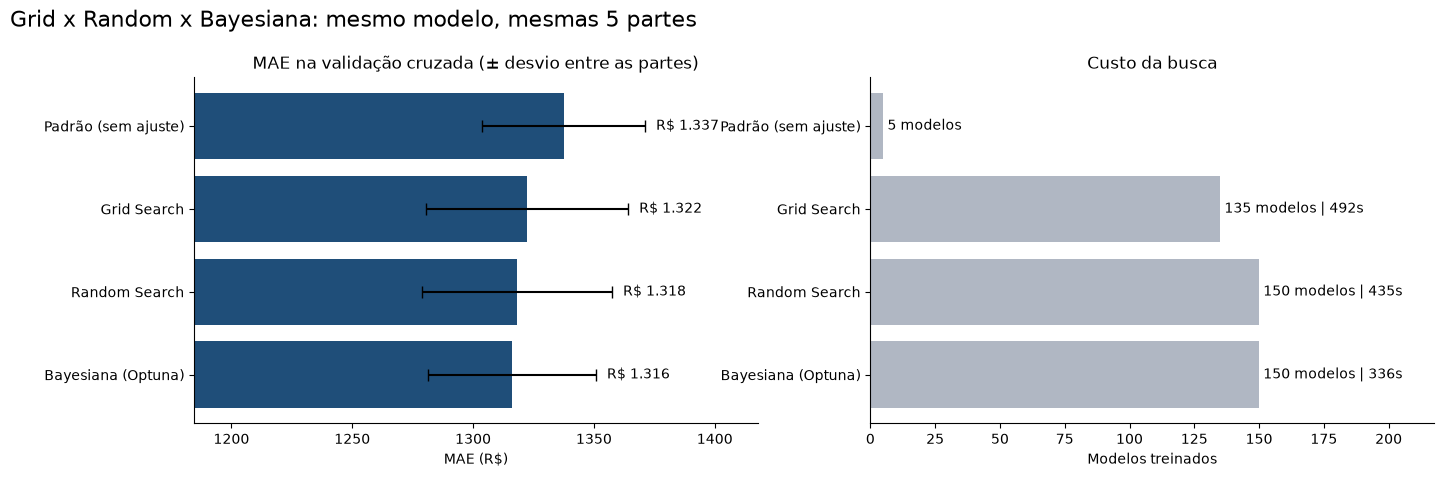

In [52]:
# Referência sem ajuste, nas mesmas 5 partes
cv_padrao = cross_validate(clone(modelos[melhor_modelo]), X_treino, y_treino, cv=validacao, scoring='neg_mean_absolute_error',
                           n_jobs=N_JOBS, return_train_score=True)
estimadores = {'Padrão (sem ajuste)': modelos[melhor_modelo], 'Grid Search': grid.best_estimator_, 'Random Search': busca.best_estimator_,
               'Bayesiana (Optuna)': clone(modelos[melhor_modelo]).set_params(**espacos_optuna[melhor_modelo](estudo.best_trial)).fit(X_treino, y_treino)}
linhas = [{'Método': 'Padrão (sem ajuste)', 'Melhor score (CV)': -cv_padrao['test_score'].mean(), 'Desvio entre dobras': cv_padrao['test_score'].std(),
           'Score no treino': -cv_padrao['train_score'].mean(), 'Combinações testadas': 1, 'Modelos treinados': validacao.get_n_splits(),
           'Tempo (s)': np.nan, 'Melhores hiperparâmetros': 'padrão do scikit-learn'},
          resumo_sklearn('Grid Search', grid, tempo_grid, sinal=-1),
          resumo_sklearn('Random Search', busca, tempo_random, sinal=-1),
          resumo_optuna('Bayesiana (Optuna)', estudo, tempo_optuna, validacao.get_n_splits(), sinal=-1)]
comparacao_busca = pd.DataFrame(linhas).set_index('Método').rename(columns={
    'Melhor score (CV)': 'MAE CV (R$)', 'Desvio entre dobras': 'desvio (R$)', 'Score no treino': 'MAE treino (R$)'})
comparacao_busca['sobreajuste (R$)'] = comparacao_busca['MAE CV (R$)'] - comparacao_busca['MAE treino (R$)']
comparacao_busca['MAE validação (R$)'] = [mean_absolute_error(y_validacao, m.predict(X_validacao)) for m in estimadores.values()]
colunas_tabela = ['MAE CV (R$)', 'desvio (R$)', 'MAE treino (R$)', 'sobreajuste (R$)', 'MAE validação (R$)', 'Combinações testadas',
                  'Modelos treinados', 'Tempo (s)']
display(comparacao_busca[colunas_tabela].style.format({c: reais for c in colunas_tabela[:5]} | {'Tempo (s)': '{:.0f}'}, na_rep='–')
        .highlight_min(subset=['MAE CV (R$)'], color='#C8E6C9'))
for metodo, parametros in comparacao_busca['Melhores hiperparâmetros'].items():
    print(f'{metodo:20s}', {k: round(v, 4) if isinstance(v, float) else v for k, v in parametros.items()} if isinstance(parametros, dict) else parametros)

# Quanto custaria a grade completa (os 5 hiperparâmetros da busca aleatória, todas as combinações)?
grade_completa = int(np.prod([len(valores) for valores in espacos_busca[melhor_modelo].values()]))
segundos_por_modelo = tempo_grid / (n_combinacoes * validacao.get_n_splits())
print(f'\nGrade completa com os 5 hiperparâmetros: {grade_completa} combinações x {validacao.get_n_splits()} partes = '
      f'{grade_completa * validacao.get_n_splits():,} modelos, ~{grade_completa * validacao.get_n_splits() * segundos_por_modelo / 60:.0f} min'.replace(',', '.'))

# Escolha: menor MAE da validação cruzada, com a regra do desvio entre as partes
ajustados = comparacao_busca.drop('Padrão (sem ajuste)')
vencedor = ajustados['MAE CV (R$)'].idxmin()
ganho_sobre_random = ajustados.loc['Random Search', 'MAE CV (R$)'] - ajustados.loc[vencedor, 'MAE CV (R$)']
metodo_escolhido = vencedor if (vencedor == 'Random Search' or ganho_sobre_random >= ajustados.loc[vencedor, 'desvio (R$)']) else 'Random Search'
melhor_estimador = estimadores[metodo_escolhido]
melhores_params = {k if k.startswith('modelo__') else f'modelo__{k}': v for k, v in comparacao_busca.loc[metodo_escolhido, 'Melhores hiperparâmetros'].items()}
print(f'Menor MAE na validação cruzada: {vencedor} ({reais(ganho_sobre_random)} a menos que o Random Search)')
print(f'✅ Método escolhido: {metodo_escolhido}')

fig, axs = plt.subplots(1, 2, figsize=(16, 4.5))
ordem = comparacao_busca.index
axs[0].barh(ordem, comparacao_busca['MAE CV (R$)'], xerr=comparacao_busca['desvio (R$)'], color=COR_PRINCIPAL, capsize=4)
axs[0].bar_label(axs[0].containers[1], labels=[reais(v) for v in comparacao_busca['MAE CV (R$)']], padding=8)
axs[0].set(xlim=(comparacao_busca['MAE CV (R$)'].min() * 0.9, comparacao_busca['MAE CV (R$)'].max() * 1.06),
           title='MAE na validação cruzada (± desvio entre as partes)', xlabel='MAE (R$)')
axs[1].barh(ordem, comparacao_busca['Modelos treinados'], color=COR_NEUTRA)
axs[1].bar_label(axs[1].containers[0], labels=[f'{n} modelos' + (f' | {t:.0f}s' if t == t else '') for n, t in
                                               zip(comparacao_busca['Modelos treinados'], comparacao_busca['Tempo (s)'])], padding=3)
axs[1].set(title='Custo da busca', xlabel='Modelos treinados', xlim=(0, comparacao_busca['Modelos treinados'].max() * 1.45))
for ax in axs:
    ax.invert_yaxis()
sns.despine()
titulo('Grid x Random x Bayesiana: mesmo modelo, mesmas 5 partes')
salvar('Comparacao dos metodos de busca')
plt.show()

📌 **Nota**

| Método | MAE CV | Sobreajuste (treino x CV) | MAE validação | Custo |
|---|---|---|---|---|
| Padrão (sem ajuste) | R$ 1.337 ± 34 | R$ 355 | R$ 1.309 | – |
| Grid Search | R$ 1.322 ± 42 | R$ 153 | R$ 1.312 | 135 modelos, 492 s (3 hiperparâmetros) |
| Random Search | R$ 1.318 ± 39 | **R$ 137** | R$ 1.312 | 150 modelos, 435 s (5 hiperparâmetros) |
| Bayesiana (Optuna) | **R$ 1.316 ± 35** | R$ 195 | **R$ 1.302** | 150 modelos, **336 s** (5 hiperparâmetros) |

- 🔎 Os três métodos ficam entre **R$ 1.316 e R$ 1.322** na validação cruzada, todos melhores que o modelo padrão (**R$ 1.337**). A diferença entre eles (**R$ 6**) é muito menor que o desvio entre as partes (**R$ 35 a 42**): é um **empate técnico**.
- 🔎 Onde o ajuste ajudou de verdade foi no **sobreajuste**: a distância entre o erro no treino e na validação cruzada caiu de **R$ 355** (padrão) para **R$ 137** a **R$ 195**.
- 🔎 **Custo:** o Grid gastou 135 modelos para explorar só 3 hiperparâmetros; o Random e a Bayesiana cobriram os 5 com 150. A grade completa custaria **2.160 modelos (~131 min)**, 15 vezes mais, para chegar ao mesmo lugar. É o que a literatura mostra (Bergstra e Bengio, 2012): com o mesmo orçamento, a busca aleatória iguala ou supera a grade.
- ✅ **Decisão:** a Bayesiana tem o menor MAE, mas só **R$ 2** abaixo do Random Search, bem menos que o desvio (R$ 35). Pela regra, o **Random Search continua**: o modelo, a ficha e o app não mudam.
- 💡 **Lição:** o melhor ajuste melhora só **R$ 21 (1,6%)** sobre o modelo padrão. Nesta base, o limite é a **informação** (falta o bairro), não os hiperparâmetros: ajustar mais não substitui dados melhores.

💡 **Qual método usar?** O guia prático da aula, aplicado a este projeto:

1. **Poucos hiperparâmetros (2-3), valores discretos** → **Grid Search**. Foi o caso do item 7.1 (3 hiperparâmetros, 27 combinações).
2. **Exploração inicial, sem ideia dos bons valores** → **Random Search**. Com 5 hiperparâmetros, ele cobriu o espaço com 150 modelos, contra 2.160 da grade completa.
3. **Desempenho máximo e tempo disponível** → **Bayesiana (Optuna)**. Ela compensa quando cada modelo é caro ou o espaço é grande. Aqui, um modelo treina em segundos e o ganho foi de só R$ 2.
4. **Caminho ideal:** Random **grosso** (faixas largas) → Bayesiana **fina** (faixas estreitas em volta do melhor ponto) → teste final, uma vez. Neste projeto, os três métodos já chegaram à mesma região (taxa de aprendizado baixa, árvores pequenas, regularização), então um refinamento extra não mudaria a conclusão: o limite é a falta do bairro, não a busca.

### 7.5. Modelo ajustado

AMOSTRA: GABARITO x PREVISÃO DA MÁQUINA (aluguel em R$)


,Gabarito,Previsão da máquina,Erro (R$)
0,915.000,"1,096.000",181.000
1,"1,490.000","1,701.000",211.000
2,"4,600.000","6,903.000","2,303.000"
3,"15,000.000","10,612.000","-4,388.000"
4,"7,600.000","3,356.000","-4,244.000"
5,"6,500.000","3,509.000","-2,991.000"


MÉTRICAS DE VALIDAÇÃO: HistGradientBoosting ajustado
MAE (R$)  1,312.468
MAPE          0.376
RMSE (R$) 2,064.816
R²            0.633
MPE           0.174

MAE no treino: R$ 1.195 | na validação: R$ 1.312 | diferença: +117 R$


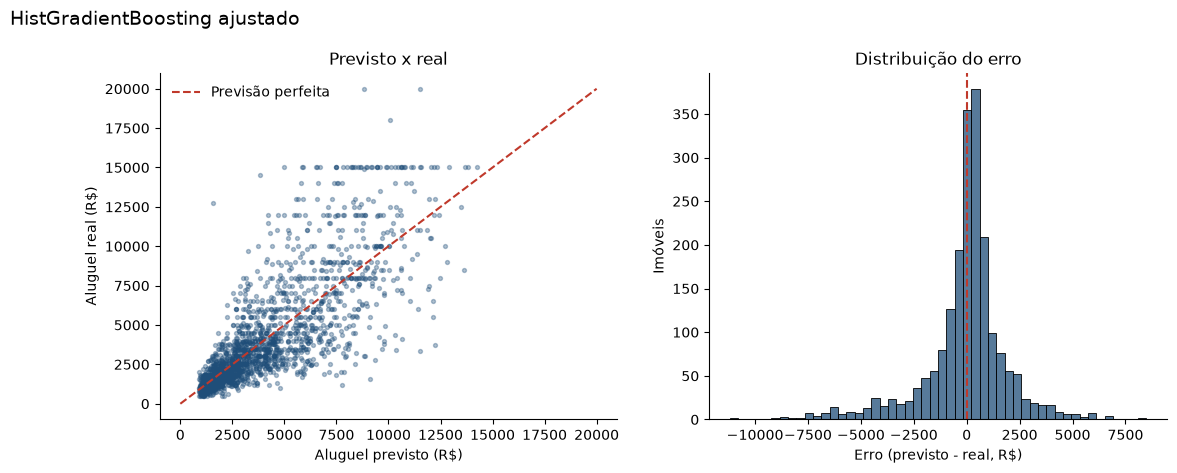

,MAE (R$),MAPE,RMSE (R$),R²,MPE,MAE treino (R$)
HistGradientBoosting,"1,308.737",0.370,"2,065.901",0.633,0.169,"1,016.103"
HistGradientBoosting ajustado,"1,312.468",0.376,"2,064.816",0.633,0.174,"1,195.463"


In [53]:
# Avaliar o modelo do método escolhido (item 7.4) na VALIDAÇÃO e comparar com a versão padrão
modelo_ajustado = melhor_estimador
metricas_ajustado, previsto_ajustado = relatorio_validacao(f'{melhor_modelo} ajustado', modelo_ajustado,
                                                           X_treino, y_treino, X_validacao, y_validacao)
pd.concat([comparacao.loc[[melhor_modelo], metricas_ajustado.columns], metricas_ajustado]).round(3)

📌 **Nota**
- 🔎 Na validação, o ajuste **não reduziu o erro**: MAE de **R$ 1.312** contra **R$ 1.309** do modelo padrão, e o mesmo R² (**0,633**). A diferença de R$ 3 é ruído.
- ✅ O ganho foi no **sobreajuste**: a diferença entre treino e validação caiu de **R$ 293** para **R$ 117**. Um modelo que decora menos o treino tende a ser mais estável com imóveis novos.
- ✅ **Decisão:** usar o modelo **ajustado**, com o mesmo erro e menos sobreajuste.

### 7.6. Modelo final

O modelo final é uma **cópia "zerada"** (`clone`) do melhor Pipeline, com os mesmos hiperparâmetros, treinada em **treino + validação** (80% dos imóveis). Ele é avaliado no **teste** pela primeira e única vez.

In [54]:
modelo_final = clone(melhor_estimador)
modelo_final.fit(X_treino_val, y_treino_val)

previsto_teste = modelo_final.predict(X_teste)
pd.concat([ml_error('Validação (modelo ajustado)', y_validacao, previsto_ajustado),
           ml_error('Teste (modelo final)', y_teste, previsto_teste)]).round(3)

,MAE (R$),MAPE,RMSE (R$),R²,MPE
Validação (modelo ajustado),"1,312.468",0.376,"2,064.816",0.633,0.174
Teste (modelo final),"1,249.002",0.367,"1,970.964",0.653,0.182


📌 **Nota**
- 🔎 No teste, o modelo final tem MAE de **R$ 1.249**, MAPE de **36,7%** e R² de **0,65**, um pouco **melhor** que na validação (R$ 1.312 e 0,63). Ele foi treinado com mais dados (treino + validação), e o teste não foi usado em nenhuma escolha. **Não houve sobreajuste** à validação.
- 🔎 O **MPE de +18%** indica que o modelo tende a **superestimar** os aluguéis baratos, em termos relativos: errar R$ 300 para cima num aluguel de R$ 1.000 pesa 30%.

## 8 - Otimização de limiar e calibração

### 8.1. Limiar de decisão

🚫 **Não se aplica.** O limiar serve para transformar uma **probabilidade** em uma **classe** (ex.: "fraude" ou "não fraude"). Aqui o modelo já devolve o próprio **aluguel em reais**. No lugar do limiar, medimos **o quanto a previsão pode errar**.

### 8.2. Faixa de erro esperada

O erro de um aluguel de R$ 15.000 é naturalmente maior, em reais, que o de um aluguel de R$ 1.200. Por isso a faixa é **relativa**: medimos, na **validação**, entre quais **múltiplos da previsão** o aluguel real costuma ficar. A faixa entre o **10º e o 90º percentil** contém **80%** dos imóveis.

In [55]:
faixa = faixa_relativa(y_validacao, previsto_ajustado, cobertura=0.80)
print(f'Em 80% dos imóveis da validação, o aluguel real ficou entre {faixa[0]:.0%} e {faixa[1]:.0%} do previsto')
print(f'Exemplo: previsão de R$ 3.000 -> faixa de {reais(3000 * faixa[0])} a {reais(3000 * faixa[1])}')

# Para comparar: uma faixa FIXA em reais (p10 e p90 dos erros em R$)
erros_reais = y_validacao - previsto_ajustado
faixa_fixa = tuple(np.quantile(erros_reais, [0.10, 0.90]))
print(f'Faixa fixa em reais: {reais(faixa_fixa[0])} a +{reais(faixa_fixa[1])} em torno da previsão')

Em 80% dos imóveis da validação, o aluguel real ficou entre 56% e 157% do previsto
Exemplo: previsão de R$ 3.000 -> faixa de R$ 1.688 a R$ 4.720
Faixa fixa em reais: R$ -1.933 a +R$ 2.294 em torno da previsão


### 8.3. Faixa de erro aplicada no teste

In [56]:
dentro_fixa = ((y_teste >= previsto_teste + faixa_fixa[0]) & (y_teste <= previsto_teste + faixa_fixa[1]))
dentro_relativa = ((y_teste >= previsto_teste * faixa[0]) & (y_teste <= previsto_teste * faixa[1]))
print(f'Imóveis do teste dentro da faixa relativa: {dentro_relativa.mean():.1%} (esperado: 80%)')
print(f'Imóveis do teste dentro da faixa fixa em reais: {dentro_fixa.mean():.1%}' + chr(10))

faixas_previsao = pd.qcut(previsto_teste, 4, labels=['1º quartil (mais baratos)', '2º quartil', '3º quartil', '4º quartil (mais caros)'])
pd.DataFrame({'faixa relativa': dentro_relativa.groupby(faixas_previsao, observed=True).mean(),
              'faixa fixa em R$': dentro_fixa.groupby(faixas_previsao, observed=True).mean()}).style.format('{:.1%}')

Imóveis do teste dentro da faixa relativa: 81.3% (esperado: 80%)
Imóveis do teste dentro da faixa fixa em reais: 81.6%



,faixa relativa,faixa fixa em R$
1º quartil (mais baratos),86.7%,99.4%
2º quartil,81.4%,96.7%
3º quartil,79.1%,80.4%
4º quartil (mais caros),77.9%,49.8%


📌 **Nota**
- 🔎 Em 80% dos imóveis da validação, o aluguel real ficou entre **56%** e **157%** do previsto. Exemplo: previsão de R$ 3.000 → faixa de **R$ 1.688 a R$ 4.720**. É uma faixa **larga**, coerente com o MAPE de 37%.
- 🔎 No teste, **81,3%** dos imóveis ficaram dentro dela, perto dos 80% prometidos: a faixa é **confiável**.
- 🔎 A faixa **fixa** em reais (de **−R$ 1.933** a **+R$ 2.294**) também cobre ~80% no total, mas **engana**: cobre **99,4%** dos imóveis mais baratos (larga demais para eles) e só **49,8%** dos mais caros. A faixa relativa fica entre **77,9%** e **86,7%** em todos os quartis.
- ✅ **Decisão:** usar a **faixa relativa** no app e na ficha do modelo.

### 8.4. Calibração

Um modelo **calibrado** acerta na média em todas as faixas: quando prevê R$ 5.000, o aluguel real desses imóveis deve ficar perto de R$ 5.000. Separamos os imóveis do teste em 10 grupos pela previsão e comparamos a média prevista com a real.

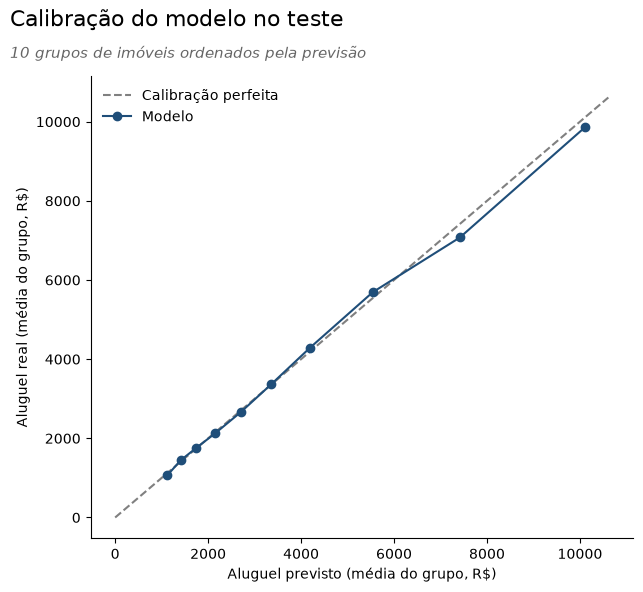

,previsto,real,diferenca
grupo,,,
0,R$ 1.125,R$ 1.070,-4.9%
1,R$ 1.410,R$ 1.446,+2.5%
2,R$ 1.737,R$ 1.751,+0.8%
3,R$ 2.156,R$ 2.131,-1.2%
4,R$ 2.709,R$ 2.669,-1.5%
5,R$ 3.358,R$ 3.365,+0.2%
6,R$ 4.198,R$ 4.294,+2.3%
7,R$ 5.543,R$ 5.693,+2.7%
8,R$ 7.417,R$ 7.075,-4.6%


In [57]:
calibracao = (pd.DataFrame({'previsto': previsto_teste, 'real': y_teste.values})
              .assign(grupo=lambda t: pd.qcut(t['previsto'], 10, labels=False))
              .groupby('grupo').mean())

plt.figure(figsize=(7, 6))
limites = [0, calibracao.max().max() * 1.05]
plt.plot(limites, limites, color='gray', ls='--', label='Calibração perfeita')
plt.plot(calibracao['previsto'], calibracao['real'], marker='o', color=COR_PRINCIPAL, label='Modelo')
plt.xlabel('Aluguel previsto (média do grupo, R$)')
plt.ylabel('Aluguel real (média do grupo, R$)')
plt.legend(frameon=False)
sns.despine()
titulo('Calibração do modelo no teste', '10 grupos de imóveis ordenados pela previsão')
salvar('Calibracao do modelo')
plt.show()
calibracao.assign(diferenca=lambda t: t['real'] / t['previsto'] - 1).style.format(
    {'previsto': reais, 'real': reais, 'diferenca': '{:+.1%}'})

📌 **Nota**
- 🔎 Os 10 grupos ficam colados à linha tracejada, de **R$ 1.125** a **R$ 10.106** de aluguel previsto. A maior diferença entre a média prevista e a real é de **−4,9%**: o modelo **não tem viés** sistemático para nenhuma faixa de preço.
- 💡 O MPE de +18% (item 7.6) e a boa calibração não se contradizem: o modelo acerta a **média** de cada grupo, mas, dentro do grupo, os erros para cima pesam mais **em porcentagem** nos aluguéis baratos.

## 9 - Teste anti-vazamento

Na seção 🛡️ da Fase 02, deixamos de fora o **seguro-incêndio** e o **total**. Para mostrar o tamanho do problema que isso evita, treinamos o **mesmo modelo ajustado** acrescentando essas colunas e comparamos na validação.

| Variável reintroduzida | Por que é vazamento |
|---|---|
| `seguro_incendio` | É calculado a partir do aluguel (cerca de **1,3%** dele): é a resposta disfarçada |
| `total` | É a **soma** do aluguel com condomínio, IPTU e seguro: contém a resposta |

,MAE (R$),MAPE,RMSE (R$),R²,MPE
Modelo legítimo,"1,312.468",0.376,"2,064.816",0.633,0.174
+ seguro_incendio,107.953,0.038,316.523,0.991,0.010
+ total,101.671,0.032,303.597,0.992,0.012


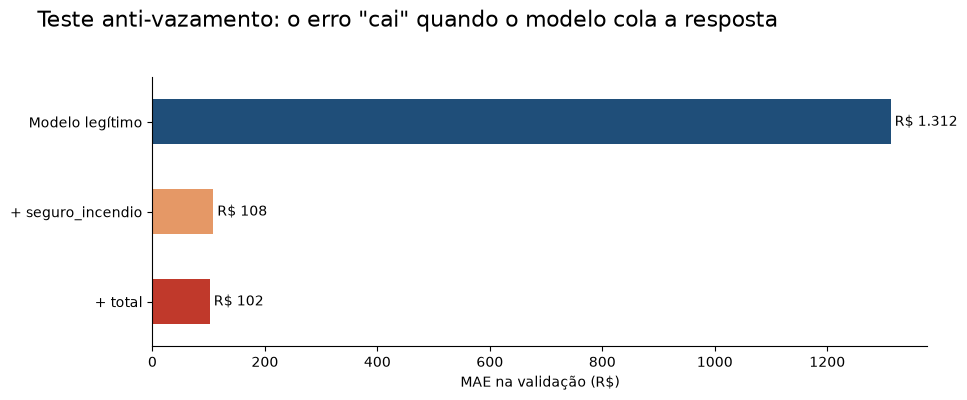

In [58]:
# Reintroduzindo as variáveis proibidas para evidenciar por que elas foram excluídas
vazamento = {'Modelo legítimo': metricas_ajustado.drop(columns='MAE treino (R$)')}
for extra in PROIBIDAS:
    X_treino_vaz = X_treino.join(df[[extra]])
    X_validacao_vaz = X_validacao.join(df[[extra]])
    modelo_vaz = clone(melhor_estimador).fit(X_treino_vaz, y_treino)
    vazamento[f'+ {extra}'] = ml_error(f'+ {extra}', y_validacao, modelo_vaz.predict(X_validacao_vaz))
tabela_vazamento = pd.concat(vazamento.values())
tabela_vazamento.index = list(vazamento)
display(tabela_vazamento.round(3))

ax = tabela_vazamento['MAE (R$)'].plot.barh(figsize=(10, 3.5), color=[COR_PRINCIPAL, '#E59866', COR_DESTAQUE])
ax.bar_label(ax.containers[0], labels=[reais(v) for v in tabela_vazamento['MAE (R$)']], padding=3)
ax.invert_yaxis()
ax.set_xlabel('MAE na validação (R$)')
sns.despine()
titulo('Teste anti-vazamento: o erro "cai" quando o modelo cola a resposta')
salvar('Teste anti-vazamento')
plt.show()

### 🛡️ Resumo: houve vazamento? Foi resolvido?

- 🔎 Com o **seguro-incêndio**, o erro despenca de **R$ 1.312** para **R$ 108** e o R² vai a **0,991**. Com o **total**, para **R$ 102** e **0,992**. Parece um modelo quase perfeito.
- 🔎 Na prática, ele só aprende a "desfazer a conta": aluguel ≈ seguro ÷ 1,3%. Na hora de anunciar um imóvel novo, nem o seguro nem o total existem, porque são calculados **a partir** do aluguel.
- ✅ **Resolvido:** o modelo usa só características conhecidas **antes** de definir o preço. O erro de ~R$ 1.250 (37%) é o **real**.

# FASE 04: AVALIAÇÃO

## 1 - Avaliando a Máquina Preditiva

Cada métrica de regressão responde uma pergunta diferente; usamos as quatro, cada uma para um público:

| Métrica | O que mede | Sensível a erros grandes? | Para que usamos aqui |
|---|---|---|---|
| **MAE** | erro médio, em reais | não | métrica principal: "a sugestão erra, em média, R$ X" |
| **RMSE** | raiz do erro quadrático médio, em reais | **sim**: um erro de R$ 5.000 pesa 25 vezes um de R$ 1.000 | mostra se há erros muito grandes (RMSE bem acima do MAE) |
| **R²** | parcela das diferenças de aluguel que o modelo explica (0 a 1) | não | comunicar a qualidade para quem não é técnico |
| **MAPE** | erro médio em % do aluguel real | não | comparar imóveis baratos e caros na mesma régua |

In [59]:
referencia_teste = np.full(len(y_teste), y_treino_val.mean())
avaliacao = pd.concat([ml_error('Média (referência)', y_teste, referencia_teste),
                       ml_error('Modelo final', y_teste, previsto_teste)])
display(avaliacao.round(3))

# Comparação justa com a v1, que treinou e testou só com São Paulo
sp = (X_teste['cidade'] == 'São Paulo').to_numpy()
ml_error('Modelo final, só imóveis de São Paulo do teste', y_teste[sp], previsto_teste[sp]).round(3)

,MAE (R$),MAPE,RMSE (R$),R²,MPE
Média (referência),"2,544.138",1.121,"3,347.871",-0.000,0.851
Modelo final,"1,249.002",0.367,"1,970.964",0.653,0.182


,MAE (R$),MAPE,RMSE (R$),R²,MPE
"Modelo final, só imóveis de São Paulo do teste","1,478.357",0.364,"2,197.184",0.606,0.175


📌 **Nota**
- 🔎 No teste (**2.065** imóveis que o modelo nunca viu), o erro médio foi de **R$ 1.249**, contra **R$ 2.544** de quem prevê sempre a média: **51% menos erro**. O RMSE é de **R$ 1.971** e o **R² de 0,65**.
- 🔎 O modelo explica **65%** das diferenças de aluguel usando 12 características do anúncio. Os outros 35% dependem do que a base não tem: **bairro**, conservação, acabamento, vista, idade do prédio.
- 🔎 **Comparação com a v1** (que usava só São Paulo): nos imóveis de **São Paulo** do teste, o modelo da v2 tem MAE de **R$ 1.478**, MAPE de **36,4%** e R² de **0,61**, contra **R$ 1.553**, **38,2%** e **0,54** da v1. Os conjuntos de teste não são os mesmos, mas a melhora vem sem duplicatas nem erros de digitação no teste.

## 2 - Previsto x observado

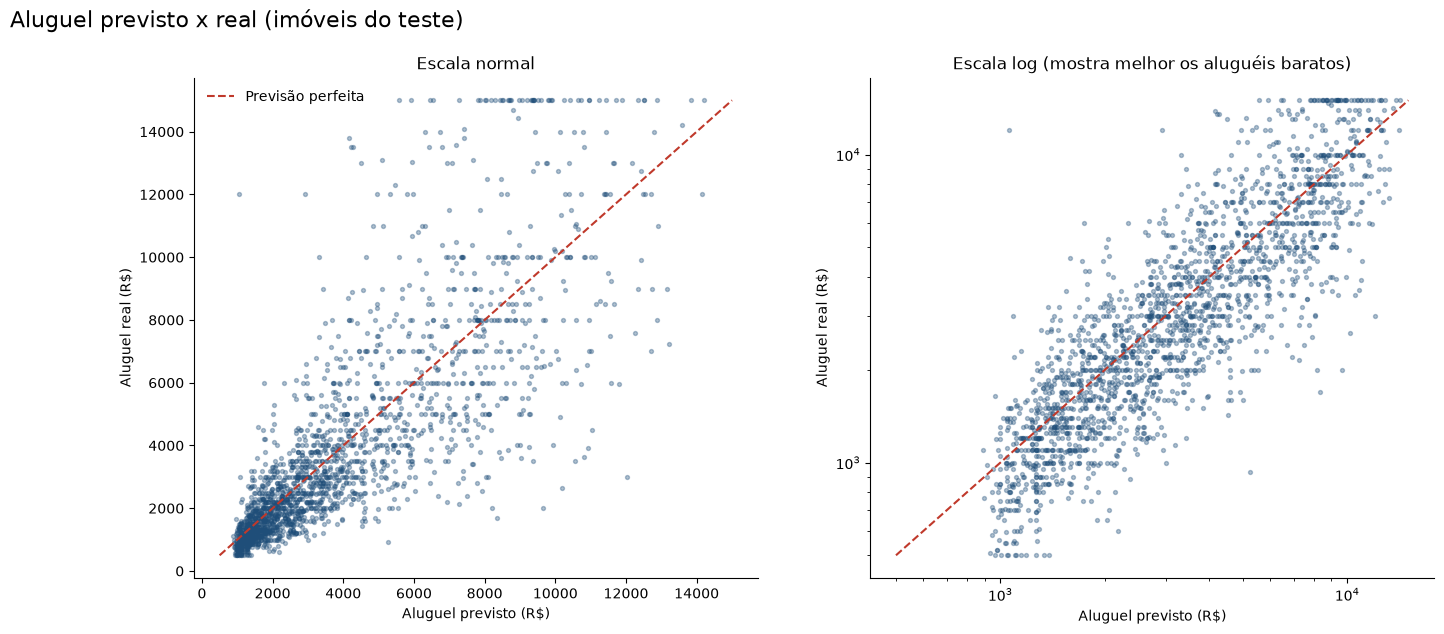

In [60]:
fig, axs = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, escala in zip(axs, ['linear', 'log']):
    ax.scatter(previsto_teste, y_teste, s=8, alpha=0.35, color=COR_PRINCIPAL)
    limites = [max(300, min(previsto_teste.min(), y_teste.min())), max(previsto_teste.max(), y_teste.max())]
    ax.plot(limites, limites, color=COR_DESTAQUE, ls='--', label='Previsão perfeita')
    ax.set(xscale=escala, yscale=escala, xlabel='Aluguel previsto (R$)', ylabel='Aluguel real (R$)',
           title='Escala normal' if escala == 'linear' else 'Escala log (mostra melhor os aluguéis baratos)')
axs[0].legend(frameon=False)
sns.despine()
titulo('Aluguel previsto x real (imóveis do teste)')
salvar('Previsto x observado')
plt.show()

#### Anúncios que mais fugiram do preço esperado

Para listar **todos** os anúncios (e não só os do teste) sem que o modelo "conheça a resposta", usamos previsões **fora da amostra**: cada imóvel é previsto por um modelo treinado sem ele (validação cruzada de 5 partes).

In [61]:
df['aluguel_esperado'] = cross_val_predict(modelo_final, X, y, cv=validacao)
df['diferenca_pct'] = df[ALVO] / df['aluguel_esperado'] - 1
colunas = ['cidade', 'area', 'quartos', 'banheiros', 'vagas', 'mobiliado', 'condominio', ALVO, 'aluguel_esperado', 'diferenca_pct']
formato = {ALVO: reais, 'aluguel_esperado': reais, 'condominio': reais, 'diferenca_pct': '{:+.0%}'}

print('Anúncios MUITO ACIMA do preço esperado:')
display(df.nlargest(6, 'diferenca_pct')[colunas].style.format(formato))
print('Anúncios MUITO ABAIXO do preço esperado:')
display(df.nsmallest(6, 'diferenca_pct')[colunas].style.format(formato))
fora_da_faixa = (df[ALVO] < df['aluguel_esperado'] * faixa[0]) | (df[ALVO] > df['aluguel_esperado'] * faixa[1])
print(f'Anúncios fora da faixa de 80%: {fora_da_faixa.mean():.1%} '
      f'(acima: {(df[ALVO] > df["aluguel_esperado"] * faixa[1]).mean():.1%} | abaixo: {(df[ALVO] < df["aluguel_esperado"] * faixa[0]).mean():.1%})')

Anúncios MUITO ACIMA do preço esperado:


,cidade,area,quartos,banheiros,vagas,mobiliado,condominio,aluguel,aluguel_esperado,diferenca_pct
909,Campinas,75,3,1,1,0,R$ 296,R$ 12.000,R$ 991,+1111%
2582,São Paulo,80,2,1,1,0,R$ 875,R$ 24.000,R$ 2.061,+1064%
6272,Porto Alegre,98,3,1,0,0,R$ 240,R$ 12.750,R$ 1.387,+819%
678,Belo Horizonte,100,2,2,0,0,R$ 0,R$ 11.000,R$ 1.834,+500%
7541,São Paulo,350,3,3,3,0,R$ 0,R$ 30.000,R$ 6.490,+362%
9451,Belo Horizonte,100,3,2,0,0,R$ 0,R$ 12.000,R$ 2.992,+301%


Anúncios MUITO ABAIXO do preço esperado:


,cidade,area,quartos,banheiros,vagas,mobiliado,condominio,aluguel,aluguel_esperado,diferenca_pct
4874,São Paulo,290,4,4,4,0,R$ 4.900,R$ 1.000,R$ 8.667,-88%
3916,Rio de Janeiro,223,3,3,0,0,R$ 2.409,R$ 765,R$ 5.917,-87%
4041,Porto Alegre,900,5,5,2,0,R$ 2.700,R$ 1.000,R$ 7.592,-87%
4012,São Paulo,380,4,4,4,0,R$ 3.300,R$ 1.500,R$ 9.213,-84%
981,São Paulo,293,4,3,3,0,R$ 3.300,R$ 1.050,R$ 6.367,-84%
520,São Paulo,147,2,3,4,0,R$ 2.600,R$ 1.200,R$ 6.994,-83%


Anúncios fora da faixa de 80%: 18.8% (acima: 8.8% | abaixo: 10.0%)


📌 **Nota**
- 🔎 **18,8%** dos anúncios ficam fora da faixa de 80% (**8,8%** acima e **10,0%** abaixo), perto dos 20% esperados.
- ⚠️ Os casos mais extremos parecem **erros no próprio aluguel**: um apartamento de 75 m² em Campinas com condomínio de R$ 296 anunciado por **R$ 12.000** (o modelo esperava **R$ 991**, um zero a mais?), e um de 80 m² em São Paulo por **R$ 24.000** (esperado: **R$ 2.061**). Do outro lado, imóveis de 290 m² com condomínio de R$ 4.900 por **R$ 1.000**.
- 💡 **Para o negócio:** essa lista é um **filtro de qualidade** de anúncios. Uma plataforma pode pedir confirmação ao anunciante antes de publicar um preço muito fora do esperado.
- ⚠️ Esses erros ficaram no treino, porque não dá para separá-los dos imóveis realmente caros ou baratos sem olhar o próprio aluguel. Eles aumentam o erro médio (ver Próximos passos).

#### Tradução e interpretação do erro

Para o negócio, "MAE de R$ X" é abstrato. Traduzimos o erro **por cidade** e **por faixa de área**: o aluguel médio real e previsto, o erro médio (MAE e MAPE) e os cenários de **pior e melhor caso** (previsão ± erro médio do grupo). Assim, uma imobiliária sabe **onde a sugestão é mais confiável**.

POR CIDADE


,imoveis,aluguel_real,aluguel_previsto,MAE,MAPE,pior cenário,melhor cenário
grupo,,,,,,,
São Paulo,1143,R$ 4.757,R$ 4.826,R$ 1.478,36.4%,R$ 3.348,R$ 6.305
Belo Horizonte,241,R$ 3.636,R$ 3.577,R$ 1.155,34.3%,R$ 2.421,R$ 4.732
Rio de Janeiro,286,R$ 3.213,R$ 3.230,R$ 1.095,38.8%,R$ 2.135,R$ 4.325
Porto Alegre,231,R$ 2.224,R$ 2.260,R$ 775,36.5%,R$ 1.485,R$ 3.035
Campinas,164,R$ 2.323,R$ 2.360,R$ 724,39.0%,R$ 1.636,R$ 3.084


POR FAIXA DE ÁREA


,imoveis,aluguel_real,aluguel_previsto,MAE,MAPE,pior cenário,melhor cenário
grupo,,,,,,,
até 50 m²,433,R$ 1.698,R$ 1.804,R$ 547,39.1%,R$ 1.257,R$ 2.352
51 a 80 m²,487,R$ 2.153,R$ 2.064,R$ 635,30.7%,R$ 1.429,R$ 2.699
81 a 120 m²,336,R$ 3.076,R$ 3.089,R$ 981,34.7%,R$ 2.108,R$ 4.070
121 a 200 m²,356,R$ 4.895,R$ 4.785,R$ 1.648,38.0%,R$ 3.136,R$ 6.433
201 a 400 m²,344,R$ 7.191,R$ 7.418,R$ 2.398,43.6%,R$ 5.020,R$ 9.816
mais de 400 m²,109,R$ 10.034,R$ 10.386,R$ 2.676,33.8%,R$ 7.710,R$ 13.062


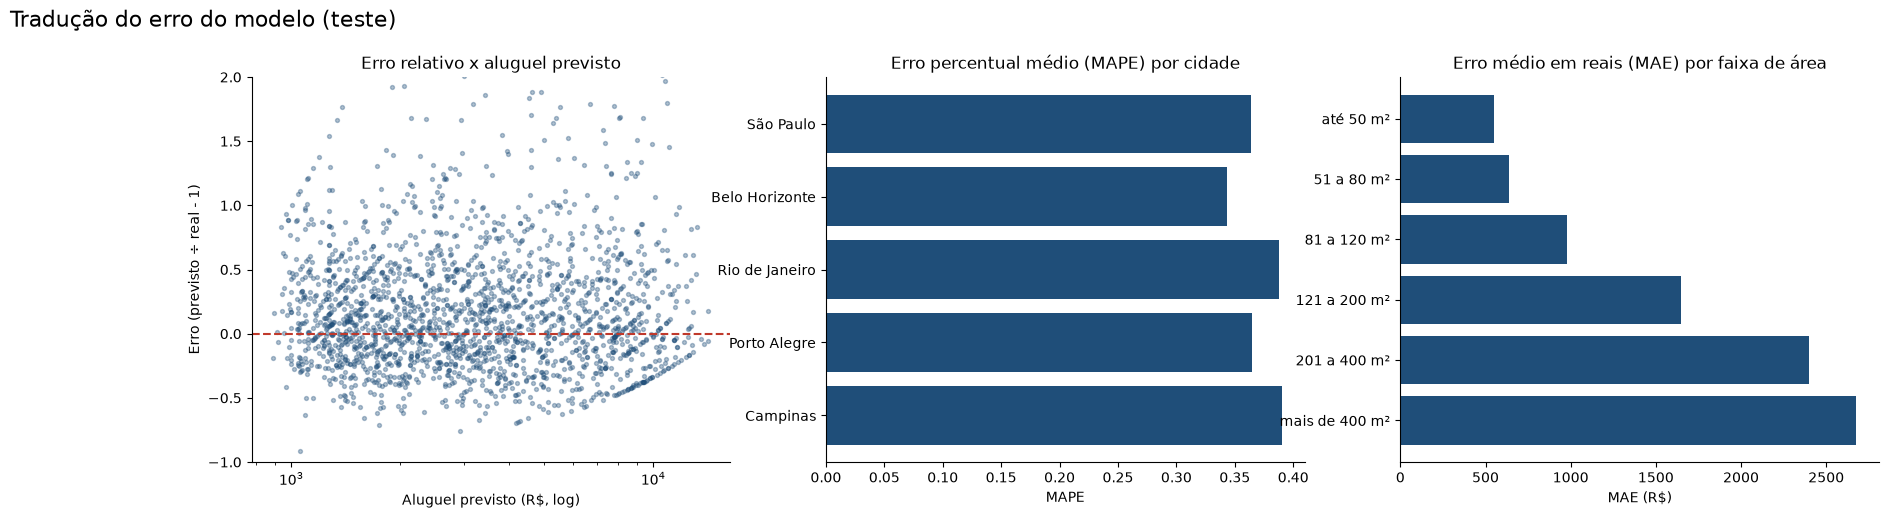

In [62]:
traducao_cidade = erro_por_grupo(y_teste, previsto_teste, X_teste['cidade'])
traducao_area = erro_por_grupo(y_teste, previsto_teste, faixa_area(X_teste['area'])).sort_index()
traducao_cidade.to_csv('../reports/erro_por_cidade.csv')
traducao_area.to_csv('../reports/erro_por_faixa_de_area.csv')

formato_traducao = {'aluguel_real': reais, 'aluguel_previsto': reais, 'MAE': reais, 'MAPE': '{:.1%}',
                    'pior cenário': reais, 'melhor cenário': reais}
print('POR CIDADE')
display(traducao_cidade.style.format(formato_traducao))
print('POR FAIXA DE ÁREA')
display(traducao_area.style.format(formato_traducao))

fig, axs = plt.subplots(1, 3, figsize=(21, 5))
erro = previsto_teste - y_teste
axs[0].scatter(previsto_teste, erro / y_teste, s=8, alpha=0.35, color=COR_PRINCIPAL)
axs[0].axhline(0, color=COR_DESTAQUE, ls='--')
axs[0].set(xscale='log', ylim=(-1, 2), title='Erro relativo x aluguel previsto', xlabel='Aluguel previsto (R$, log)',
           ylabel='Erro (previsto ÷ real - 1)')
axs[1].barh(traducao_cidade.index, traducao_cidade['MAPE'], color=COR_PRINCIPAL)
axs[1].invert_yaxis()
axs[1].set(title='Erro percentual médio (MAPE) por cidade', xlabel='MAPE')
axs[2].barh(traducao_area.index.astype(str), traducao_area['MAE'], color=COR_PRINCIPAL)
axs[2].invert_yaxis()
axs[2].set(title='Erro médio em reais (MAE) por faixa de área', xlabel='MAE (R$)')
sns.despine()
titulo('Tradução do erro do modelo (teste)')
salvar('Traducao do erro')
plt.show()

📌 **Nota**
- 🔎 **Por cidade**, o erro em reais acompanha o preço: **R$ 1.478** em São Paulo (aluguel médio de R$ 4.757) e **R$ 724** em Campinas (R$ 2.323). Em porcentagem, as cidades ficam parecidas: de **34,3%** (Belo Horizonte) a **39,0%** (Campinas).
- 🔎 **Cenários:** em São Paulo, o aluguel médio previsto é **R$ 4.826**, com pior cenário de **R$ 3.348** e melhor de **R$ 6.305**. Em Porto Alegre, de **R$ 1.485** a **R$ 3.035**.
- 🔎 **Por tamanho**, os imóveis de **51 a 80 m²** (os mais comuns) têm o menor erro relativo (**30,7%**). Os de **201 a 400 m²** têm o maior (**43,6%**): nessa faixa estão desde casas simples na periferia até apartamentos de alto padrão, e é onde mais pesa o teto de R$ 15 mil (item 2.7).
- 🔎 O gráfico da esquerda mostra o erro relativo **centrado em zero** em todas as faixas de preço.
- 💡 **Para o negócio:** a sugestão é mais confiável para **apartamentos pequenos e médios** (até 120 m²). Para imóveis grandes, ela serve como **ponto de partida** para a avaliação de um corretor.

## 3 - Quais variáveis mais influenciam o modelo?

Usamos a **importância por permutação**: embaralhamos uma variável de cada vez no teste e medimos **quanto o erro piora**. Quanto mais o erro piora, mais o modelo depende daquela variável.

area             +R$ 544
iptu             +R$ 223
condominio       +R$ 208
banheiros        +R$ 110
mobiliado         +R$ 82
cidade            +R$ 76
andar             +R$ 58
quartos           +R$ 34
vagas             +R$ 23
iptu_zero           R$ 0
eh_casa             R$ 0
aceita_animal      −R$ 1


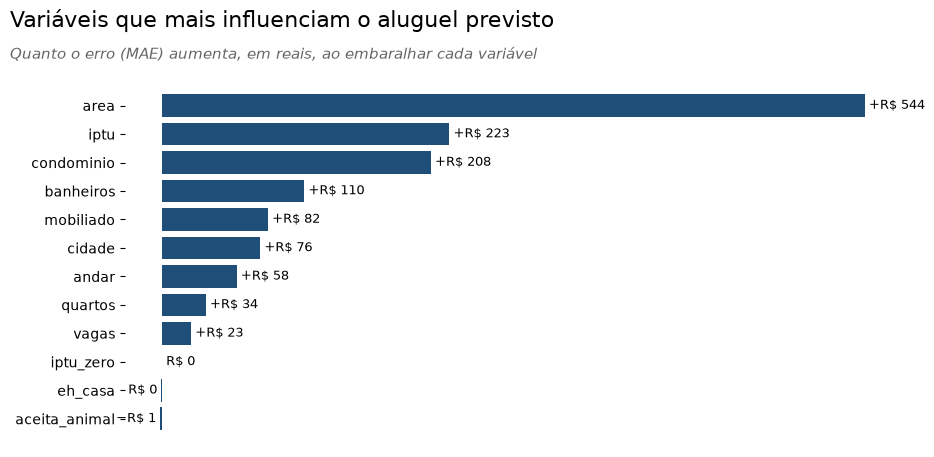

In [63]:
importancia = permutation_importance(modelo_final, X_teste, y_teste, scoring='neg_mean_absolute_error',
                                     n_repeats=20, random_state=SEMENTE, n_jobs=N_JOBS)
importancia = pd.Series(importancia.importances_mean, index=X_teste.columns)
com_sinal = lambda v: ('+' if v >= 0.5 else '−' if v <= -0.5 else '') + reais(abs(v))
print(importancia.sort_values(ascending=False).map(com_sinal).to_string())

plot_barras_h(importancia, 'Variáveis que mais influenciam o aluguel previsto', 'Importancia por permutacao',
              subtitulo='Quanto o erro (MAE) aumenta, em reais, ao embaralhar cada variável',
              formato=com_sinal)

In [64]:
# Efeito isolado: o mesmo imóvel típico, mudando uma característica de cada vez
tipico = imovel_para_modelo(dict(cidade='São Paulo', area=70, quartos=2, banheiros=2, vagas=1, andar=5, aceita_animal=1,
                                 mobiliado=0, condominio=700, iptu=100))
cenarios_efeito = {'Imóvel típico (SP, 70 m², 2 quartos)': tipico}
for nome, mudanca in [('Mobiliado', {'mobiliado': 1}), ('Área de 100 m²', {'area': 100}), ('+1 banheiro', {'banheiros': 3}),
                      ('+1 vaga', {'vagas': 2}), ('Em Porto Alegre', {'cidade': 'Porto Alegre'}),
                      ('Condomínio de R$ 1.200', {'condominio': 1200})]:
    cenarios_efeito[nome] = tipico.assign(**mudanca)
efeitos = pd.Series({nome: modelo_final.predict(dados)[0] for nome, dados in cenarios_efeito.items()})
efeitos.to_frame('aluguel previsto').assign(**{'vs típico': efeitos / efeitos.iloc[0] - 1}).style.format(
    {'aluguel previsto': reais, 'vs típico': '{:+.0%}'})

,aluguel previsto,vs típico
"Imóvel típico (SP, 70 m², 2 quartos)",R$ 2.114,+0%
Mobiliado,R$ 3.044,+44%
Área de 100 m²,R$ 2.681,+27%
+1 banheiro,R$ 2.499,+18%
+1 vaga,R$ 2.156,+2%
Em Porto Alegre,R$ 1.530,-28%
Condomínio de R$ 1.200,R$ 2.933,+39%


📌 **Nota**
- 🔎 A **área** é, de longe, a variável mais importante: embaralhá-la aumenta o erro em **R$ 544** por imóvel. Em seguida vêm o **IPTU** (**+R$ 223**) e o **condomínio** (**+R$ 208**), que medem o padrão do imóvel e do prédio, e os **banheiros** (**+R$ 110**).
- 🔎 **Mobília** (**+R$ 82**) e **cidade** (**+R$ 76**) vêm logo depois. Quartos (**+R$ 34**) e vagas (**+R$ 23**) acrescentam pouco, porque a área e os banheiros já carregam essa informação.
- 🔎 `aceita_animal`, `eh_casa` e `iptu_zero` ficam em **zero**: o modelo não depende delas (a H4 e a confirmação do item 4.3 da Fase 03 já indicavam isso).
- 🔎 **Efeito isolado** no mesmo imóvel típico (São Paulo, 70 m², 2 quartos, R$ 2.114): ser **mobiliado** soma **+44%**; ter **100 m²**, **+27%**; ter **condomínio de R$ 1.200** (prédio de padrão mais alto), **+39%**; **+1 banheiro**, **+18%**; **+1 vaga**, só **+2%**. O mesmo imóvel em **Porto Alegre** sai **28% mais barato**.
- ⚠️ Esses efeitos são **associações** que o modelo aprendeu, não causas: um condomínio caro não encarece o aluguel por si só, ele indica um prédio melhor.

#### SHAP: quanto cada variável empurrou cada previsão

A permutação diz **quais** variáveis o modelo usa, mas não **para que lado** nem **em quais imóveis**. O **SHAP** (baseado nos valores de Shapley, da teoria dos jogos) reparte cada previsão entre as variáveis: começa no **valor base** (o aluguel médio previsto) e soma a contribuição de cada variável, em reais, até chegar à previsão daquele imóvel.

| Propriedade | O que garante |
|---|---|
| **Eficiência** | valor base + soma das contribuições = previsão: nenhuma parte fica sem explicação |
| **Simetria** | variáveis com o mesmo efeito recebem a mesma contribuição |
| **Aditividade** | funciona com modelos de várias árvores, somando a contribuição de cada uma |

Usamos o **TreeExplainer**, o cálculo exato e rápido para modelos de árvores, numa amostra de 500 imóveis do teste. O SHAP trabalha na tabela que o modelo recebe de fato, em que a cidade vira uma coluna 0/1 por cidade.

In [65]:
transformador = modelo_final.named_steps['transformacao']
amostra_shap = X_teste.sample(500, random_state=SEMENTE)
X_shap = pd.DataFrame(transformador.transform(amostra_shap), columns=transformador.get_feature_names_out(), index=amostra_shap.index)
explainer = shap.TreeExplainer(modelo_final.named_steps['modelo'])
valores_shap = explainer.shap_values(X_shap)
valor_base = float(np.ravel(explainer.expected_value)[0])
print(f'Matriz SHAP: {valores_shap.shape[0]} imóveis x {valores_shap.shape[1]} colunas | valor base: {reais(valor_base)}')

# Eficiência: valor base + soma das contribuições = previsão do modelo (diferença ~0, só arredondamento)
previsto_amostra = modelo_final.predict(amostra_shap)
print(f'Maior diferença entre (valor base + soma dos SHAP) e a previsão: R$ {np.abs(valor_base + valores_shap.sum(axis=1) - previsto_amostra).max():.8f}')

# Importância global: contribuição média em reais (a cidade soma as suas 5 colunas 0/1) x importância por permutação
shap_por_coluna = pd.DataFrame(valores_shap, columns=X_shap.columns)
shap_por_variavel = shap_por_coluna.T.groupby(lambda c: 'cidade' if c.startswith('cidade_') else c).sum().T
importancia_shap = shap_por_variavel.abs().mean()
pd.DataFrame({'SHAP: contribuição média (R$)': importancia_shap, 'Permutação: erro a mais (R$)': importancia}).sort_values(
    'SHAP: contribuição média (R$)', ascending=False).style.format(reais)

Matriz SHAP: 500 imóveis x 16 colunas | valor base: R$ 3.970
Maior diferença entre (valor base + soma dos SHAP) e a previsão: R$ 0.00000000


,SHAP: contribuição média (R$),Permutação: erro a mais (R$)
area,R$ 1.323,R$ 544
iptu,R$ 555,R$ 223
banheiros,R$ 371,R$ 110
condominio,R$ 361,R$ 208
mobiliado,R$ 314,R$ 82
cidade,R$ 185,R$ 76
andar,R$ 146,R$ 58
vagas,R$ 92,R$ 23
quartos,R$ 68,R$ 34
aceita_animal,R$ 27,R$ -1


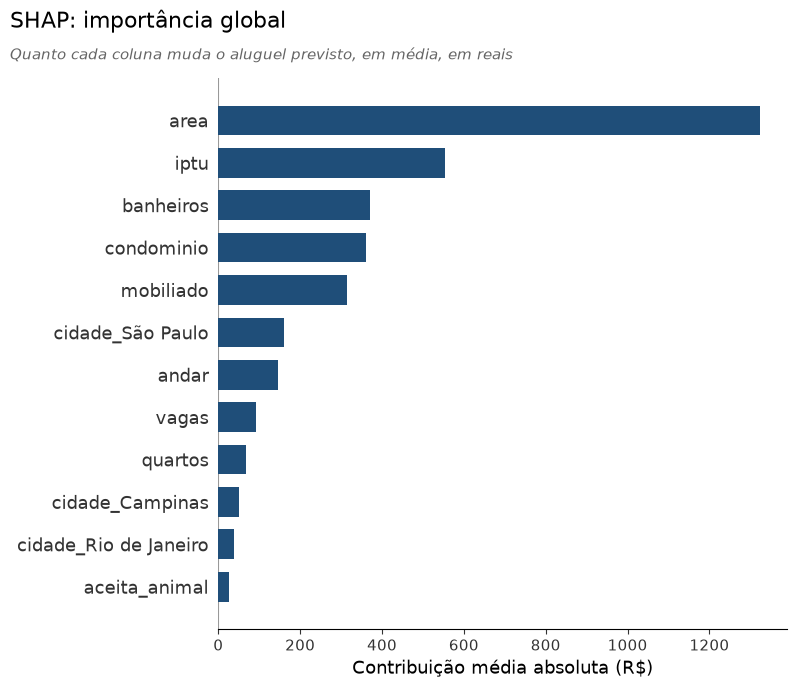

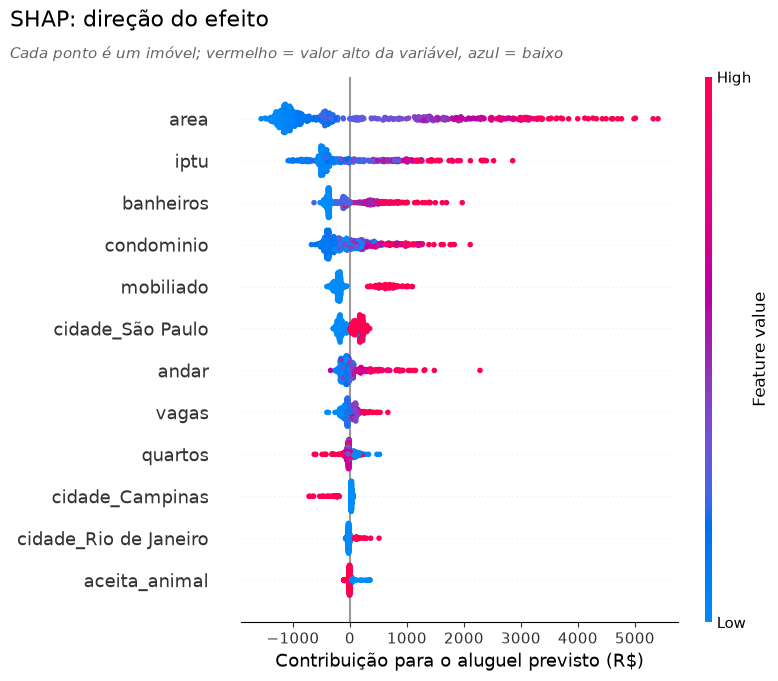

In [66]:
plt.figure()
shap.summary_plot(valores_shap, X_shap, plot_type='bar', max_display=12, show=False, color=COR_PRINCIPAL)
plt.xlabel('Contribuição média absoluta (R$)')
titulo('SHAP: importância global', 'Quanto cada coluna muda o aluguel previsto, em média, em reais')
salvar('SHAP importancia global')
plt.show()

plt.figure()
shap.summary_plot(valores_shap, X_shap, max_display=12, show=False)
plt.xlabel('Contribuição para o aluguel previsto (R$)')
titulo('SHAP: direção do efeito', 'Cada ponto é um imóvel; vermelho = valor alto da variável, azul = baixo')
salvar('SHAP beeswarm')
plt.show()

📌 **Nota**
- 🔎 **Eficiência conferida:** nos 500 imóveis, o valor base (**R$ 3.970**, o aluguel médio previsto) mais a soma das contribuições dá exatamente a previsão (diferença de **R$ 0,00**). Cada real da previsão é atribuído a alguma variável.
- 🔎 As **6 primeiras** variáveis são as mesmas da permutação: **área** (contribuição média de **R$ 1.323**), **IPTU** (R$ 555), **banheiros** (R$ 371), **condomínio** (R$ 361), **mobília** (R$ 314) e **cidade** (R$ 185). Banheiros e condomínio trocam de lugar porque os dois métodos medem coisas diferentes: o SHAP mede **quanto a variável move a previsão**; a permutação, **quanto o erro piora sem ela**. Os banheiros movem bastante a previsão, mas a área já carrega parte dessa informação, então tirá-los piora menos o erro.
- 🔎 **Direção do efeito** (gráfico de pontos): área grande (vermelho) soma até **+R$ 5.000**; área pequena tira até **R$ 1.500**. Ser **mobiliado** soma sempre (de cerca de +R$ 300 a +R$ 1.100). Estar em **Campinas** tira de R$ 300 a R$ 800. Nos **quartos**, o vermelho fica à **esquerda**: com a mesma área, mais quartos significam cômodos menores e aluguel um pouco menor.
- 🔎 `aceita_animal`, `eh_casa` e `iptu_zero` quase não mexem na previsão (R$ 27, R$ 4 e R$ 3 em média), como na permutação.

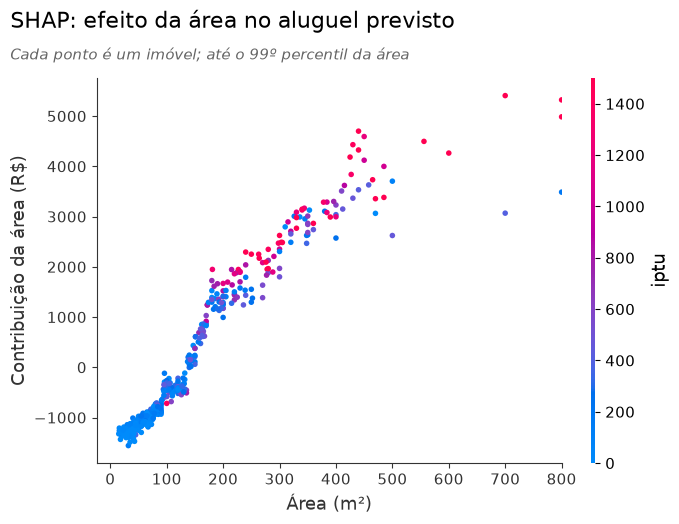

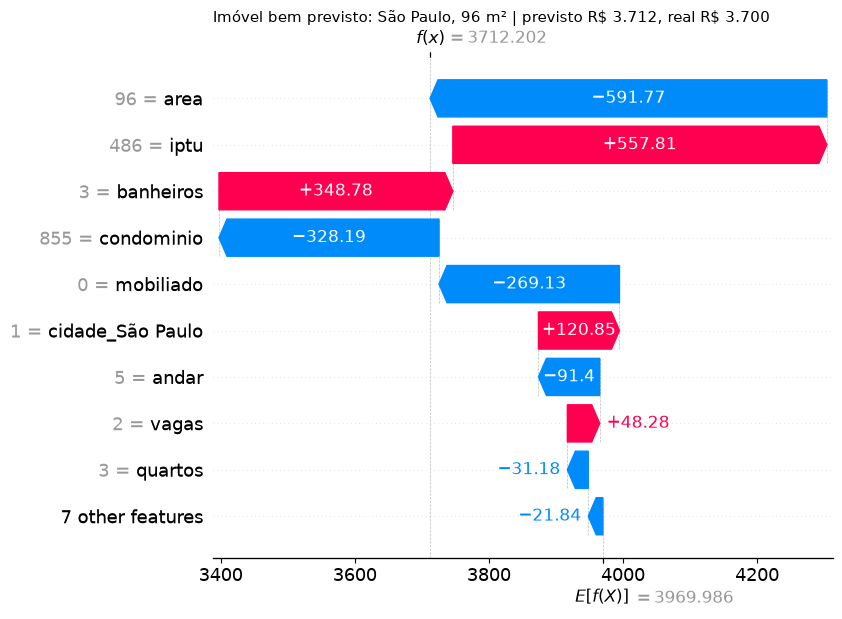

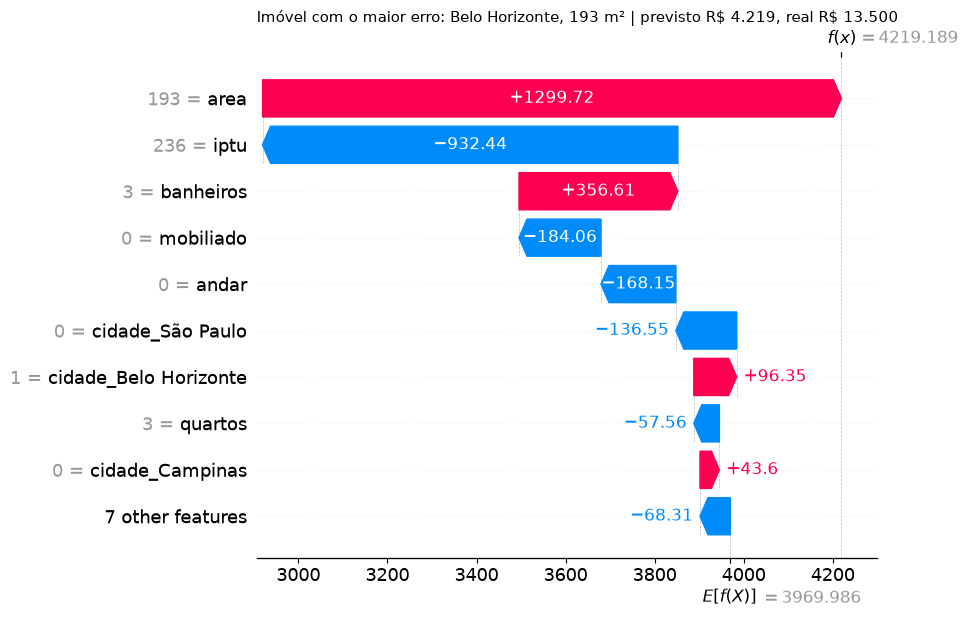

In [67]:
# Dependence plot: como a contribuição da área muda com a área (cor: a variável que mais interage com ela)
shap.dependence_plot('area', valores_shap, X_shap, xmax='percentile(99)', show=False)
plt.xlabel('Área (m²)')
plt.ylabel('Contribuição da área (R$)')
titulo('SHAP: efeito da área no aluguel previsto', 'Cada ponto é um imóvel; até o 99º percentil da área')
salvar('SHAP dependence area')
plt.show()

# Waterfall: a previsão de dois imóveis, passo a passo, do valor base até o aluguel previsto
real_amostra = y_teste.loc[amostra_shap.index].to_numpy()
erro_relativo = np.abs(previsto_amostra / real_amostra - 1)
for rotulo, posicao in [('bem previsto', int(np.argmin(np.where(real_amostra > 2500, erro_relativo, np.inf)))),
                        ('com o maior erro', int(np.argmax(np.abs(previsto_amostra - real_amostra))))]:
    explicacao = shap.Explanation(values=valores_shap[posicao], base_values=valor_base, data=X_shap.iloc[posicao].values,
                                  feature_names=list(X_shap.columns))
    shap.plots.waterfall(explicacao, max_display=10, show=False)
    imovel = amostra_shap.iloc[posicao]
    plt.title(f"Imóvel {rotulo}: {imovel['cidade']}, {imovel['area']:.0f} m² | previsto {reais(previsto_amostra[posicao])}, "
              f"real {reais(real_amostra[posicao])}".replace('$', r'\$'), loc='left', fontsize=11)  # \$: senão vira fórmula
    salvar(f'SHAP waterfall {rotulo}')
    plt.show()

📌 **Nota**
- 🔎 **Efeito da área:** a contribuição sobe quase em linha reta, de cerca de **−R$ 1.300** nos imóveis de até 50 m² para **+R$ 3.000** perto de 350 m², e cresce mais devagar acima de 400 m² (poucos imóveis e o teto de R$ 15 mil). Entre **130 e 200 m²** há um salto: é a passagem de apartamento médio para imóvel grande.
- 🔎 **Interação:** a cor é o **IPTU**, a variável que o SHAP identificou como a que mais interage com a área. Nos imóveis grandes, os de IPTU alto (vermelho) ganham mais com a área que os de IPTU baixo (azul): acima de 600 m², cerca de **+R$ 5.000** contra **+R$ 3.000**. Ou seja, **o metro quadrado vale mais em imóveis de alto padrão**.
- 🔎 **Imóvel bem previsto** (São Paulo, 96 m², previsto **R$ 3.712**, real **R$ 3.700**): parte de R$ 3.970; o IPTU de R$ 486 soma **+R$ 558** e os 3 banheiros **+R$ 349**; a área (abaixo da média da base) tira **R$ 592**, o condomínio de R$ 855 tira **R$ 328** e não ser mobiliado, **R$ 269**.
- 🔎 **Imóvel com o maior erro** (Belo Horizonte, 193 m², previsto **R$ 4.219**, real **R$ 13.500**): a área soma **+R$ 1.300**, mas o IPTU de **R$ 236**, baixo para o tamanho, tira **R$ 932**. O modelo leu "imóvel grande de padrão simples"; o anúncio pede o triplo. Ou é um imóvel de alto padrão com IPTU baixo, ou é um erro no aluguel, como os do item 2. O SHAP mostra **por que** o modelo errou, o primeiro passo para corrigir.
- 💡 **Para comunicar:** o waterfall é a explicação que uma imobiliária pode mostrar ao proprietário ("o tamanho soma R$ 1.300, o IPTU baixo indica um padrão mais simples..."); o gráfico de barras serve para todos os públicos.

# FASE 05: IMPLANTAÇÃO

## 1 - Salvando o modelo

In [68]:
joblib.dump({'modelo': modelo_final, 'faixa': faixa, 'features': FEATURES}, '../Model/modelo_aluguel.pkl')

metricas_teste = ml_error('teste', y_teste, previsto_teste).iloc[0]
ficha = salvar_ficha_modelo(
    '../Model/modelo_aluguel.json',
    modelo=f'{melhor_modelo} ajustado (Pipeline: one-hot da cidade + {melhor_modelo})',
    arquivo='modelo_aluguel.pkl',
    treinado_com=f'{len(X_treino_val):,} anúncios (treino + validação) de 5 cidades'.replace(',', '.'),
    colunas_de_entrada=FEATURES, alvo='aluguel mensal (R$), sem condomínio, IPTU e seguro',
    faixa_de_erro_80={'multiplicador_inferior': round(faixa[0], 3), 'multiplicador_superior': round(faixa[1], 3)},
    metricas_no_teste={k: round(float(v), 4) for k, v in metricas_teste.items()},
    hiperparametros={k.replace('modelo__', ''): (round(v, 4) if isinstance(v, float) else v) for k, v in melhores_params.items()},
    metodo_de_ajuste=f'{metodo_escolhido} (menor MAE na validação cruzada de 5 partes do treino)',
    avisos=['Base de anúncios de 2020: os valores não incluem a inflação dos aluguéis desde então.',
            'Vale só para as 5 cidades da base e para imóveis dentro dos limites das regras de qualidade (src/config.py).',
            'Não use seguro-incêndio nem total como entrada: são calculados a partir do aluguel (vazamento).',
            'O preço é o ANUNCIADO, não o valor fechado no contrato.'],
)
ficha

{'data_treino': '2026-10-30 20:56',
 'modelo': 'HistGradientBoosting ajustado (Pipeline: one-hot da cidade + HistGradientBoosting)',
 'arquivo': 'modelo_aluguel.pkl',
 'treinado_com': '8.257 anúncios (treino + validação) de 5 cidades',
 'colunas_de_entrada': ['cidade',
  'area',
  'quartos',
  'banheiros',
  'vagas',
  'andar',
  'aceita_animal',
  'mobiliado',
  'condominio',
  'iptu',
  'eh_casa',
  'iptu_zero'],
 'alvo': 'aluguel mensal (R$), sem condomínio, IPTU e seguro',
 'faixa_de_erro_80': {'multiplicador_inferior': 0.563,
  'multiplicador_superior': 1.573},
 'metricas_no_teste': {'MAE (R$)': 1249.0025,
  'MAPE': 0.3669,
  'RMSE (R$)': 1970.9642,
  'R²': 0.6534,
  'MPE': 0.1822},
 'hiperparametros': {'min_samples_leaf': 40,
  'max_leaf_nodes': 15,
  'max_iter': 400,
  'learning_rate': 0.02,
  'l2_regularization': 10},
 'metodo_de_ajuste': 'Random Search (menor MAE na validação cruzada de 5 partes do treino)',
 'avisos': ['Base de anúncios de 2020: os valores não incluem a infla

📌 **Nota**
- 🔎 `Model/modelo_aluguel.pkl` guarda o **pipeline completo** (one-hot da cidade + HistGradientBoosting), a **faixa relativa** de 80% e a lista de colunas, para o app mostrar a sugestão com margem.
- 🔎 `Model/modelo_aluguel.json` é a **ficha do modelo**: colunas de entrada, alvo, métricas no teste, hiperparâmetros e **avisos de uso** (base de 2020, só 5 cidades, preço anunciado e não fechado).

## 2 - Aplicando uma simulação

In [69]:
modelo_salvo = joblib.load('../Model/modelo_aluguel.pkl')

novos_imoveis = pd.concat([imovel_para_modelo(imovel) for imovel in [
    dict(cidade='São Paulo', area=45, quartos=1, banheiros=1, vagas=0, andar=8, aceita_animal=1, mobiliado=1,
         condominio=550, iptu=60),
    dict(cidade='Belo Horizonte', area=90, quartos=3, banheiros=2, vagas=2, andar=4, aceita_animal=1, mobiliado=0,
         condominio=450, iptu=120),
    dict(cidade='Porto Alegre', area=150, quartos=3, banheiros=2, vagas=2, andar=0, aceita_animal=1, mobiliado=0,
         condominio=0, iptu=150, eh_casa=1),
    dict(cidade='Rio de Janeiro', area=250, quartos=4, banheiros=4, vagas=2, andar=12, aceita_animal=0, mobiliado=1,
         condominio=2500, iptu=700),
]], ignore_index=True)
novos_imoveis.index = ['Studio mobiliado em SP', 'Apartamento familiar em BH', 'Casa em Porto Alegre', 'Cobertura no Rio']

previsao = modelo_salvo['modelo'].predict(novos_imoveis[modelo_salvo['features']])
novos_imoveis['aluguel sugerido'] = [reais(v) for v in previsao]
novos_imoveis['faixa (80%)'] = [f"{reais(v * modelo_salvo['faixa'][0])} a {reais(v * modelo_salvo['faixa'][1])}" for v in previsao]
novos_imoveis[['cidade', 'area', 'quartos', 'mobiliado', 'eh_casa', 'aluguel sugerido', 'faixa (80%)']]

,cidade,area,quartos,mobiliado,eh_casa,aluguel sugerido,faixa (80%)
Studio mobiliado em SP,São Paulo,45,1,1,0,R$ 2.628,R$ 1.478 a R$ 4.134
Apartamento familiar em BH,Belo Horizonte,90,3,0,0,R$ 1.762,R$ 992 a R$ 2.773
Casa em Porto Alegre,Porto Alegre,150,3,0,1,R$ 2.736,R$ 1.539 a R$ 4.305
Cobertura no Rio,Rio de Janeiro,250,4,1,0,R$ 8.918,R$ 5.018 a R$ 14.031


📌 **Nota**
- 🔎 O modelo salvo reproduz os padrões da análise: um **studio mobiliado de 45 m² em São Paulo** sai por **R$ 2.628**, mais caro que um **apartamento de 90 m² e 3 quartos em Belo Horizonte** (**R$ 1.762**): cidade e mobília pesam (H1, H3 e H6).
- 🔎 Uma **casa de 150 m² em Porto Alegre** fica em **R$ 2.736**, e uma **cobertura de 250 m² no Rio**, em **R$ 8.918**.
- 🔎 Cada sugestão vem com a **faixa de 80%** (ex.: cobertura no Rio entre **R$ 5.018 e R$ 14.031**), para deixar claro que é uma estimativa, não um valor exato.

## 3 - Monitoramento em produção

A validação não termina quando o modelo vai para o ar: o mercado muda e o modelo envelhece. Há dois tipos de mudança:

| Tipo | O que muda | Exemplo aqui | Como detectar |
|---|---|---|---|
| **Data drift** | a distribuição das **entradas** | condomínios e IPTU sobem com a inflação | comparar as entradas novas com as do treino (**PSI** e teste **K-S**) |
| **Concept drift** | a **relação** entre entradas e aluguel | depois da pandemia, imóveis maiores valorizam mais | acompanhar o erro quando o aluguel fechado for conhecido |

**PSI** (*Population Stability Index*): divide a variável em 10 faixas pelo treino e mede o quanto a proporção de imóveis em cada faixa mudou. Abaixo de **0,10**, estável; de 0,10 a **0,25**, mudança moderada; acima de 0,25, mudança forte (retreinar). O **K-S** testa se as duas distribuições são iguais; com muitos dados, ele aponta até mudanças pequenas, por isso o PSI decide.

> 🚫 **Backtest no tempo (walk-forward): não se aplica.** Os anúncios não têm data (são um retrato de 2020), então não há "passado" para treinar e "futuro" para testar. No projeto Rossmann, que tem datas, a validação é feita em janelas de tempo.

In [70]:
numericas_monitoradas = ['area', 'quartos', 'banheiros', 'vagas', 'andar', 'condominio', 'iptu']
formato_drift = {'PSI': '{:.3f}', 'K-S': '{:.3f}', 'p-valor (K-S)': '{:.3f}'}

# 1) Linha de base: o teste (mesma época do treino) deve ser estável
drift_teste = relatorio_drift(X_treino_val, X_teste, numericas_monitoradas)
print('TREINO x TESTE (mesma base de 2020)')
display(drift_teste.style.format(formato_drift))

# 2) Simulação: os mesmos imóveis anos depois, com condomínio e IPTU 30% mais caros (e o aluguel parado)
X_futuro = X_teste.assign(condominio=X_teste['condominio'] * 1.3, iptu=X_teste['iptu'] * 1.3)
drift_futuro = relatorio_drift(X_treino_val, X_futuro, numericas_monitoradas)
print('TREINO x SIMULAÇÃO (condomínio e IPTU +30%)')
display(drift_futuro.head(4).style.format(formato_drift))
previsto_futuro = modelo_final.predict(X_futuro)
print(f'Aluguel previsto médio: {reais(previsto_teste.mean())} -> {reais(previsto_futuro.mean())} '
      f'({previsto_futuro.mean() / previsto_teste.mean() - 1:+.1%}), com os mesmos imóveis')

TREINO x TESTE (mesma base de 2020)


,PSI,Status (PSI),K-S,p-valor (K-S),K-S indica mudança
condominio,0.005,estável,0.016,0.756,False
area,0.003,estável,0.023,0.345,False
iptu,0.003,estável,0.011,0.980,False
andar,0.001,estável,0.015,0.816,False
banheiros,0.001,estável,0.013,0.922,False
quartos,0.001,estável,0.012,0.970,False
vagas,0.001,estável,0.006,1.000,False


TREINO x SIMULAÇÃO (condomínio e IPTU +30%)


,PSI,Status (PSI),K-S,p-valor (K-S),K-S indica mudança
iptu,0.047,estável,0.078,0.000,True
condominio,0.045,estável,0.089,0.000,True
area,0.003,estável,0.023,0.345,False
andar,0.001,estável,0.015,0.816,False


Aluguel previsto médio: R$ 3.977 -> R$ 4.296 (+8.0%), com os mesmos imóveis


In [71]:
# SLA: o erro aceitável em produção (MAE do teste + 10%), conferido lote a lote quando o aluguel fechado for conhecido
sla_mae = mean_absolute_error(y_teste, previsto_teste) * 1.10
lotes = np.array_split(np.random.default_rng(SEMENTE).permutation(len(X_teste)), 5)
monitor = [{'Lote': f'Lote {n}', 'Imóveis': len(idx), 'MAE (R$)': mean_absolute_error(y_teste.iloc[idx], previsto_teste[idx])}
           for n, idx in enumerate(lotes, 1)]
monitor.append({'Lote': 'Simulação (+30% cond./IPTU)', 'Imóveis': len(X_futuro), 'MAE (R$)': mean_absolute_error(y_teste, previsto_futuro)})
monitor = pd.DataFrame(monitor).set_index('Lote')
monitor['Situação'] = np.where(monitor['MAE (R$)'] <= sla_mae, '✅ dentro do SLA', '🚨 alerta: investigar e retreinar')
print(f'SLA: MAE de até {reais(sla_mae)}')
monitor.style.format({'MAE (R$)': reais})

SLA: MAE de até R$ 1.374


,Imóveis,MAE (R$),Situação
Lote,,,
Lote 1,413,R$ 1.249,✅ dentro do SLA
Lote 2,413,R$ 1.276,✅ dentro do SLA
Lote 3,413,R$ 1.271,✅ dentro do SLA
Lote 4,413,R$ 1.219,✅ dentro do SLA
Lote 5,413,R$ 1.230,✅ dentro do SLA
Simulação (+30% cond./IPTU),2065,R$ 1.358,✅ dentro do SLA


📌 **Nota**
- 🔎 **Linha de base:** entre o treino e o teste, todas as variáveis têm PSI de no máximo **0,005** e o K-S não aponta mudança: **estável**, como esperado para dados da mesma época.
- 🔎 **Simulação de inflação (+30% no condomínio e no IPTU):** o K-S detecta a mudança (p-valor < 0,001), mas o PSI fica em só **0,045 a 0,047**, ainda "estável". As faixas do PSI são largas (10% dos imóveis cada) e uma alta de 30% só tira de faixa uma parte dos imóveis. O PSI foi pensado para mudanças grandes de perfil; para mudanças graduais, como a inflação, vale acompanhar também o **K-S** e a **mediana** das variáveis.
- 🔎 **O efeito no modelo é real:** com os mesmos imóveis, o aluguel previsto médio sobe **8,0%** (de **R$ 3.977** para **R$ 4.296**) só porque condomínio e IPTU subiram: o modelo lê isso como "padrão mais alto". O MAE vai de **R$ 1.249** para **R$ 1.358**, perto do limite do SLA (**R$ 1.374**).
- 🔎 Nos 5 lotes do teste, o MAE varia de **R$ 1.219** a **R$ 1.276**: é a variação natural entre grupos de ~400 imóveis. Por isso o SLA tem uma folga de 10% sobre o MAE do teste.
- ✅ **Proposta para produção:** acompanhar PSI, K-S e mediana das entradas todo mês e o MAE por lote quando o aluguel fechado for conhecido; **retreinar** se o PSI passar de 0,25, se o MAE ficar acima do SLA em dois lotes seguidos ou depois de corrigir os valores pela inflação do aluguel (IVAR).

# ✅ RESPOSTA À PERGUNTA DE NEGÓCIO

| # | Pergunta | Resposta | Onde está |
|---|---|---|---|
| 1 | Quanto cobrar de aluguel, e com que margem? | O modelo sugere o aluguel com erro médio de **R$ 1.249** (**37%**), R² de **0,65**, e uma faixa em que o aluguel real fica **8 em cada 10 vezes** (56% a 157% do previsto, **81%** de acerto no teste) | Fase 03 (itens 7 e 8) e Fase 04 |
| 2 | O que mais encarece um aluguel? | **Área**, depois **IPTU e condomínio** (padrão do imóvel), **banheiros**, **mobília** e **cidade**. No mesmo imóvel típico, mobiliar soma **+44%**; em Porto Alegre, ele custa **28% menos** que em SP | Fase 04 (item 3) e H1 a H10 |
| 3 | Onde a sugestão é mais confiável? | Em **apartamentos de 51 a 80 m²** (erro de 31%); em porcentagem, as 5 cidades ficam parecidas (34% a 39%) | Fase 04 (item 2) |
| 4 | Quais anúncios estão fora do preço esperado? | **18,8%** ficam fora da faixa; os extremos parecem **erros de digitação no aluguel** (ex.: R$ 12.000 por 75 m² em Campinas) | Fase 04 (item 2) |

### As hipóteses, revisitadas

| # | Hipótese | Na EDA | No modelo |
|---|---|---|---|
| H1 / H6 | O aluguel varia por cidade | ✅ Efeito médio (épsilon² 0,13 e 0,12) | Confirmado: 6ª variável (**+R$ 76**); o mesmo imóvel custa **28% menos** em Porto Alegre |
| H2 | Maior área, maior aluguel | ✅ Forte (rho 0,73) | Confirmado: a variável **mais importante** (**+R$ 544**) |
| H3 | Mobiliado é mais caro | ✅ Moderado (r 0,29) | Confirmado: **+44%** no imóvel típico (**+R$ 82** na permutação) |
| H4 | Aceitar animal não muda o aluguel | ⚠️ Pequeno (r 0,11) | Confirmado: importância **zero** no modelo |
| H8 | Banheiros dizem mais que quartos | ✅ 0,72 contra 0,60 | Confirmado: banheiros **+R$ 110**, quartos **+R$ 34**, vagas **+R$ 23** |
| H10 | Condomínio e IPTU acompanham o aluguel | ✅ Forte (0,73 e 0,75) | Confirmado: IPTU e condomínio são a **2ª e a 3ª** variáveis mais importantes |

# 💡 INSIGHTS

| # | Insight | Para quem interessa |
|---|---|---|
| 1 | **O "modelo da média" da v1 colava a resposta:** a média por área calculada na própria validação chegava a R² de 0,625 e parecia o melhor modelo. Uma referência honesta tem R² zero | Qualquer analista: **a régua de comparação também precisa ser testada** |
| 2 | **12 erros de digitação** (condomínio de R$ 1,1 milhão, IPTU de R$ 313 mil, área de 46 mil m²) e **358 duplicatas** estavam no treino da v1 | Plataformas de anúncio: **validar os campos na hora do cadastro** |
| 3 | **São Paulo e Rio têm o mesmo preço por m² (~R$ 30)**; BH, Porto Alegre e Campinas ficam entre R$ 18 e R$ 22 | Investidores e quem está se mudando |
| 4 | **Mobiliar vale a pena:** com a mesma área, o mobiliado tem aluguel mediano bem maior (r 0,29), e o modelo estima **+44%** para o mesmo imóvel típico | Proprietários |
| 5 | **Banheiros dizem mais que quartos** sobre o aluguel (0,72 contra 0,60): eles medem o padrão do imóvel | Proprietários e corretores ao anunciar |
| 6 | **Por m², a casa é mais barata que o apartamento** (R$ 21 contra R$ 29) | Quem procura espaço |
| 7 | **Seguro-incêndio e total "entregam" o aluguel** (R² de 0,99 se entrarem no modelo): são calculados a partir dele | Qualquer analista: **cuidado com colunas derivadas do alvo** |
| 8 | **A base tem um teto escondido:** 231 anúncios em exatamente R$ 15.000 e só 12 acima. Acima disso, o modelo subestima | Qualquer analista: **olhar os valores mais frequentes, não só a média e o máximo** |
| 9 | **O modelo explica 65% do preço.** O resto depende do bairro, do acabamento e da conservação, que a base não tem | Quem for usar o modelo: é uma **referência**, não uma avaliação |

### Os limites, ditos com todas as letras

- **Sem bairro nem endereço:** dentro de uma cidade, a localização é o fator mais importante do preço, e a base não tem essa informação. É a principal razão do erro de 37%.
- **Anúncios de 2020:** os valores não incluem a inflação dos aluguéis desde então (o IGP-M e o IPCA subiram bastante). Para usar hoje, seria preciso corrigir os valores ou retreinar com anúncios atuais.
- **Preço anunciado, não fechado:** o aluguel do anúncio pode ser negociado para baixo.
- **Só 5 cidades:** o modelo não vale para outras cidades, nem para imóveis fora das regras de qualidade (área acima de 2.000 m², condomínio ou IPTU acima de R$ 100/m²).
- **Erros no próprio aluguel** (ex.: um zero a mais) continuam na base, porque não dá para separá-los dos imóveis realmente caros sem olhar o aluguel.
- **Teto de R$ 15 mil:** 231 anúncios têm aluguel de exatamente R$ 15.000, e só 12 passam disso. Para imóveis de alto padrão, o modelo tende a **subestimar** o preço (no gráfico previsto × real, esses anúncios formam a linha horizontal do topo).
- **Faixa larga:** a faixa de 80% vai de 56% a 157% do previsto. Ela é confiável, mas ampla.

# 🚀 PRÓXIMOS PASSOS

1. **Acrescentar a localização** (bairro ou CEP) a partir de uma base com endereço, como anúncios de portais imobiliários: é o que mais deve reduzir o erro.
2. **Tratar o teto de R$ 15 mil** como valor censurado ("15 mil ou mais"), por exemplo com um modelo de sobrevivência ou com uma segunda base sem o limite de coleta.
3. **Treinar com uma perda robusta** (`loss='absolute_error'` no HistGradientBoosting) ou com o **log do aluguel**, para diminuir o peso dos aluguéis com erro de digitação e o viés nos imóveis baratos.
4. **Faixa de erro por intervalos conformes** (*conformal prediction*), que garantem a cobertura por construção e podem variar por cidade e tamanho.
5. **Atualizar os preços:** retreinar com anúncios recentes ou corrigir os valores pela inflação do aluguel (IVAR/FGV).
6. **Publicar o app** no Streamlit Community Cloud e gravar um GIF para o README.

# 🖥️ Interface com Streamlit

Para que qualquer pessoa use o modelo **sem abrir o notebook**, criamos um app em **Streamlit** com 3 abas:
1. **Simulador:** informa as características do imóvel na barra lateral e recebe o **aluguel sugerido**, a **faixa de 80%**, o aluguel por m² comparado com a mediana da cidade e a distribuição dos **anúncios parecidos**. Imóveis fora das regras de qualidade (ex.: condomínio acima de R$ 100/m²) são recusados com o motivo.
2. **Aluguéis por cidade:** mediana do aluguel, do aluguel por m² e da área em cada cidade, e o aluguel por número de quartos.
3. **Sobre o modelo:** métricas no teste e avisos da ficha do modelo.

A célula abaixo grava o arquivo `app.py` na raiz do projeto. Para executar (a partir da raiz):

```bash
pip install -r requirements.txt
streamlit run app.py
```

In [72]:
%%writefile ../app.py
"""App Streamlit: aluguel sugerido para um imóvel (com faixa de erro) e panorama dos aluguéis em 5 cidades."""
import json
import sys
from pathlib import Path

import joblib
import pandas as pd
import plotly.express as px
import streamlit as st

RAIZ = Path(__file__).resolve().parent
sys.path.append(str(RAIZ))

from src.config import CIDADES  # noqa: E402
from src.dados import imovel_para_modelo, regras_erro  # noqa: E402

st.set_page_config(page_title='Aluguel de imóveis', page_icon='🏠', layout='wide')


@st.cache_resource
def carregar_modelo():
    pacote = joblib.load(RAIZ / 'Model' / 'modelo_aluguel.pkl')
    ficha = json.loads((RAIZ / 'Model' / 'modelo_aluguel.json').read_text(encoding='utf-8'))
    return pacote, ficha


@st.cache_data
def carregar_base():
    return pd.read_csv(RAIZ / 'Datasets' / 'imoveis_limpos.csv')


def reais(valor):
    return 'R$ ' + f'{valor:,.0f}'.replace(',', '.')


pacote, ficha = carregar_modelo()
base = carregar_base()

st.title('🏠 Quanto cobrar de aluguel?')
st.caption('Modelo treinado com 10 mil anúncios de 5 cidades (base pública do Kaggle). '
           'A previsão é uma estimativa, sempre acompanhada da faixa em que o aluguel real costuma ficar.')

aba_simulador, aba_base, aba_modelo = st.tabs(['💰 Simulador', '📊 Aluguéis por cidade', 'ℹ️ Sobre o modelo'])

with aba_simulador:
    with st.sidebar:
        st.header('Dados do imóvel')
        cidade = st.selectbox('Cidade', CIDADES)
        tipo = st.radio('Tipo', ['Apartamento', 'Casa'], horizontal=True)
        area = st.number_input('Área (m²)', min_value=10, max_value=2000, value=70, step=5)
        quartos = st.slider('Quartos', 1, 10, 2)
        banheiros = st.slider('Banheiros', 1, 10, 2)
        vagas = st.slider('Vagas de garagem', 0, 10, 1)
        andar = st.slider('Andar', 0, 51, 5, disabled=tipo == 'Casa')
        mobiliado = st.toggle('Mobiliado')
        aceita_animal = st.toggle('Aceita animal', value=True)
        condominio = st.number_input('Condomínio (R$/mês)', min_value=0, max_value=20000, value=600, step=50)
        iptu = st.number_input('IPTU (R$/mês)', min_value=0, max_value=10000, value=100, step=10)

    imovel = dict(cidade=cidade, area=area, quartos=quartos, banheiros=banheiros, vagas=vagas,
                  andar=0 if tipo == 'Casa' else andar, aceita_animal=int(aceita_animal), mobiliado=int(mobiliado),
                  condominio=condominio, iptu=iptu, eh_casa=int(tipo == 'Casa'))
    entrada = imovel_para_modelo(imovel)
    erros = regras_erro(entrada).iloc[0]

    if erros.any():
        st.error('Valores fora do padrão da base: ' + ', '.join(erros[erros].index) +
                 '. O modelo não foi treinado para esse tipo de imóvel.')
    else:
        previsto = float(pacote['modelo'].predict(entrada[pacote['features']])[0])
        inferior, superior = previsto * pacote['faixa'][0], previsto * pacote['faixa'][1]
        mesma_cidade = base[base['cidade'] == cidade]
        mediana_m2 = (mesma_cidade['aluguel'] / mesma_cidade['area']).median()

        col1, col2, col3 = st.columns(3)
        col1.metric('Aluguel sugerido', reais(previsto))
        col2.metric('Faixa provável (80%)', f'{reais(inferior)} a {reais(superior)}')
        col3.metric('Aluguel por m²', reais(previsto / area),
                    delta=f'{previsto / area / mediana_m2 - 1:+.0%} vs mediana da cidade', delta_color='off')
        st.caption(f'Em 80% dos imóveis do teste, o aluguel real ficou entre {pacote["faixa"][0]:.0%} e '
                   f'{pacote["faixa"][1]:.0%} do valor previsto.')
        if previsto > 12_000:
            st.warning('Imóvel de alto padrão: na base, quase todos os aluguéis acima de R$ 15 mil foram registrados '
                       'como R$ 15.000 (teto da coleta). Para esses imóveis, o modelo tende a subestimar o preço.')

        parecidos = mesma_cidade[(mesma_cidade['quartos'] == quartos) & (mesma_cidade['area'].between(area * 0.8, area * 1.2))]
        if len(parecidos) >= 5:
            st.subheader(f'{len(parecidos)} anúncios parecidos em {cidade}')
            st.caption(f'Mesmo número de quartos e área entre {area * 0.8:.0f} e {area * 1.2:.0f} m²')
            figura = px.histogram(parecidos, x='aluguel', nbins=30, labels={'aluguel': 'Aluguel (R$)'})
            figura.add_vline(x=previsto, line_dash='dash', line_color='#C0392B', annotation_text='sugerido')
            figura.update_layout(yaxis_title='Anúncios', height=320, margin=dict(t=20, b=20))
            st.plotly_chart(figura, use_container_width=True)

with aba_base:
    resumo = (base.assign(aluguel_m2=base['aluguel'] / base['area'])
              .groupby('cidade').agg(anuncios=('aluguel', 'size'), aluguel_mediano=('aluguel', 'median'),
                                     aluguel_m2_mediano=('aluguel_m2', 'median'), area_mediana=('area', 'median'))
              .sort_values('aluguel_m2_mediano', ascending=False))
    st.subheader('Aluguel mediano por cidade')
    st.dataframe(resumo.style.format({'aluguel_mediano': reais, 'aluguel_m2_mediano': 'R$ {:.0f}',
                                      'area_mediana': '{:.0f} m²'}), use_container_width=True)
    cidade_escolhida = st.selectbox('Ver uma cidade', CIDADES, key='cidade_base')
    dados_cidade = base[base['cidade'] == cidade_escolhida]
    figura = px.box(dados_cidade, x='quartos', y='aluguel', points=False,
                    labels={'quartos': 'Quartos', 'aluguel': 'Aluguel (R$)'},
                    title=f'Aluguel por número de quartos em {cidade_escolhida}')
    st.plotly_chart(figura, use_container_width=True)

with aba_modelo:
    metricas = ficha['metricas_no_teste']
    col1, col2, col3 = st.columns(3)
    col1.metric('Erro médio (MAE)', reais(metricas['MAE (R$)']))
    col2.metric('Erro percentual (MAPE)', f"{metricas['MAPE']:.0%}")
    col3.metric('R²', f"{metricas['R²']:.2f}")
    st.markdown(f"**Modelo:** {ficha['modelo']}  \n**Treinado com:** {ficha['treinado_com']}")
    st.markdown('**Avisos:**\n' + '\n'.join(f'- {aviso}' for aviso in ficha['avisos']))

Overwriting ../app.py
